
# Ethereum Network Activity Forecasting
## A Comparative Study of Statistical, Machine Learning, and Deep Learning Models (2015–2026)

### 1. Research Objectives

The primary objective of this project is to investigate and forecast Ethereum blockchain network activity using statistical time-series methods, machine learning algorithms, and deep learning architectures.

The study aims to:

1. Analyse historical patterns and trends in Ethereum network activity.
2. Investigate temporal characteristics, including seasonality, trend, and volatility.
3. Develop predictive models for daily Ethereum network activity.
4. Compare the predictive performance of statistical, machine learning, and deep learning models.
5. Evaluate whether deep learning approaches provide meaningful improvements over conventional forecasting methods.

### 1.1. Research Questions

This study addresses the following research questions:

1. How do Ethereum network activity indicators evolve over time?
2. What temporal patterns, including trends, seasonality, and volatility, characterize Ethereum network activity?
3. How accurately can statistical, machine learning, and deep learning models forecast daily Ethereum network activity?
4. Do machine learning and deep learning models outperform conventional statistical forecasting methods?
5. Are any improvements in predictive accuracy sufficiently meaningful to justify the additional computational complexity of advanced models?

### 1.2. Forecasting Variables

The initial candidate target variables are:

- Daily transaction count
- Daily active addresses
- Daily gas usage

The final selection will depend on data availability and quality.

### 1.3. Modelling Approaches

The study will investigate the following model families:

- Statistical models: Naïve, Seasonal Naïve, and ARIMA
- Machine learning: Random Forest and XGBoost
- Neural networks: Multilayer Perceptron (MLP)
- Deep learning: LSTM and GRU
- Advanced deep learning: Transformer-based forecasting

### 1.4. Research Methodology

The project will follow a chronological time-series forecasting framework, including exploratory data analysis, feature engineering, chronological data splitting, model development, hyperparameter optimization, and out-of-sample evaluation.

Model performance will be assessed using appropriate forecasting metrics, including MAE and RMSE.

### 1.5. Data Source

Historical Ethereum blockchain data will be obtained from the Google BigQuery public dataset:

`bigquery-public-data.goog_blockchain_ethereum_mainnet_us.transactions`

The intended study period is 2015–2026, subject to data availability and validation.


## 2. Environment Setup

This section imports the Python libraries required for data acquisition, data processing, statistical analysis, visualisation, and forecasting.

In [6]:
# Core libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Visualisation
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 20)

print("Environment setup completed successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment setup completed successfully!
Pandas version: 3.1.0
NumPy version: 2.3.5


## 3. Data Acquisition

Historical Ethereum network activity data are obtained from the Google BigQuery public blockchain dataset.

Data are queried and aggregated using SQL in the BigQuery web interface. The resulting datasets are downloaded as CSV files and imported into Python for subsequent analysis.

### 3.1 Daily Transaction Counts

In [7]:
# Import the dataset
import pandas as pd
from pathlib import Path

file_path = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\data\raw\ethereum_daily_transaction_counts.csv"
)

df_transactions = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df_transactions.shape)
display(df_transactions.head())

Dataset loaded successfully!
Shape: (4066, 2)


,block_date,daily_transaction_count
0,2015-10-01,6421
1,2015-10-02,6063
2,2015-10-03,6112
3,2015-10-04,6624
4,2015-10-05,6279


## 4. Data Quality Assessment

This section evaluates the integrity and consistency of the daily Ethereum transaction-count dataset before conducting exploratory data analysis and forecasting.

The assessment includes:
- Dataset dimensions and data types
- Date range and chronological ordering
- Missing values
- Duplicate dates and records
- Negative transaction counts
- Continuity of daily observations

In [3]:
# Basic dataset inspection

print("Dataset shape:", df_transactions.shape)

print("\nData types:")
print(df_transactions.dtypes)

print("\nDate range:")
print("First date:", df_transactions["block_date"].min())
print("Last date:", df_transactions["block_date"].max())

print("\nMissing values:")
print(df_transactions.isnull().sum())

print("\nDuplicate dates:",
      df_transactions["block_date"].duplicated().sum())

print("\nDuplicate rows:",
      df_transactions.duplicated().sum())

print("\nNegative transaction counts:",
      (df_transactions["daily_transaction_count"] < 0).sum())

Dataset shape: (4066, 2)

Data types:
block_date                   str
daily_transaction_count    int64
dtype: object

Date range:
First date: 2015-10-01
Last date: 2026-11-17

Missing values:
block_date                 0
daily_transaction_count    0
dtype: int64

Duplicate dates: 0

Duplicate rows: 0

Negative transaction counts: 0


In [4]:
# Convert date column to datetime
df_transactions["block_date"] = pd.to_datetime(
    df_transactions["block_date"]
)

# Sort observations chronologically
df_transactions = df_transactions.sort_values(
    "block_date"
).reset_index(drop=True)

# Check daily continuity
expected_dates = pd.date_range(
    start=df_transactions["block_date"].min(),
    end=df_transactions["block_date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(
    df_transactions["block_date"]
)

print("Date data type:", df_transactions["block_date"].dtype)
print("Expected daily observations:", len(expected_dates))
print("Actual observations:", len(df_transactions))
print("Missing calendar dates:", len(missing_dates))

Date data type: datetime64[us]
Expected daily observations: 4066
Actual observations: 4066
Missing calendar dates: 0


In [5]:
# Save the validated dataset
output_path = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\data\processed"
)

output_path.mkdir(parents=True, exist_ok=True)

df_transactions.to_csv(
    output_path / "ethereum_daily_transaction_counts_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 5. Exploratory Data Analysis (EDA)

This section explores the historical characteristics of Ethereum daily transaction activity over the study period, from 1 October 2015 to 17 November 2026.

The analysis examines descriptive statistics, temporal trends, distributional characteristics, variability, and potential seasonal patterns.

### 5.1 Descriptive Statistics

This subsection examines the central tendency, dispersion, and range of daily Ethereum transaction counts using descriptive statistical measures.

In [6]:
# Descriptive statistics of daily transaction counts

df_transactions["daily_transaction_count"].describe()

count    4.066000e+03
mean     9.483504e+05
std      5.783087e+05
min      5.830000e+03
25%      5.796128e+05
50%      1.052374e+06
75%      1.219666e+06
max      3.627491e+06
Name: daily_transaction_count, dtype: float64

In [7]:
# Additional distributional statistics

print("Skewness:",
      df_transactions["daily_transaction_count"].skew())

print("Kurtosis:",
      df_transactions["daily_transaction_count"].kurt())

Skewness: 0.42971392101910916
Kurtosis: 0.825054291357233


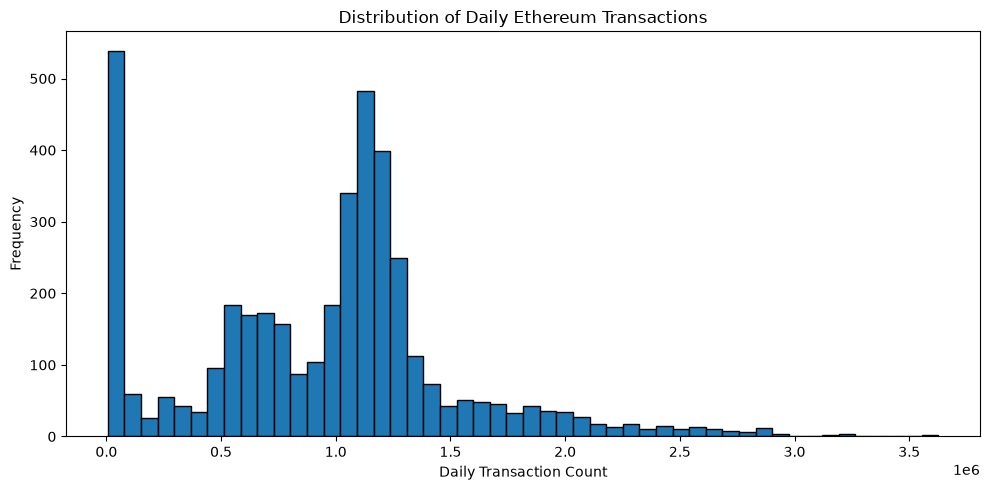

Chart 01 saved successfully!


In [8]:
# Distribution of daily transaction counts

# Create visualizations directory
visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)
visualizations_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 5))

plt.hist(
    df_transactions["daily_transaction_count"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Daily Ethereum Transactions")
plt.xlabel("Daily Transaction Count")
plt.ylabel("Frequency")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "01_transaction_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 01 saved successfully!")

### 5.2 Temporal Trend in Daily Transaction Activity

This subsection examines the evolution of daily Ethereum transaction activity over the study period. A time-series plot is used to identify long-term trends, changes in network activity, and periods of unusually high or low transaction volumes.

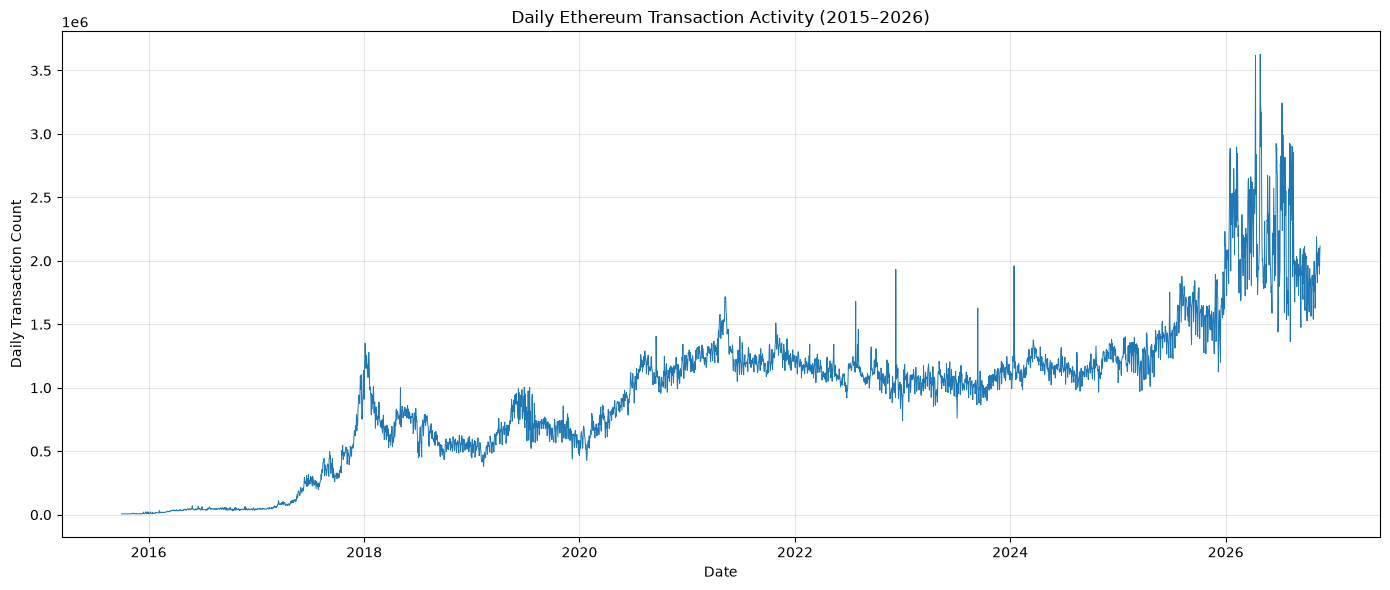

Chart 02 saved successfully!


In [9]:
# Daily Ethereum transaction activity over time

plt.figure(figsize=(14, 6))

plt.plot(
    df_transactions["block_date"],
    df_transactions["daily_transaction_count"],
    linewidth=0.7
)

plt.title("Daily Ethereum Transaction Activity (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "02_daily_transaction_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 02 saved successfully!")

### 5.3 Thirty-Day Rolling Average

A 30-day rolling average is calculated to smooth short-term fluctuations and reveal the underlying trend in daily Ethereum transaction activity.

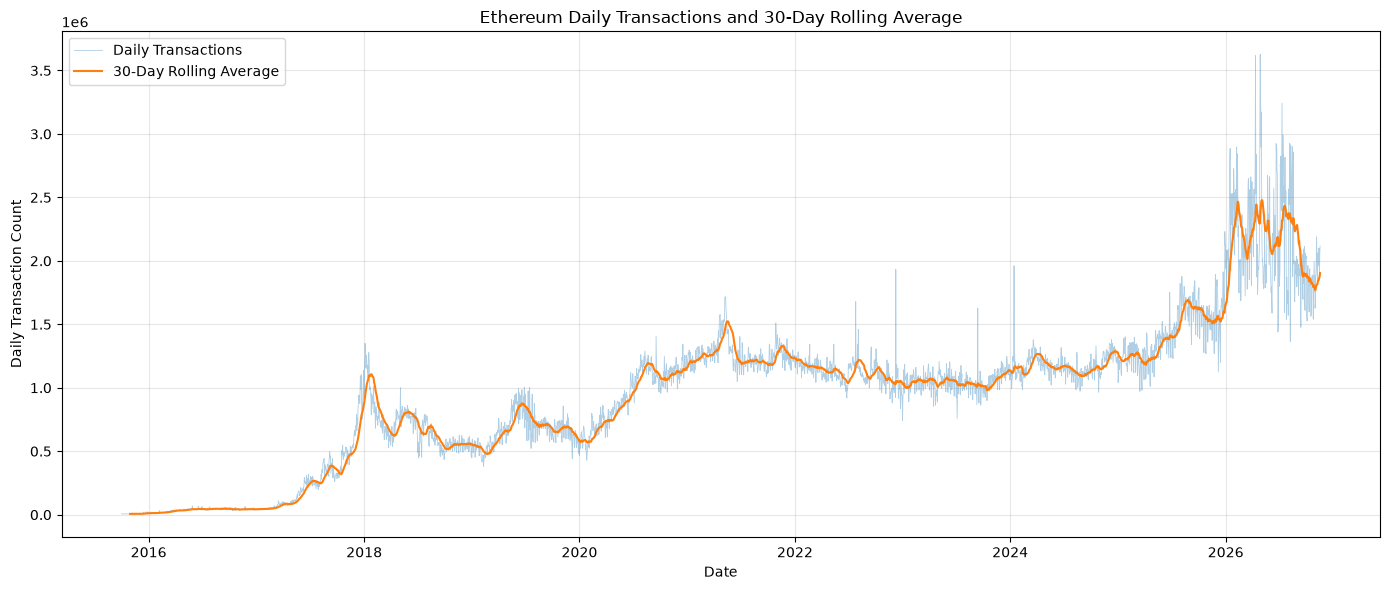

Chart 03 saved successfully!


In [10]:
# Calculate 30-day rolling average

df_transactions["transactions_30d_avg"] = (
    df_transactions["daily_transaction_count"]
    .rolling(window=30)
    .mean()
)

# Plot daily transactions and 30-day rolling average

plt.figure(figsize=(14, 6))

plt.plot(
    df_transactions["block_date"],
    df_transactions["daily_transaction_count"],
    alpha=0.35,
    linewidth=0.6,
    label="Daily Transactions"
)

plt.plot(
    df_transactions["block_date"],
    df_transactions["transactions_30d_avg"],
    linewidth=1.5,
    label="30-Day Rolling Average"
)

plt.title("Ethereum Daily Transactions and 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "03_transactions_30d_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 03 saved successfully!")

### 5.4 Variability in Daily Transaction Activity

This subsection investigates changes in the variability of daily Ethereum transaction activity over time. A 30-day rolling standard deviation is calculated to measure short-term fluctuations and identify periods of relatively stable or volatile network activity.

# Calculate 30-day rolling standard deviation

df_transactions["transactions_30d_std"] = (
    df_transactions["daily_transaction_count"]
    .rolling(window=30)
    .std()
)

# Plot 30-day rolling standard deviation

plt.figure(figsize=(14, 6))

plt.plot(
    df_transactions["block_date"],
    df_transactions["transactions_30d_std"],
    linewidth=1.0
)

plt.title("30-Day Rolling Standard Deviation of Daily Ethereum Transactions")
plt.xlabel("Date")
plt.ylabel("Rolling Standard Deviation")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)

visualizations_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    visualizations_dir / "04_transaction_activity_rolling_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 04 saved successfully!")

#### 5.4.1 Summary of Rolling Variability

This subsection provides descriptive statistics for the 30-day rolling standard deviation of daily Ethereum transaction counts. It also identifies the dates associated with the highest and lowest rolling variability.

In [13]:
# Summary of 30-day rolling standard deviation

rolling_std = df_transactions["transactions_30d_std"]

print("Rolling standard deviation summary:")
display(rolling_std.describe())

# Identify the date with the highest rolling variability

max_volatility_index = rolling_std.idxmax()

print("\nHighest rolling variability:")
print("Date:", df_transactions.loc[max_volatility_index, "block_date"])
print("Value:", rolling_std.loc[max_volatility_index])

# Identify the date with the lowest rolling variability

min_volatility_index = rolling_std.idxmin()

print("\nLowest rolling variability:")
print("Date:", df_transactions.loc[min_volatility_index, "block_date"])
print("Value:", rolling_std.loc[min_volatility_index])

Rolling standard deviation summary:


count      4037.000000
mean      83405.201689
std       88462.180995
min         516.017571
25%       44478.106813
50%       60611.682463
75%       89897.053539
max      587070.356509
Name: transactions_30d_std, dtype: float64


Highest rolling variability:
Date: 2026-05-10 00:00:00
Value: 587070.3565089543

Lowest rolling variability:
Date: 2015-10-30 00:00:00
Value: 516.017570760273


**Interpretation:**

The 30-day rolling standard deviation reveals substantial changes in the variability of daily Ethereum transaction activity.

The mean rolling standard deviation is approximately 83,405 transactions, while the maximum reaches approximately 587,070 transactions on 10 May 2026. In contrast, the minimum value of approximately 516 transactions occurs on 30 October 2015.

These findings indicate considerable changes in short-term transaction variability over the study period. The results suggest that the time series exhibits changing volatility, which may have implications for forecasting model selection and evaluation.

### 5.5 Distributional Characteristics

This section examines the distributional properties of daily Ethereum transaction counts. The analysis focuses on the spread of observations, potential outliers, and deviations from a symmetric distribution.

The Interquartile Range (IQR) method is used to identify observations that fall outside the conventional lower and upper statistical boundaries.

#### 5.5.1 Boxplot and Outlier Detection

A boxplot is used to visualise the distribution of daily transaction counts and identify potential outliers. The IQR method is applied to calculate the lower and upper boundaries for outlier detection.

First Quartile (Q1): 579612.75
Third Quartile (Q3): 1219666.0
Interquartile Range (IQR): 640053.25
Lower Bound: -380467.125
Upper Bound: 2179745.875
Number of potential outliers: 126


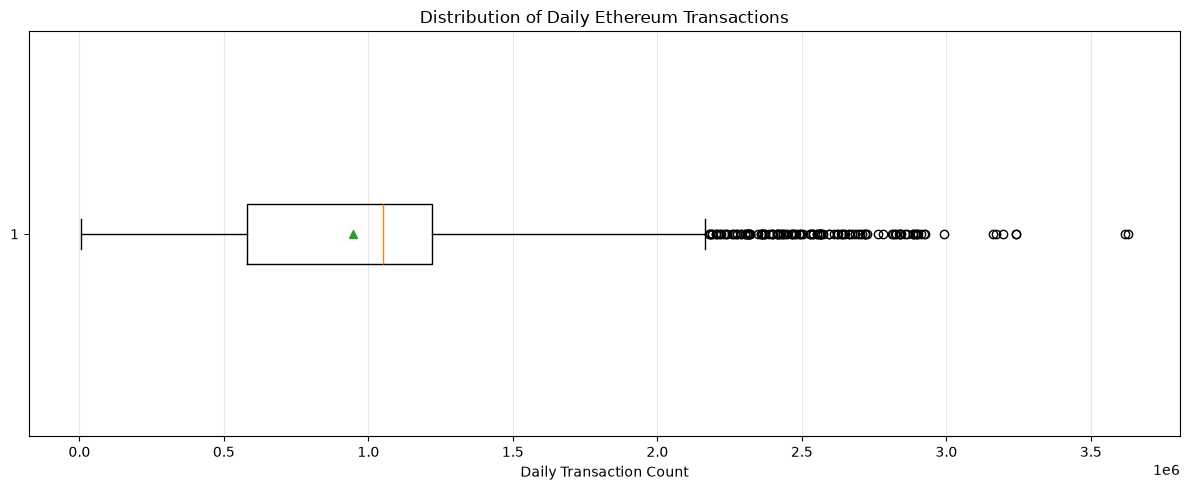

Chart 05 saved successfully!


In [15]:
# Boxplot and IQR-based outlier detection

# Calculate quartiles and interquartile range
Q1 = df_transactions["daily_transaction_count"].quantile(0.25)
Q3 = df_transactions["daily_transaction_count"].quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df_transactions[
    (df_transactions["daily_transaction_count"] < lower_bound) |
    (df_transactions["daily_transaction_count"] > upper_bound)
]

# Display results
print("First Quartile (Q1):", Q1)
print("Third Quartile (Q3):", Q3)
print("Interquartile Range (IQR):", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

# Create boxplot
plt.figure(figsize=(12, 5))

plt.boxplot(
    df_transactions["daily_transaction_count"],
    orientation="horizontal",
    showmeans=True
)

plt.title("Distribution of Daily Ethereum Transactions")
plt.xlabel("Daily Transaction Count")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "05_transaction_count_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 05 saved successfully!")

#### 5.5.2 Interpretation of Distribution and Outliers

The IQR-based outlier detection identified 126 potential outliers, representing approximately 3.1% of the 4,066 daily observations.

The interquartile range is 640,053.25 transactions, with the middle 50% of observations ranging from approximately 579,613 to 1,219,666 transactions.

The lower outlier boundary is negative (-380,467.13), indicating that no lower outliers are possible given the non-negative nature of transaction counts. The upper boundary is approximately 2,179,746 transactions.

These findings indicate the presence of unusually high daily transaction counts. Such observations may reflect periods of elevated network activity and should not automatically be treated as erroneous data or removed from subsequent forecasting analyses.

### 5.6 Seasonal Patterns in Daily Transaction Activity

This section examines whether Ethereum daily transaction activity exhibits recurring temporal patterns. The analysis begins by investigating differences in average transaction counts across the days of the week.

Identifying potential weekly patterns may help determine whether day-of-week effects should be considered during subsequent time-series modelling and forecasting.

#### 5.6.1 Average Daily Transactions by Day of the Week

This subsection examines whether average Ethereum transaction activity differs across the seven days of the week.

Daily transaction counts are grouped by weekday, and the mean transaction count is calculated for each day. A bar chart is used to compare average activity throughout the week.

block_date
Monday       960656.619621
Tuesday      977870.314974
Wednesday    970553.629310
Thursday     966687.752151
Friday       966073.650602
Saturday     910441.920826
Sunday       886207.416523
Name: daily_transaction_count, dtype: float64

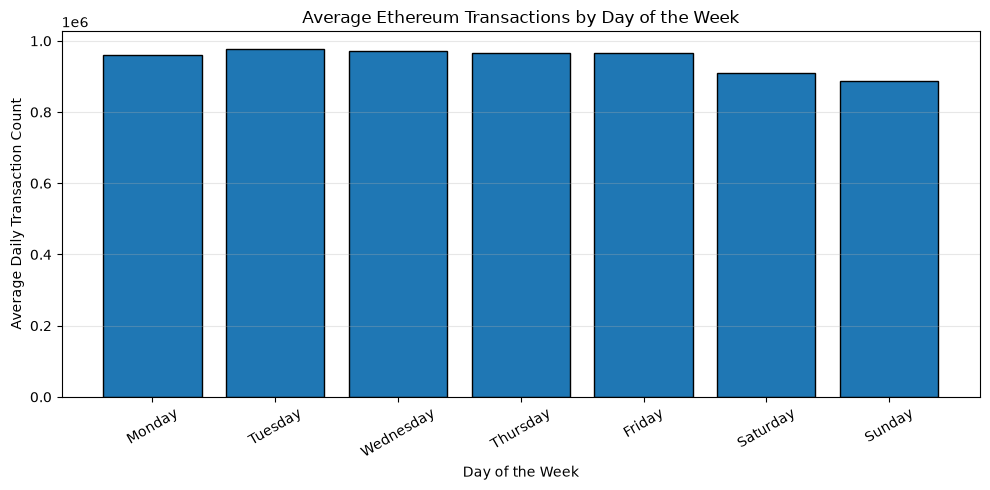

Chart 06 saved successfully!


In [16]:
# Calculate average daily transactions by weekday

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_avg = (
    df_transactions
    .groupby(df_transactions["block_date"].dt.day_name())
    ["daily_transaction_count"]
    .mean()
    .reindex(weekday_order)
)

# Display average transaction counts

display(weekday_avg)

# Plot average daily transactions by weekday

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_avg.index,
    weekday_avg.values,
    edgecolor="black"
)

plt.title("Average Ethereum Transactions by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Daily Transaction Count")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "06_average_transactions_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 06 saved successfully!")

#### 5.6.2 Interpretation of Weekly Patterns

The analysis reveals differences in average Ethereum transaction activity across the seven days of the week.

Tuesday records the highest average daily transaction count, at approximately 977,870 transactions, while Sunday has the lowest average, at approximately 886,207 transactions.

Average transaction activity remains relatively consistent from Monday to Friday. However, lower average transaction counts are observed on Saturday and Sunday.

The average Sunday transaction count is approximately 9.4% lower than the Tuesday average. This suggests a potential weekly pattern in Ethereum network activity, with reduced activity during weekends.

These findings provide an initial indication of day-of-week effects. However, further statistical analysis is required to determine whether these differences represent a consistent and statistically significant seasonal pattern.

#### 5.6.3 Average Daily Transactions by Month

This subsection examines monthly seasonal patterns in Ethereum transaction activity. Daily transaction counts are grouped by calendar month, and the average transaction count is calculated for each month across the study period.

A bar chart is used to compare average activity across the twelve months of the year.

January      9.374961e+05
February     9.152717e+05
March        9.306098e+05
April        9.666106e+05
May          9.986584e+05
June         9.847487e+05
July         1.016326e+06
August       1.027469e+06
September    9.724679e+05
October      8.844817e+05
November     8.834697e+05
December     8.691748e+05
Name: daily_transaction_count, dtype: float64

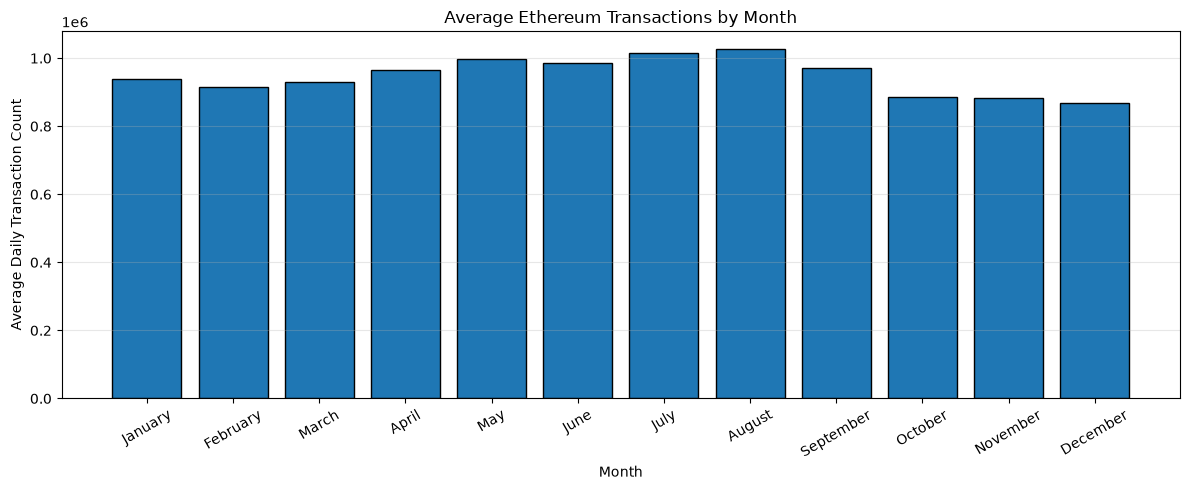

Chart 07 saved successfully!


In [17]:
# Calculate average daily transactions by month

month_order = list(range(1, 13))

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_avg = (
    df_transactions
    .groupby(df_transactions["block_date"].dt.month)
    ["daily_transaction_count"]
    .mean()
    .reindex(month_order)
)

monthly_avg.index = month_names

# Display average transaction counts

display(monthly_avg)

# Plot average daily transactions by month

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_avg.index,
    monthly_avg.values,
    edgecolor="black"
)

plt.title("Average Ethereum Transactions by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Transaction Count")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "07_average_transactions_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 07 saved successfully!")

#### 5.6.4 Interpretation of Monthly Patterns

The monthly analysis reveals differences in average Ethereum transaction activity across the twelve calendar months.

August records the highest average daily transaction count, at approximately 1,027,469 transactions, followed by July at approximately 1,016,326 transactions. December records the lowest average, at approximately 869,175 transactions.

Average transaction activity generally increases from the beginning of the year towards the summer months, reaching its highest levels in July and August. A declining pattern is subsequently observed from August through December.

The average daily transaction count in August is approximately 18.2% higher than in December.

These findings suggest potential annual seasonal patterns in Ethereum network activity. However, the observed differences may also be influenced by long-term trends and changes in network usage over the study period. Further statistical analysis is therefore required before concluding that these differences represent genuine annual seasonality.

#### 5.6.5 Monthly Transaction Activity Across Years

This subsection investigates how monthly Ethereum transaction activity changes across individual years.

Average daily transaction counts are calculated for each month within each year. A year-by-month heatmap is used to identify recurring seasonal patterns and distinguish them from long-term changes in network activity.

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
block_date,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6614.0,7824.0,11197.0
2016,13059.0,17932.0,29586.0,34103.0,43445.0,45051.0,43771.0,45347.0,46247.0,42898.0,43386.0,42456.0
2017,45473.0,50359.0,78273.0,84666.0,136952.0,241489.0,252770.0,339457.0,355975.0,406518.0,509742.0,862325.0
2018,1080783.0,793999.0,653608.0,695888.0,809862.0,749060.0,643130.0,640066.0,535225.0,550223.0,557130.0,551858.0
2019,534503.0,479068.0,581599.0,661005.0,784919.0,855988.0,738453.0,709803.0,682194.0,675956.0,679619.0,589413.0
2020,571082.0,662510.0,733829.0,773713.0,859632.0,960095.0,1093450.0,1183221.0,1094963.0,1074098.0,1126197.0,1159049.0
2021,1209379.0,1270661.0,1265691.0,1391874.0,1453388.0,1206607.0,1208704.0,1201627.0,1187000.0,1256111.0,1297401.0,1235498.0
2022,1188746.0,1169266.0,1160980.0,1119986.0,1127610.0,1036117.0,1199169.0,1125859.0,1124647.0,1100727.0,1042370.0,1035949.0
2023,1027786.0,1064050.0,1068017.0,1005566.0,1081243.0,1054275.0,1015291.0,1030789.0,1016358.0,1011103.0,1085597.0,1135233.0


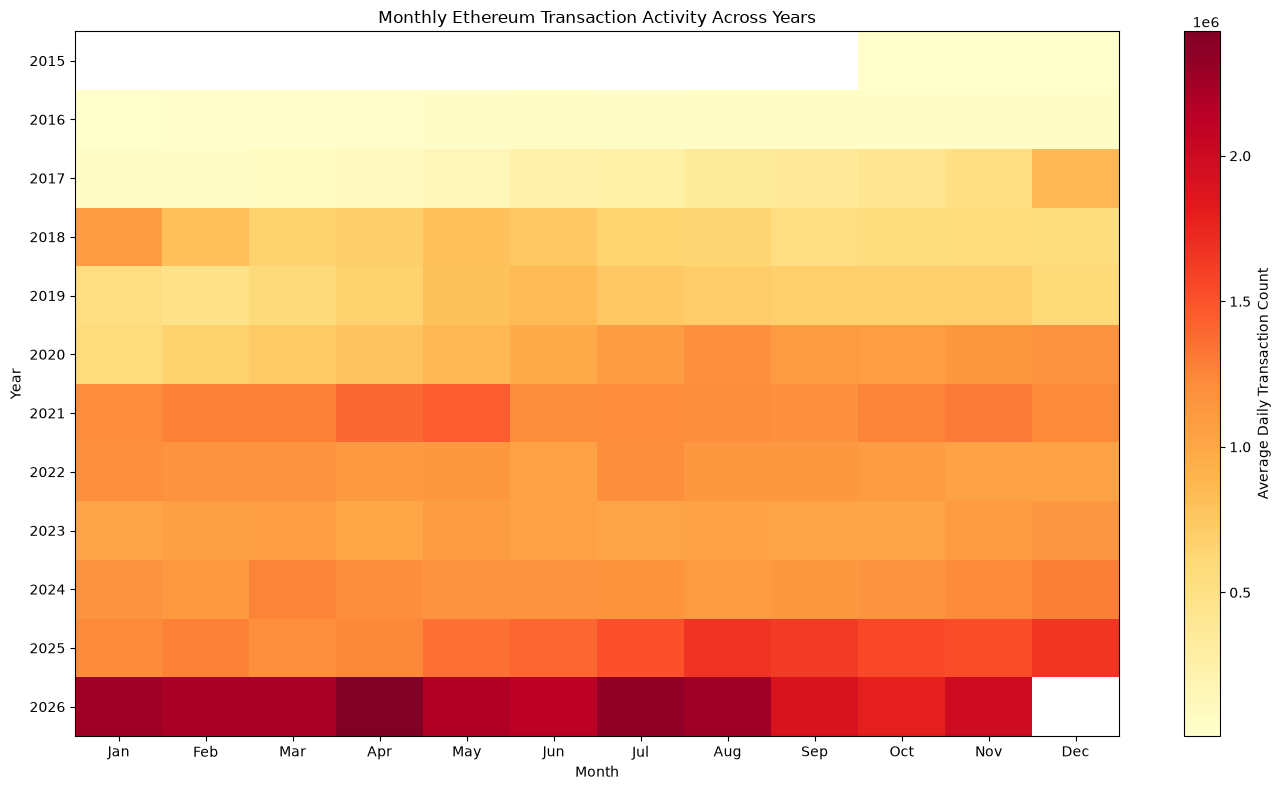

Chart 08 saved successfully!


In [18]:
# Calculate average daily transactions for each month and year

monthly_yearly_avg = (
    df_transactions
    .groupby([
        df_transactions["block_date"].dt.year,
        df_transactions["block_date"].dt.month
    ])["daily_transaction_count"]
    .mean()
    .unstack()
)

# Display the year-by-month table

monthly_yearly_avg.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(monthly_yearly_avg.round(0))

# Create year-by-month heatmap

plt.figure(figsize=(14, 8))

plt.imshow(
    monthly_yearly_avg,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

plt.colorbar(label="Average Daily Transaction Count")

plt.title("Monthly Ethereum Transaction Activity Across Years")
plt.xlabel("Month")
plt.ylabel("Year")

plt.xticks(
    ticks=range(12),
    labels=monthly_yearly_avg.columns
)

plt.yticks(
    ticks=range(len(monthly_yearly_avg.index)),
    labels=monthly_yearly_avg.index
)

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "08_monthly_transaction_activity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 08 saved successfully!")

#### 5.6.6 Interpretation of Monthly Activity Across Years

The year-by-month analysis reveals substantial changes in Ethereum transaction activity throughout the study period.

During 2015–2017, average daily transaction counts increased considerably as network activity expanded. This was followed by changing activity levels during 2018–2019.

A further increase occurred during 2020, with monthly averages exceeding one million transactions per day in several months. From 2021 to 2024, activity generally remained at relatively high levels, although monthly fluctuations continued.

A substantial increase is observed again during 2025 and 2026. Several monthly averages in 2026 exceed two million transactions per day.

The analysis also indicates that monthly patterns are not consistent across all years. The apparent summer peak identified in the overall monthly averages is not uniformly observed in individual years.

These findings suggest that long-term trends and structural changes in Ethereum network activity may influence the apparent seasonal patterns. Therefore, seasonal effects should be investigated separately from long-term trends before they are incorporated into forecasting models.

Note that 2015 and 2026 represent incomplete calendar years in this dataset, and their monthly averages should be interpreted accordingly.

## 5.7 Autocorrelation Analysis

This section investigates temporal dependencies in Ethereum daily transaction activity using autocorrelation analysis.

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) are examined to identify relationships between current transaction counts and their previous observations.

Both the original time series and its first-differenced version are analysed. Differencing helps reduce long-term trends and provides a clearer assessment of short-term temporal dependencies.

These analyses provide preliminary information for selecting and specifying statistical forecasting models, particularly ARIMA.

In [19]:
# Check statsmodels installation

import statsmodels

print("Statsmodels version:", statsmodels.__version__)
print("Statistical analysis library is ready!")

Statsmodels version: 0.15.0
Statistical analysis library is ready!


#### 5.7.2 ACF and PACF of the Original Time Series

The ACF and PACF plots are used to examine temporal dependencies in the original daily Ethereum transaction-count series.

The analysis considers 60 daily lags to investigate short-term and medium-term autocorrelation patterns. The results are also used to assess the influence of long-term trends on autocorrelation.

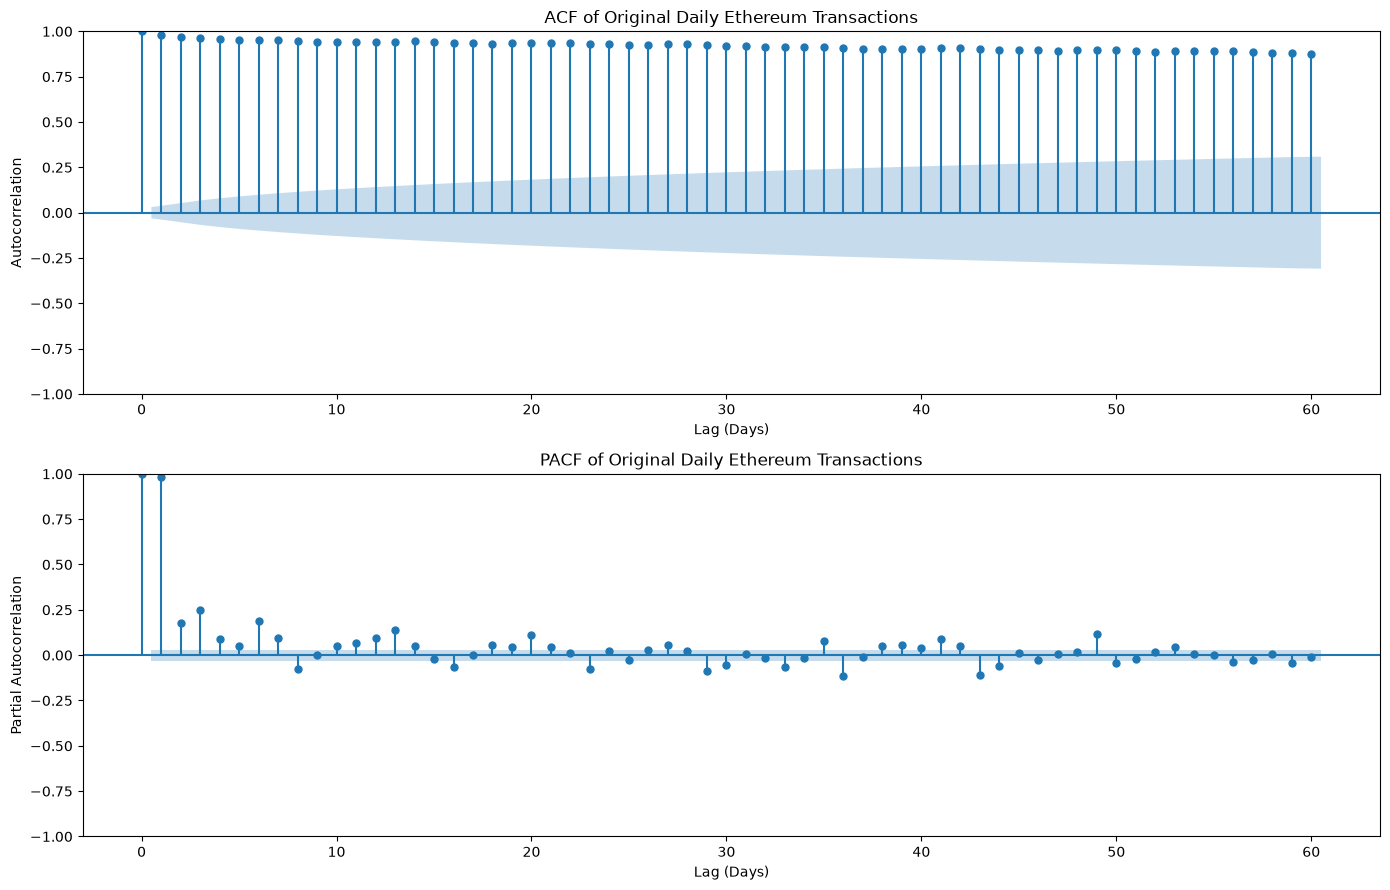

Chart 09 saved successfully!


In [20]:
# ACF and PACF of the original time series

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Extract the original transaction-count series
transaction_series = df_transactions["daily_transaction_count"]

# Create ACF and PACF plots
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    transaction_series,
    lags=60,
    ax=axes[0]
)

axes[0].set_title("ACF of Original Daily Ethereum Transactions")
axes[0].set_xlabel("Lag (Days)")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(
    transaction_series,
    lags=60,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF of Original Daily Ethereum Transactions")
axes[1].set_xlabel("Lag (Days)")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "09_acf_pacf_original_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 09 saved successfully!")

#### 5.7.2.1 Interpretation of ACF and PACF

The ACF plot of the original daily transaction-count series exhibits strong positive autocorrelation, with values remaining close to one across the examined lags.

The PACF plot shows a strong first-lag autocorrelation, followed by a substantial decline at the second lag and gradually decreasing oscillations at subsequent lags.

These patterns indicate strong temporal persistence and suggest that the original series may be non-stationary, potentially due to its long-term trend.

Therefore, differencing and formal stationarity testing are required before identifying appropriate statistical forecasting models.

#### 5.7.3 First-Order Differencing

First-order differencing is applied to the original daily transaction-count series to examine changes between consecutive days.

This transformation removes the level of the series and may help reduce non-stationarity associated with long-term trends.

The differenced series is subsequently examined using ACF and PACF plots to investigate its remaining temporal dependencies.

count    4.065000e+03
mean     5.190435e+02
std      1.130705e+05
min     -1.269696e+06
25%     -3.215800e+04
50%     -4.100000e+01
75%      3.029400e+04
max      1.548731e+06
Name: transactions_diff1, dtype: float64

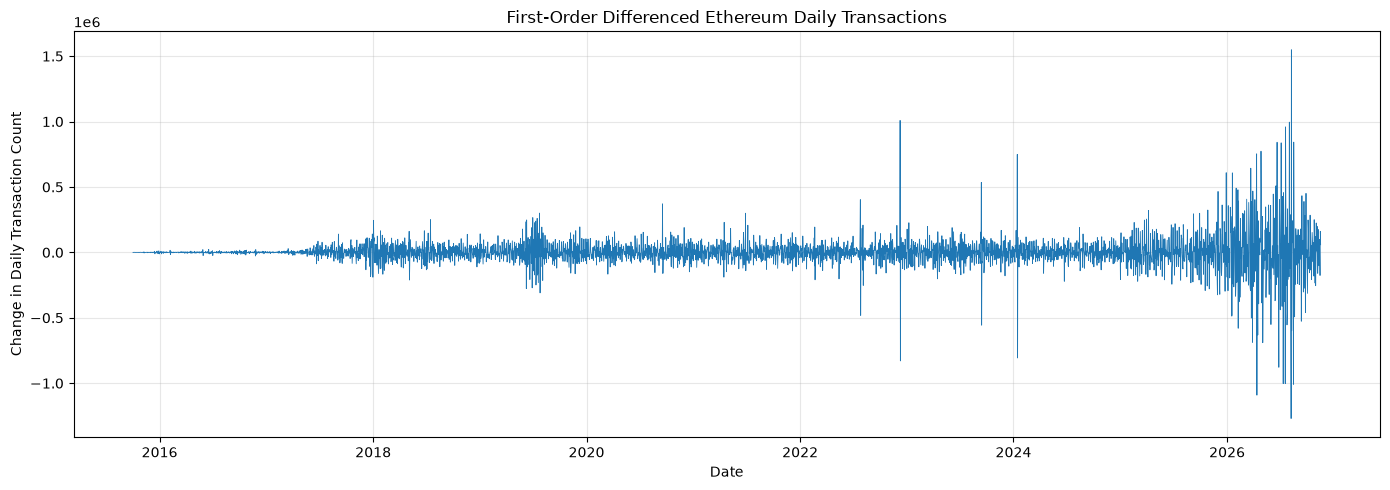

Chart 10 saved successfully!


In [21]:
# Apply first-order differencing

df_transactions["transactions_diff1"] = (
    df_transactions["daily_transaction_count"].diff()
)

# Display descriptive statistics of the differenced series

display(df_transactions["transactions_diff1"].describe())

# Plot the first-differenced series

plt.figure(figsize=(14, 5))

plt.plot(
    df_transactions["block_date"],
    df_transactions["transactions_diff1"],
    linewidth=0.6
)

plt.title("First-Order Differenced Ethereum Daily Transactions")
plt.xlabel("Date")
plt.ylabel("Change in Daily Transaction Count")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "10_first_order_differenced_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 10 saved successfully!")

#### 5.7.3.1 Interpretation of First-Order Differencing

First-order differencing transforms the original transaction-count series into daily changes in network activity.

The differenced series contains 4,065 observations, with a mean of approximately 519 transactions and a median of -41 transactions. Both values are close to zero compared with the mean level of the original series.

However, the standard deviation remains relatively high, at approximately 113,071 transactions. The observed daily changes range from approximately -1,269,696 to 1,548,731 transactions.

These results indicate that first-order differencing removes the original series level and produces changes centred relatively close to zero. Nevertheless, substantial fluctuations remain.

Further autocorrelation analysis and formal stationarity testing are required to determine whether first-order differencing is sufficient to achieve stationarity.

#### 5.7.4 ACF and PACF of the First-Differenced Series

The ACF and PACF are applied to the first-differenced daily transaction-count series to examine the remaining temporal dependencies after removing the original series level.

This analysis helps determine whether differencing has reduced the strong autocorrelation observed in the original series and provides preliminary information for identifying potential ARIMA model parameters.

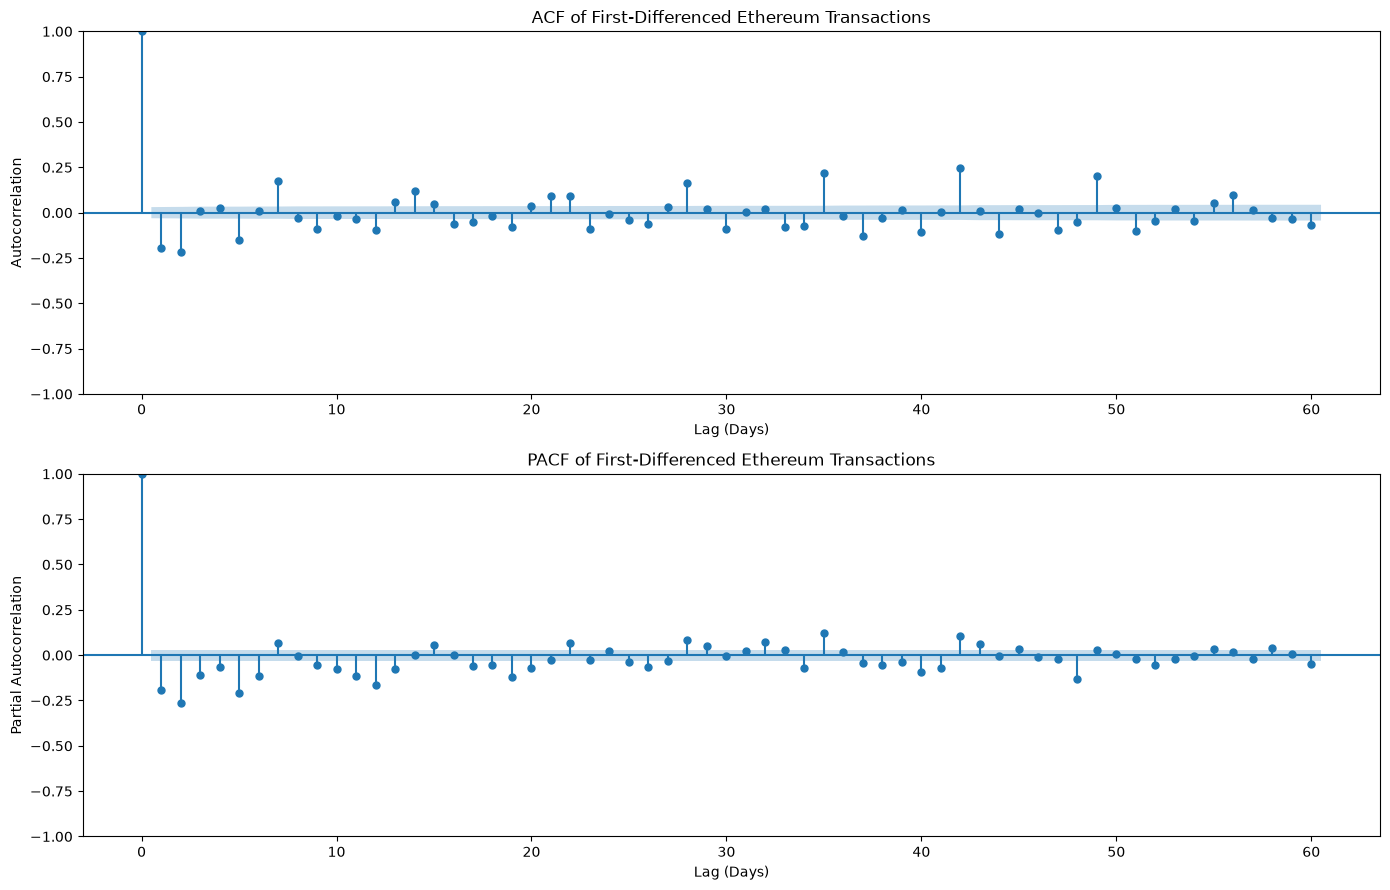

Chart 11 saved successfully!


In [22]:
# ACF and PACF of the first-differenced series

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Remove the initial missing value created by differencing
differenced_series = (
    df_transactions["transactions_diff1"].dropna()
)

# Create ACF and PACF plots
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    differenced_series,
    lags=60,
    ax=axes[0]
)

axes[0].set_title("ACF of First-Differenced Ethereum Transactions")
axes[0].set_xlabel("Lag (Days)")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(
    differenced_series,
    lags=60,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF of First-Differenced Ethereum Transactions")
axes[1].set_xlabel("Lag (Days)")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "11_acf_pacf_differenced_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 11 saved successfully!")

#### 5.7.4.1 Interpretation of ACF and PACF After First-Order Differencing

The ACF plot of the first-differenced series exhibits multiple significant positive and negative autocorrelation values across the examined lags.

Positive autocorrelations are observed at several lags, including 7, 13, 14, and 15, while negative autocorrelations occur at lags 1, 2, 5, 9, and 12.

The PACF plot also exhibits significant values across numerous lags, with fluctuating magnitudes that gradually decrease.

These findings indicate that first-order differencing has not eliminated all temporal dependencies in the series. The remaining autocorrelation structure suggests that daily changes in Ethereum transaction activity may involve complex short-term and potentially seasonal relationships.

Further investigation using formal stationarity tests is necessary before determining the appropriate differencing order and selecting ARIMA model parameters.

### 5.7.5 Formal Stationarity Testing

The stationarity of the Ethereum daily transaction-count series is examined using the Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.

The ADF test evaluates the presence of a unit root, while the KPSS test evaluates the null hypothesis of stationarity.

Both tests are applied to the original and first-differenced series to assess whether differencing has achieved stationarity.

A significance level of 5% is used for statistical interpretation.

In [23]:
# Import stationarity tests

from statsmodels.tsa.stattools import adfuller, kpss

# Define a function for stationarity testing

def stationarity_tests(series, series_name):

    print("\n" + "=" * 60)
    print("Stationarity Tests:", series_name)
    print("=" * 60)

    # Augmented Dickey-Fuller test
    adf_result = adfuller(series, autolag="AIC")

    print("\nAugmented Dickey-Fuller (ADF) Test")
    print("Test Statistic:", adf_result[0])
    print("p-value:", adf_result[1])
    print("Number of Lags:", adf_result[2])

    # KPSS test
    kpss_result = kpss(
        series,
        regression="c",
        nlags="auto"
    )

    print("\nKPSS Test")
    print("Test Statistic:", kpss_result[0])
    print("p-value:", kpss_result[1])
    print("Number of Lags:", kpss_result[2])


# Test original series

stationarity_tests(
    df_transactions["daily_transaction_count"],
    "Original Series"
)

# Test first-differenced series

stationarity_tests(
    df_transactions["transactions_diff1"].dropna(),
    "First-Differenced Series"
)


Stationarity Tests: Original Series


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea


Augmented Dickey-Fuller (ADF) Test
Test Statistic: -1.1536244392811115
p-value: 0.6932206503777929
Number of Lags: 29

KPSS Test
Test Statistic: 8.022143114107388
p-value: 0.01
Number of Lags: 39

Stationarity Tests: First-Differenced Series

Augmented Dickey-Fuller (ADF) Test
Test Statistic: -12.621267379154181
p-value: 1.576337143597333e-23
Number of Lags: 31

KPSS Test
Test Statistic: 0.05601127421153407
p-value: 0.1
Number of Lags: 254


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea

#### 5.7.5.1 Interpretation of Stationarity Tests

The stationarity of the original and first-differenced Ethereum daily transaction-count series was evaluated using the Augmented Dickey-Fuller (ADF) and KPSS tests, with a significance level of 5%.

For the original series, the ADF test produces a p-value of 0.6932, indicating that the unit-root null hypothesis cannot be rejected. The KPSS test produces a test statistic of 8.0221 and a p-value of 0.01, providing strong evidence against stationarity.

Both tests therefore indicate that the original series is non-stationary.

For the first-differenced series, the ADF test produces a test statistic of -12.6213 and a p-value of approximately 1.58 × 10⁻²³. The unit-root null hypothesis is strongly rejected.

The KPSS test produces a statistic of 0.0560 and a p-value of 0.10. The stationarity null hypothesis cannot be rejected.

The two tests therefore provide consistent evidence that first-order differencing has achieved stationarity.

These findings support the use of a first-order differencing parameter (d = 1) in subsequent ARIMA modelling. However, remaining autocorrelation and potential weekly seasonal effects should also be investigated before specifying the final forecasting models.

## 5.8 Weekly Seasonal Analysis

This section investigates recurring weekly patterns in Ethereum daily transaction activity.

The analysis focuses on a seasonal period of seven days, corresponding to the weekly calendar cycle. Seasonal patterns are examined using seasonal differencing and autocorrelation analysis.

The objective is to determine whether weekly dependencies remain after removing the long-term trend and whether seasonal components should be considered in subsequent forecasting models.

#### 5.8.1 Seasonal Differencing (Lag 7)

Seasonal differencing with a lag of seven days is applied to the daily transaction-count series to examine weekly recurring patterns.

The transformation calculates the difference between each observation and the corresponding observation seven days earlier.

This analysis helps investigate whether weekly seasonal structure remains in the original series.

count    4.059000e+03
mean     3.489603e+03
std      1.648102e+05
min     -1.881146e+06
25%     -3.739650e+04
50%      1.102000e+03
75%      4.451000e+04
max      1.694867e+06
Name: transactions_seasonal_diff7, dtype: float64

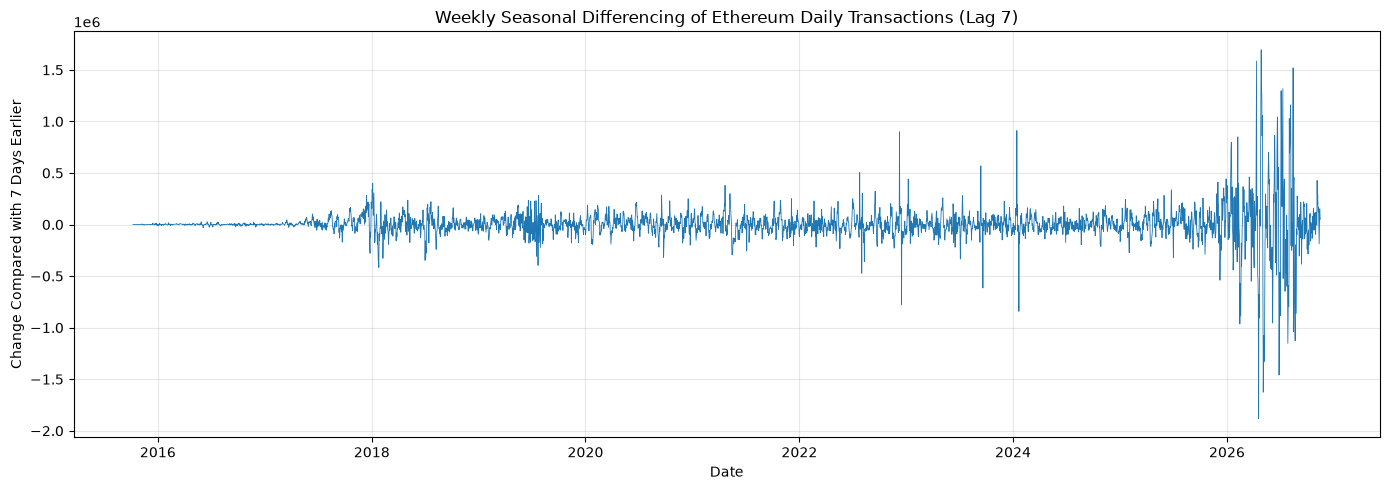

Chart 12 saved successfully!


In [24]:
# Apply weekly seasonal differencing

df_transactions["transactions_seasonal_diff7"] = (
    df_transactions["daily_transaction_count"]
    .diff(periods=7)
)

# Display descriptive statistics

display(
    df_transactions["transactions_seasonal_diff7"].describe()
)

# Plot weekly seasonally differenced series

plt.figure(figsize=(14, 5))

plt.plot(
    df_transactions["block_date"],
    df_transactions["transactions_seasonal_diff7"],
    linewidth=0.6
)

plt.title(
    "Weekly Seasonal Differencing of Ethereum Daily Transactions (Lag 7)"
)

plt.xlabel("Date")
plt.ylabel("Change Compared with 7 Days Earlier")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "12_weekly_seasonal_differencing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 12 saved successfully!")

#### 5.8.1.1 Interpretation of Weekly Seasonal Differencing

Weekly seasonal differencing (lag 7) produces 4,059 observations by calculating the difference between each daily transaction count and the corresponding observation seven days earlier.

The resulting series has a mean of approximately 3,490 transactions and a median of 1,102 transactions, both relatively small compared with the original transaction-count level.

However, the standard deviation remains substantial, at approximately 164,810 transactions. The observed differences range from approximately -1,881,146 to 1,694,867 transactions.

These results indicate considerable changes in transaction activity between corresponding weekdays across consecutive weeks.

Further autocorrelation analysis is required to determine whether meaningful weekly seasonal dependencies remain and whether seasonal differencing is appropriate for subsequent forecasting models.

#### 5.8.2 Autocorrelation at Weekly Seasonal Lags

The autocorrelation structure of the weekly seasonally differenced series is examined to investigate remaining temporal dependencies.

Particular attention is given to lags 7, 14, 21, 28, and subsequent multiples of seven days.

This analysis helps assess whether weekly seasonal autocorrelation remains after applying seasonal differencing.

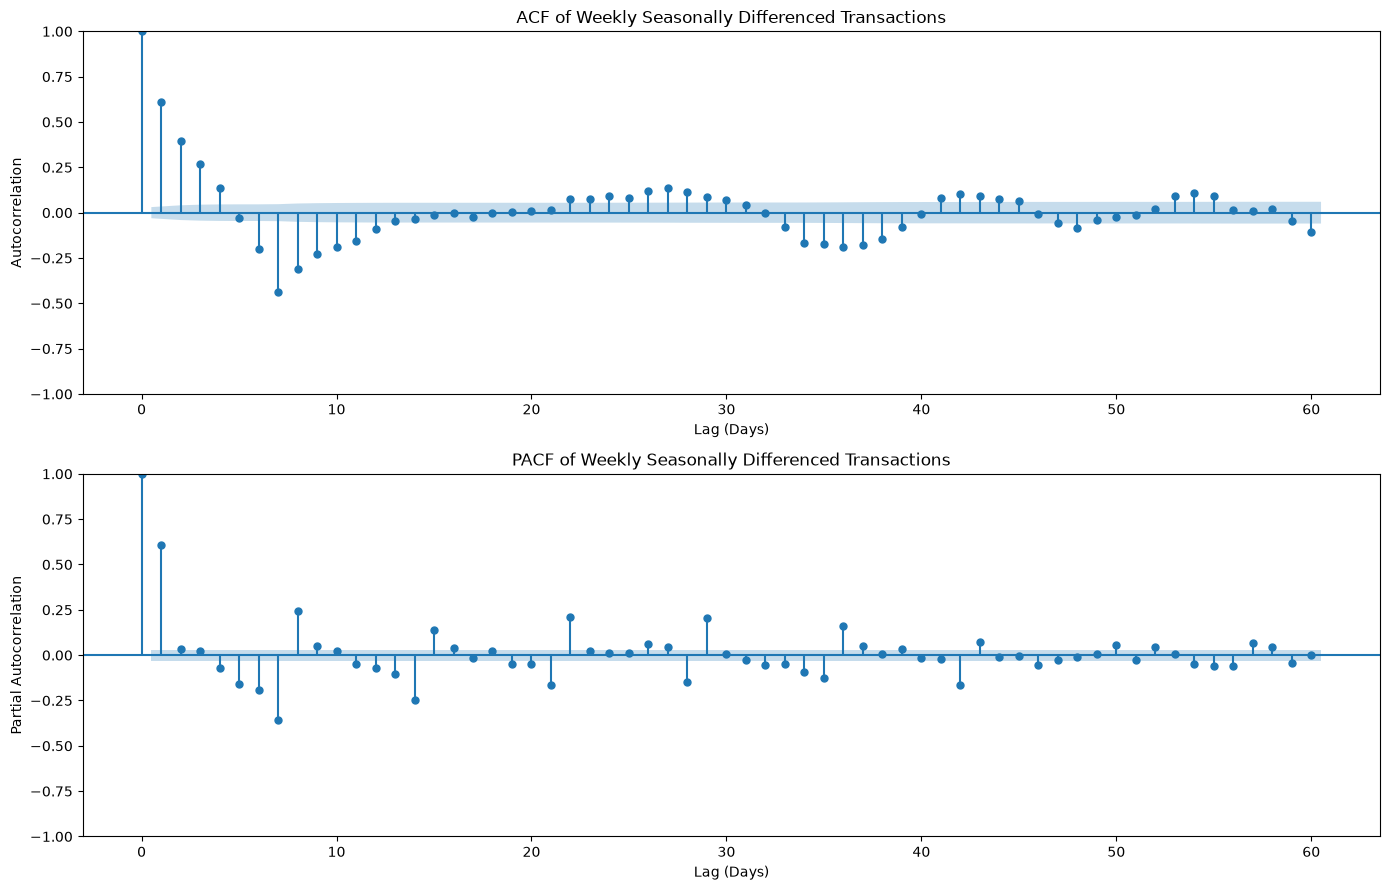

Chart 13 saved successfully!


In [25]:
# ACF and PACF of weekly seasonally differenced series

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

seasonal_diff_series = (
    df_transactions["transactions_seasonal_diff7"].dropna()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    seasonal_diff_series,
    lags=60,
    ax=axes[0]
)

axes[0].set_title("ACF of Weekly Seasonally Differenced Transactions")
axes[0].set_xlabel("Lag (Days)")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(
    seasonal_diff_series,
    lags=60,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF of Weekly Seasonally Differenced Transactions")
axes[1].set_xlabel("Lag (Days)")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "13_acf_pacf_weekly_seasonal_diff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 13 saved successfully!")

#### 5.8.2.1 Interpretation of Seasonal ACF and PACF

The ACF of the weekly seasonally differenced series exhibits multiple significant positive and negative autocorrelations across the examined lags.

Positive correlations are observed at lags 1–4, 22–30, 40–44, and 52–54, while negative correlations occur at lags 6–12, 33–38, 47, and 58.

The PACF also exhibits multiple significant positive and negative correlations. Both functions display fluctuating patterns with gradually decreasing magnitudes.

These results indicate that substantial temporal dependencies remain after applying seven-day seasonal differencing. However, the observed oscillations do not provide conclusive evidence of a simple weekly seasonal structure.

Further investigation is required to distinguish genuine weekly seasonality from other cyclical behaviour and remaining temporal dependencies.

#### 5.8.3 Stationarity Tests After Weekly Seasonal Differencing

The Augmented Dickey-Fuller (ADF) and KPSS tests are applied to the weekly seasonally differenced series to evaluate its stationarity.

The results are compared with those obtained for the original and first-differenced series to assess the effects of weekly seasonal differencing.

A significance level of 5% is used for statistical interpretation.

In [26]:
# Stationarity tests for weekly seasonally differenced series

stationarity_tests(
    df_transactions["transactions_seasonal_diff7"].dropna(),
    "Weekly Seasonally Differenced Series (Lag 7)"
)


Stationarity Tests: Weekly Seasonally Differenced Series (Lag 7)

Augmented Dickey-Fuller (ADF) Test
Test Statistic: -11.163528998760324
p-value: 2.7501070429139595e-20
Number of Lags: 31

KPSS Test
Test Statistic: 0.018149009176103084
p-value: 0.1
Number of Lags: 15


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea

#### 5.8.3.1 Interpretation of Stationarity Tests After Weekly Seasonal Differencing

The stationarity of the weekly seasonally differenced series was evaluated using the Augmented Dickey-Fuller (ADF) and KPSS tests, with a significance level of 5%.

The ADF test produces a test statistic of -11.1635 and a p-value of approximately 2.75 × 10⁻²⁰. The unit-root null hypothesis is therefore strongly rejected.

The KPSS test produces a statistic of 0.0181 and a p-value of 0.10. The stationarity null hypothesis cannot be rejected.

Both tests provide evidence that the weekly seasonally differenced series is stationary.

Although weekly seasonal differencing achieves stationarity, this result does not establish that a weekly seasonal component is present or that seasonal differencing is necessary. The results must be considered alongside the autocorrelation structure and forecasting performance of alternative models.

#### 5.8.4 Autocorrelation at Weekly Intervals

This subsection examines autocorrelation at multiples of seven days in the original and first-differenced transaction-count series.

The autocorrelation coefficients and their 95% confidence intervals are calculated to investigate whether weekly dependencies remain after ordinary first-order differencing.

This comparison provides additional evidence for evaluating the potential inclusion of weekly seasonal components in forecasting models.

In [27]:
# Compare autocorrelation at weekly intervals

from statsmodels.tsa.stattools import acf

weekly_lags = list(range(7, 57, 7))

# Original series
original_acf, original_conf = acf(
    df_transactions["daily_transaction_count"],
    nlags=56,
    alpha=0.05
)

# First-differenced series
diff1_acf, diff1_conf = acf(
    df_transactions["transactions_diff1"].dropna(),
    nlags=56,
    alpha=0.05
)

# Create comparison table
weekly_acf_comparison = pd.DataFrame({
    "Lag": weekly_lags,
    "Original_ACF": [original_acf[lag] for lag in weekly_lags],
    "Original_CI_Lower": [
        original_conf[lag, 0] for lag in weekly_lags
    ],
    "Original_CI_Upper": [
        original_conf[lag, 1] for lag in weekly_lags
    ],
    "Differenced_ACF": [diff1_acf[lag] for lag in weekly_lags],
    "Differenced_CI_Lower": [
        diff1_conf[lag, 0] for lag in weekly_lags
    ],
    "Differenced_CI_Upper": [
        diff1_conf[lag, 1] for lag in weekly_lags
    ]
})

display(weekly_acf_comparison.round(4))

C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\1867226226.py:8: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  original_acf, original_conf = acf(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\1867226226.py:15: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff1_acf, diff1_conf = acf(


,Lag,Original_ACF,Original_CI_Lower,Original_CI_Upper,Differenced_ACF,Differenced_CI_Lower,Differenced_CI_Upper
0,7,0.9541,0.8471,1.0612,0.1722,0.1383,0.2061
1,14,0.9440,0.7916,1.0964,0.1208,0.0854,0.1561
2,21,0.9376,0.7510,1.1243,0.0908,0.0547,0.1270
3,28,0.9300,0.7148,1.1452,0.1622,0.1253,0.1992
4,35,0.9133,0.6736,1.1530,0.2193,0.1811,0.2574
5,42,0.9103,0.6490,1.1716,0.2454,0.2053,0.2854
6,49,0.8990,0.6180,1.1801,0.2032,0.1612,0.2453
7,56,0.8906,0.5914,1.1898,0.0980,0.0547,0.1413


#### 5.8.4.1 Interpretation of Autocorrelation at Weekly Intervals

The autocorrelation analysis reveals substantial differences between the original and first-differenced transaction-count series.

For the original series, autocorrelation remains extremely high across weekly intervals, with coefficients ranging from approximately 0.8906 to 0.9541. This reflects the strong temporal persistence and long-term trend identified in the earlier analysis.

After first-order differencing, autocorrelation decreases considerably but remains statistically significant at all eight examined weekly lags, ranging from 0.0908 to 0.2454.

The strongest weekly-lag autocorrelation is observed at lag 42 (0.2454), followed by lag 35 (0.2193) and lag 49 (0.2032).

These findings provide evidence of remaining temporal dependencies at weekly intervals after ordinary first-order differencing.

The results justify further investigation of weekly seasonal components in forecasting models, particularly Seasonal ARIMA (SARIMA). However, significant autocorrelation at weekly lags alone does not establish a deterministic seven-day seasonal pattern.

#### 5.8.5 Combined First-Order and Weekly Seasonal Differencing

This subsection investigates the combined application of first-order differencing and seven-day seasonal differencing.

The transformation is applied to determine whether additional seasonal differencing is necessary after removing the long-term trend.

The resulting series is examined using descriptive statistics and formal stationarity tests. The findings are compared with those obtained from ordinary and weekly seasonal differencing.

count    4.058000e+03
mean     1.274815e+01
std      1.455402e+05
min     -2.557174e+06
25%     -3.614075e+04
50%      1.885000e+02
75%      3.755950e+04
max      1.454949e+06
Name: transactions_diff1_seasonal_diff7, dtype: float64

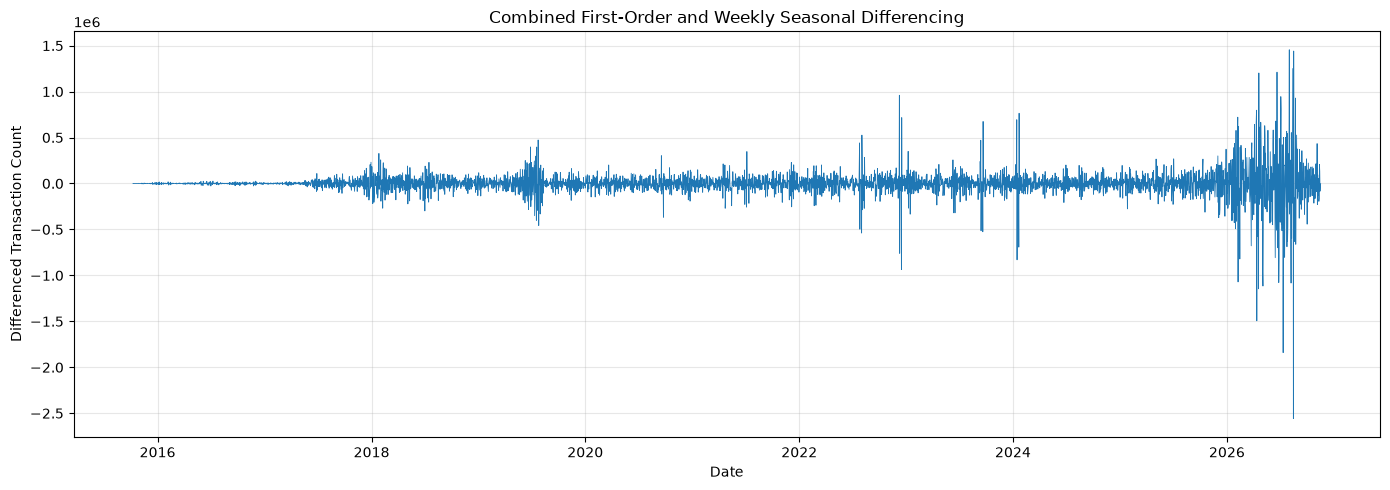

Chart 14 saved successfully!


In [28]:
# Apply first-order and weekly seasonal differencing

df_transactions["transactions_diff1_seasonal_diff7"] = (
    df_transactions["transactions_diff1"].diff(periods=7)
)

# Display descriptive statistics

display(
    df_transactions["transactions_diff1_seasonal_diff7"].describe()
)

# Plot combined differenced series

plt.figure(figsize=(14, 5))

plt.plot(
    df_transactions["block_date"],
    df_transactions["transactions_diff1_seasonal_diff7"],
    linewidth=0.6
)

plt.title(
    "Combined First-Order and Weekly Seasonal Differencing"
)

plt.xlabel("Date")
plt.ylabel("Differenced Transaction Count")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "14_combined_differencing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 14 saved successfully!")

#### 5.8.5.2 Formal Stationarity Testing

The Augmented Dickey-Fuller (ADF) and KPSS tests are applied to the combined first-order and weekly seasonally differenced series.

The results are compared with those obtained from ordinary first-order differencing to assess whether the additional seasonal differencing improves stationarity.

In [29]:
stationarity_tests(
    df_transactions["transactions_diff1_seasonal_diff7"].dropna(),
    "Combined First-Order and Weekly Seasonal Differencing"
)


Stationarity Tests: Combined First-Order and Weekly Seasonal Differencing

Augmented Dickey-Fuller (ADF) Test
Test Statistic: -25.71249615908363
p-value: 0.0
Number of Lags: 28

KPSS Test
Test Statistic: 0.002279318090611676
p-value: 0.1
Number of Lags: 17


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\484936031.py:22: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea

#### 5.8.6 Comparing First-Order and Combined Differencing

This subsection compares the autocorrelation structures of the first-order differenced series and the combined first-order and weekly seasonally differenced series.

Autocorrelation coefficients at lag 1 and multiples of seven days are examined, together with their 95% confidence intervals.

The comparison helps assess whether weekly seasonal differencing removes meaningful remaining temporal dependencies or introduces signs of over-differencing.

The findings will help determine whether ordinary first-order differencing is sufficient for subsequent forecasting models.

In [30]:
from statsmodels.tsa.stattools import acf

# Define the two transformed series
series_diff1 = df_transactions["transactions_diff1"].dropna()

series_combined = (
    df_transactions["transactions_diff1_seasonal_diff7"].dropna()
)

# Lags to examine: lag 1 and weekly intervals
selected_lags = [1, 7, 14, 21, 28, 35, 42, 49, 56]

# Calculate ACF and 95% confidence intervals
acf_diff1, conf_diff1 = acf(
    series_diff1,
    nlags=56,
    alpha=0.05
)

acf_combined, conf_combined = acf(
    series_combined,
    nlags=56,
    alpha=0.05
)

# Create comparison table
acf_comparison = pd.DataFrame({
    "Lag": selected_lags,

    "First_Diff_ACF": [
        acf_diff1[lag] for lag in selected_lags
    ],

    "First_Diff_CI_Lower": [
        conf_diff1[lag, 0] for lag in selected_lags
    ],

    "First_Diff_CI_Upper": [
        conf_diff1[lag, 1] for lag in selected_lags
    ],

    "Combined_Diff_ACF": [
        acf_combined[lag] for lag in selected_lags
    ],

    "Combined_Diff_CI_Lower": [
        conf_combined[lag, 0] for lag in selected_lags
    ],

    "Combined_Diff_CI_Upper": [
        conf_combined[lag, 1] for lag in selected_lags
    ]
})

display(acf_comparison.round(4))

C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\4270939327.py:14: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_diff1, conf_diff1 = acf(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\4270939327.py:20: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_combined, conf_combined = acf(


,Lag,First_Diff_ACF,First_Diff_CI_Lower,First_Diff_CI_Upper,Combined_Diff_ACF,Combined_Diff_CI_Lower,Combined_Diff_CI_Upper
0,1,-0.1948,-0.2256,-0.1641,-0.2226,-0.2533,-0.1918
1,7,0.1722,0.1383,0.2061,-0.4689,-0.5018,-0.4359
2,14,0.1208,0.0854,0.1561,-0.0129,-0.0519,0.0261
3,21,0.0908,0.0547,0.1270,-0.0619,-0.1010,-0.0227
4,28,0.1622,0.1253,0.1992,0.0092,-0.0303,0.0487
5,35,0.2193,0.1811,0.2574,0.0185,-0.0213,0.0584
6,42,0.2454,0.2053,0.2854,0.0412,0.0011,0.0814
7,49,0.2032,0.1612,0.2453,0.0371,-0.0035,0.0777
8,56,0.0980,0.0547,0.1413,-0.0864,-0.1274,-0.0454


#### 5.8.7 Summary of Weekly Seasonal Analysis

The weekly seasonal analysis investigated temporal dependencies in Ethereum daily transaction activity using seasonal differencing, autocorrelation analysis, and formal stationarity tests.

The results indicate that first-order differencing is sufficient to achieve stationarity according to the ADF and KPSS tests.

However, significant positive autocorrelation remains at weekly intervals after first-order differencing, suggesting that weekly temporal dependencies may still be present.

Although combined first-order and weekly seasonal differencing also produces a stationary series, the resulting ACF exhibits a strong negative autocorrelation at lag 7. This raises concerns about potential over-differencing.

Therefore, ordinary first-order differencing is retained as the preferred initial transformation for subsequent statistical modelling. Weekly seasonal effects will be investigated through alternative seasonal model specifications rather than assuming that seasonal differencing is necessary.

The final selection of model parameters will be guided by out-of-sample forecasting performance.

## 6. Forecasting Methodology and Model Development

This section describes the methodological framework used to develop and evaluate forecasting models for Ethereum daily network activity.

The forecasting methodology includes chronological data partitioning, model development, hyperparameter selection, and out-of-sample evaluation.

Statistical, machine learning, and deep learning models will be investigated and compared to assess their forecasting performance.

The following principles guide the modelling process:

- Preserve the chronological order of observations.
- Prevent data leakage during preprocessing and feature engineering.
- Use validation data for model selection and hyperparameter tuning.
- Reserve the test dataset for final out-of-sample evaluation.
- Evaluate forecasting performance using appropriate error metrics.

### 6.1 Chronological Train, Validation, and Test Split

The dataset is divided chronologically into training, validation, and test subsets.

The first 70% of observations are allocated to model training, the subsequent 15% to validation, and the final 15% to testing.

The chronological structure is preserved to ensure that future observations are never used to predict past observations.

The training dataset is used for model development, the validation dataset supports model selection and hyperparameter tuning, and the test dataset is reserved for final out-of-sample evaluation.

The original daily transaction-count series is retained for this partitioning process.

In [8]:
# Prepare the original daily transaction-count series

y = (
    df_transactions
    .set_index("block_date")["daily_transaction_count"]
    .asfreq("D")
)

# Determine split positions

n = len(y)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Create chronological datasets

train = y.iloc[:train_end]

validation = y.iloc[train_end:validation_end]

test = y.iloc[validation_end:]

# Display dataset sizes and date ranges

print("Total observations:", n)

print("\nTraining dataset")
print("Observations:", len(train))
print("Start:", train.index.min())
print("End:", train.index.max())

print("\nValidation dataset")
print("Observations:", len(validation))
print("Start:", validation.index.min())
print("End:", validation.index.max())

print("\nTest dataset")
print("Observations:", len(test))
print("Start:", test.index.min())
print("End:", test.index.max())

# Verify that all observations are allocated

assert len(train) + len(validation) + len(test) == n

print("\nChronological data splitting completed successfully!")

Total observations: 4066

Training dataset
Observations: 2846
Start: 2015-10-01 00:00:00
End: 2023-07-16 00:00:00

Validation dataset
Observations: 610
Start: 2023-07-17 00:00:00
End: 2025-03-17 00:00:00

Test dataset
Observations: 610
Start: 2025-03-18 00:00:00
End: 2026-11-17 00:00:00

Chronological data splitting completed successfully!


#### 6.1.1 Interpretation of Chronological Data Partitioning

The dataset contains 4,066 daily observations, covering the period from 1 October 2015 to 17 November 2026.

The chronological partitioning produced the following subsets:

- **Training set:** 2,846 observations (approximately 70%), covering 1 October 2015 to 16 July 2023.
- **Validation set:** 610 observations (approximately 15%), covering 17 July 2023 to 17 March 2025.
- **Test set:** 610 observations (approximately 15%), covering 18 March 2025 to 17 November 2026.

The three subsets are consecutive and non-overlapping, and their combined size equals the total number of observations.

This chronological arrangement ensures that models are developed using historical observations and evaluated against subsequent periods, thereby reflecting the temporal structure of a genuine forecasting problem.

The validation set will be used for model selection and hyperparameter tuning, while the test set will remain reserved for final performance evaluation.

### 6.2 Visualisation of the Data Splits

The chronological partitioning of the dataset is visualised to illustrate the temporal arrangement of the training, validation, and test subsets.

This visualisation provides an overview of the historical periods allocated to model development, validation, and final out-of-sample evaluation.

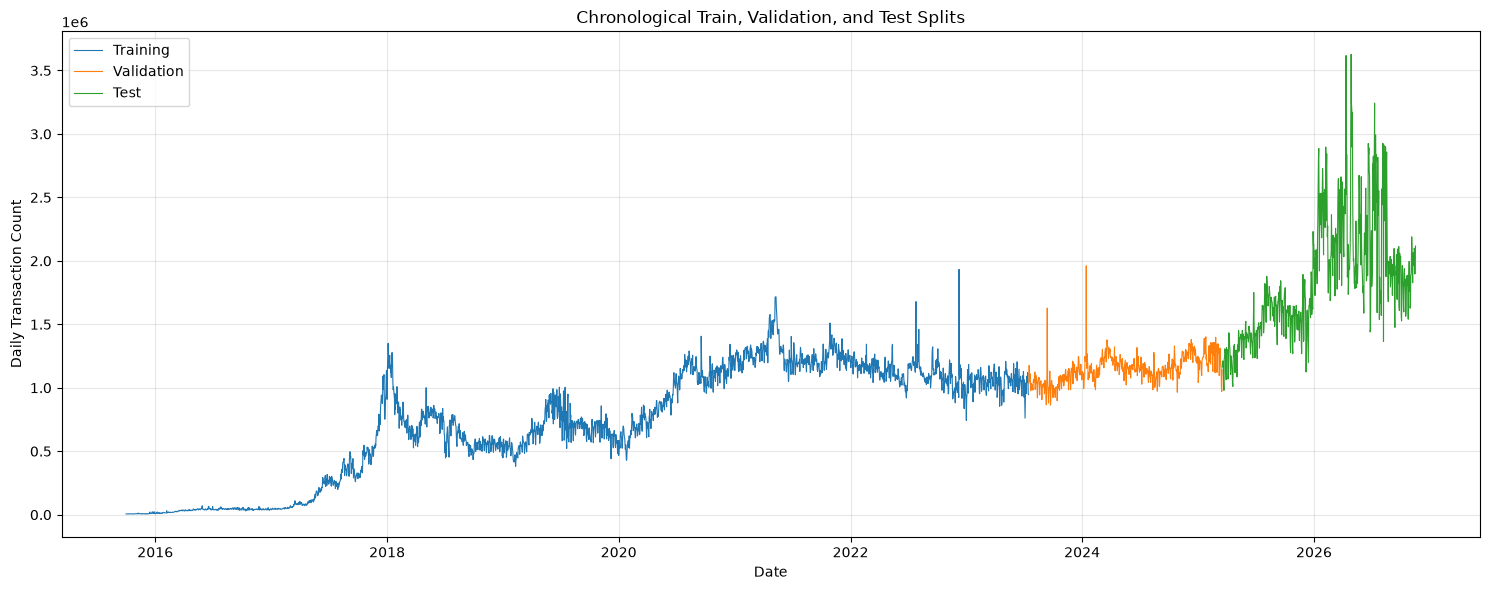

Chart 15 saved successfully!


In [32]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label="Training",
    linewidth=0.8
)

plt.plot(
    validation.index,
    validation,
    label="Validation",
    linewidth=0.8
)

plt.plot(
    test.index,
    test,
    label="Test",
    linewidth=0.8
)

plt.title("Chronological Train, Validation, and Test Splits")

plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "15_chronological_data_splits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 15 saved successfully!")

#### 6.2.1 Interpretation of Chronological Data Splits

The visualisation confirms that the dataset has been divided into three consecutive chronological subsets.

The training period covers the historical observations from October 2015 to July 2023. The validation period follows from July 2023 to March 2025, while the test period covers March 2025 to November 2026.

The plot also illustrates substantial changes in Ethereum daily transaction activity across the three periods, including variations in the overall activity level and short-term fluctuations.

This temporal structure provides an appropriate basis for evaluating forecasting models under changing network activity conditions.

The chronological separation is maintained throughout the subsequent modelling and evaluation procedures to prevent information leakage from future observations.

### 6.3 Forecasting Evaluation Metrics

Forecasting performance is evaluated using quantitative error metrics to assess the accuracy of predicted daily Ethereum transaction counts.

Three evaluation metrics are considered:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted values.
- **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors, giving greater weight to larger errors.
- **Mean Absolute Percentage Error (MAPE):** Expresses prediction errors as percentages of actual values.

MAE and RMSE are selected as the primary evaluation metrics. MAPE is included as a supplementary metric because percentage-based errors can become misleading when actual observations are relatively small.

All metrics will be calculated using actual and predicted values from the same evaluation period. Lower values indicate better forecasting performance.

#### 6.3.1 Implementation of Evaluation Metrics

The evaluation metrics are implemented as reusable Python functions.

These functions will be applied consistently across statistical, machine learning, and deep learning models to ensure a comparable assessment of forecasting performance.

MAPE is included as a supplementary metric, with appropriate caution when actual observations are zero or close to zero.

In [9]:
# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Define reusable evaluation function

def evaluate_forecast(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = mean_absolute_percentage_error(
        actual,
        predicted
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

print("Forecast evaluation metrics defined successfully!")

Forecast evaluation metrics defined successfully!


#### 6.3.2 Verification of Evaluation Metrics

The implementation of the evaluation metrics is verified using a small illustrative dataset containing actual and predicted values.

This preliminary test ensures that the evaluation function calculates MAE, RMSE, and MAPE correctly before it is applied to the forecasting models.

The illustrative values are used only to verify the calculations and are not part of the Ethereum dataset.

In [10]:
# Illustrative actual and predicted values

actual_example = np.array([100, 200, 300, 400, 500])

predicted_example = np.array([110, 190, 320, 380, 510])

# Evaluate example predictions

example_results = evaluate_forecast(
    actual_example,
    predicted_example
)

display(
    pd.DataFrame(
        [example_results],
        index=["Illustrative Example"]
    ).round(4)
)

,MAE,RMSE,MAPE (%)
Illustrative Example,14.0,14.8324,5.7333


#### 6.3.3 Interpretation of Evaluation Metrics Verification

The illustrative example confirms that the evaluation function successfully calculates the three forecasting error metrics.

The Mean Absolute Error (MAE) is 14.0, indicating an average absolute prediction error of 14 units.

The Root Mean Squared Error (RMSE) is approximately 14.8324, reflecting the squared-error-based measure of prediction accuracy.

The Mean Absolute Percentage Error (MAPE) is approximately 5.7333%, indicating the average absolute percentage error across the illustrative observations.

These results confirm that the evaluation function is operating as expected and can be used to assess the forecasting performance of the statistical, machine learning, and deep learning models.

MAE and RMSE will serve as the primary evaluation metrics, while MAPE will provide supplementary information about relative forecasting errors.

## 6.4 Baseline Forecasting Models

Baseline forecasting models provide reference points for evaluating the predictive performance of more advanced statistical, machine learning, and deep learning approaches.

Two baseline methods are considered:

- Naïve forecasting: predicts that future daily transaction activity will remain equal to the most recently observed value.
- Seasonal naïve forecasting: predicts that future daily transaction activity will follow the corresponding values from the previous seven-day period.

Both models provide simple benchmarks against which more sophisticated forecasting approaches can be evaluated.

The validation and test datasets will be used to assess forecasting performance while preserving chronological order.

### 6.4.1 Naïve Forecasting Model

The naïve forecasting model assumes that the next observation will be equal to the most recently observed value.

For a forecasting horizon of multiple days, the last available training observation is repeated across the entire forecast period.

This model provides a simple benchmark and is particularly useful for evaluating whether more advanced models can improve upon persistence-based forecasting.

In [35]:
# Naïve forecasting function

def naive_forecast(last_observed_value, forecast_horizon):

    return np.repeat(
        last_observed_value,
        forecast_horizon
    )


# Generate validation forecast

naive_validation_forecast = naive_forecast(
    train.iloc[-1],
    len(validation)
)

# Evaluate validation forecast

naive_validation_results = evaluate_forecast(
    validation,
    naive_validation_forecast
)

display(
    pd.DataFrame(
        [naive_validation_results],
        index=["Naïve Forecast"]
    ).round(4)
)

,MAE,RMSE,MAPE (%)
Naïve Forecast,203493.2492,228642.3193,17.0565


#### 6.4.1.1 Interpretation of Naïve Forecasting Results

The naïve forecasting model produces a Mean Absolute Error (MAE) of approximately 203,493 transactions and a Root Mean Squared Error (RMSE) of approximately 228,642 transactions on the validation dataset.

The Mean Absolute Percentage Error (MAPE) is approximately 17.06%, indicating an average absolute percentage error of approximately 17% across the validation observations.

These results provide an initial benchmark for forecasting Ethereum daily transaction activity. The relatively substantial prediction errors suggest that simply extending the final observed training value across the validation period may not adequately capture changes in network activity.

The performance of more advanced forecasting models will be compared against this baseline to determine whether they provide meaningful improvements in predictive accuracy.

### 6.4.2 Seasonal Naïve Forecasting Model

The seasonal naïve forecasting model assumes that future observations follow the same pattern as the corresponding observations in the previous seasonal cycle.

For this study, a seasonal period of seven days is used to represent a weekly cycle.

The model generates forecasts by repeating the final seven observations of the training dataset across the forecast horizon.

This approach provides a benchmark for evaluating whether incorporating a simple weekly seasonal pattern improves forecasting accuracy compared with the standard naïve model.

In [36]:
# Seasonal naïve forecasting function

def seasonal_naive_forecast(training_data, forecast_horizon, seasonal_period=7):

    last_season = training_data.iloc[-seasonal_period:].to_numpy()

    repetitions = int(np.ceil(
        forecast_horizon / seasonal_period
    ))

    forecast = np.tile(
        last_season,
        repetitions
    )

    return forecast[:forecast_horizon]


# Generate validation forecast

seasonal_naive_validation_forecast = seasonal_naive_forecast(
    train,
    len(validation),
    seasonal_period=7
)

# Evaluate validation forecast

seasonal_naive_validation_results = evaluate_forecast(
    validation,
    seasonal_naive_validation_forecast
)

display(
    pd.DataFrame(
        [seasonal_naive_validation_results],
        index=["Seasonal Naïve Forecast"]
    ).round(4)
)

,MAE,RMSE,MAPE (%)
Seasonal Naïve Forecast,120320.341,151445.2549,10.0668


#### 6.4.2.1 Interpretation of Seasonal Naïve Forecasting Results

The seasonal naïve forecasting model produces a Mean Absolute Error (MAE) of approximately 120,320 transactions and a Root Mean Squared Error (RMSE) of approximately 151,445 transactions on the validation dataset.

The Mean Absolute Percentage Error (MAPE) is approximately 10.07%.

Compared with the standard naïve model, the seasonal naïve model achieves lower prediction errors across all three evaluation metrics.

The MAE decreases from approximately 203,493 to 120,320 transactions, while the RMSE decreases from approximately 228,642 to 151,445 transactions. MAPE also decreases from approximately 17.06% to 10.07%.

These findings suggest that incorporating a seven-day repeating pattern improves forecasting accuracy during the validation period.

However, the seasonal naïve model remains a simple benchmark and does not explicitly account for long-term trends or changes in network activity.

### 6.4.3 Comparison of Baseline Forecasting Models

The forecasting performance of the standard naïve and seasonal naïve models is compared using the validation dataset.

The comparison considers MAE, RMSE, and MAPE to determine whether incorporating a weekly seasonal pattern improves predictive accuracy.

The percentage reduction in forecasting errors is also calculated to quantify the improvement achieved by the seasonal naïve model relative to the standard naïve model.

In [37]:
# Create baseline comparison table

baseline_comparison = pd.DataFrame(
    {
        "Naïve Forecast": naive_validation_results,
        "Seasonal Naïve Forecast": seasonal_naive_validation_results
    }
).T

# Calculate percentage error reduction

error_reduction = (
    (baseline_comparison.loc["Naïve Forecast"] -
     baseline_comparison.loc["Seasonal Naïve Forecast"])
    / baseline_comparison.loc["Naïve Forecast"]
) * 100

display(baseline_comparison.round(4))

print("\nPercentage Error Reduction:")
display(error_reduction.to_frame(
    name="Reduction (%)"
).round(2))

,MAE,RMSE,MAPE (%)
Naïve Forecast,203493.2492,228642.3193,17.0565
Seasonal Naïve Forecast,120320.3410,151445.2549,10.0668



Percentage Error Reduction:


,Reduction (%)
MAE,40.87
RMSE,33.76
MAPE (%),40.98


#### 6.4.3.1 Interpretation of Baseline Model Comparison

The comparison of baseline forecasting models reveals a substantial improvement in predictive accuracy when a seven-day seasonal pattern is incorporated.

The seasonal naïve model achieves an MAE of approximately 120,320 transactions, compared with 203,493 transactions for the standard naïve model. This represents a reduction of approximately 40.87%.

Similarly, RMSE decreases by approximately 33.76%, from 228,642 to 151,445 transactions. MAPE also decreases by approximately 40.98%, from 17.06% to 10.07%.

These results indicate that the seasonal naïve model provides a considerably stronger benchmark for forecasting Ethereum daily transaction activity than the standard naïve model.

The improvement suggests that weekly temporal dependencies contain useful predictive information. However, the seasonal naïve model does not explicitly capture long-term trends, structural changes, or evolving seasonal behaviour.

Consequently, more advanced statistical forecasting models will be investigated to determine whether they can achieve further improvements over this baseline.

### 6.4.4 Visual Comparison of Baseline Forecasts

The actual validation observations are compared with the forecasts generated by the standard naïve and seasonal naïve models.

This visualisation illustrates the differences between the forecasting approaches and provides an intuitive assessment of their ability to reproduce changes in Ethereum daily transaction activity.

The comparison focuses on the validation period and complements the quantitative evaluation metrics.

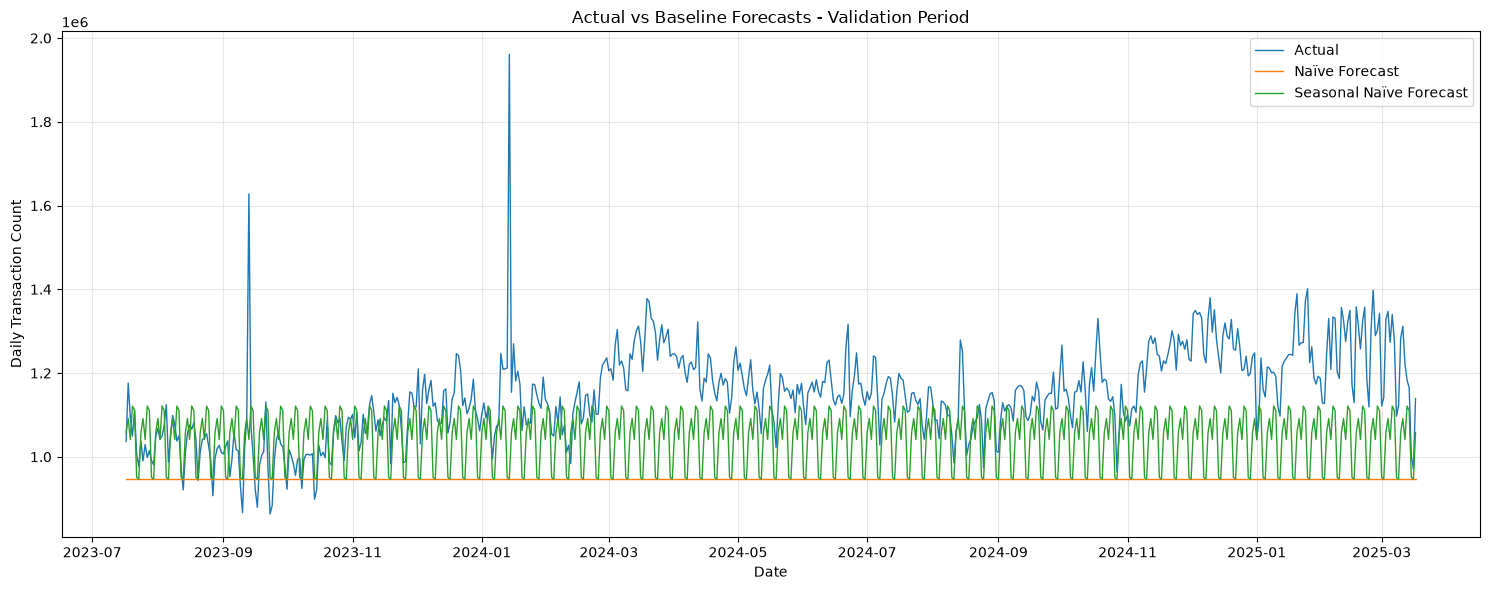

Chart 16 saved successfully!


In [38]:
plt.figure(figsize=(15, 6))

plt.plot(
    validation.index,
    validation.values,
    label="Actual",
    linewidth=1
)

plt.plot(
    validation.index,
    naive_validation_forecast,
    label="Naïve Forecast",
    linewidth=1
)

plt.plot(
    validation.index,
    seasonal_naive_validation_forecast,
    label="Seasonal Naïve Forecast",
    linewidth=1
)

plt.title("Actual vs Baseline Forecasts - Validation Period")

plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "16_baseline_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 16 saved successfully!")

#### 6.4.4.1 Inspection of Baseline Forecast Values

This subsection examines the initial observations of the actual validation series and the corresponding baseline forecasts.

The purpose is to verify that both forecasting methods use the final available training observations correctly and that the forecasts are aligned with the validation dates.

In [39]:
# Compare the first 14 validation observations

forecast_inspection = pd.DataFrame({
    "Actual": validation.iloc[:14].values,
    "Naive_Forecast": naive_validation_forecast[:14],
    "Seasonal_Naive_Forecast": seasonal_naive_validation_forecast[:14]
}, index=validation.index[:14])

display(forecast_inspection.round(0))

print("\nLast 7 training observations:")
display(train.tail(7))

,Actual,Naive_Forecast,Seasonal_Naive_Forecast
block_date,,,
2023-07-17,1036419,946750,1057858
2023-07-18,1175963,946750,1091428
2023-07-19,1093783,946750,1041317
2023-07-20,1049510,946750,1121269
2023-07-21,1110882,946750,1110332
2023-07-22,1004374,946750,950700
2023-07-23,977305,946750,946750
2023-07-24,1036300,946750,1057858
2023-07-25,990249,946750,1091428



Last 7 training observations:


block_date
2023-07-10    1057858
2023-07-11    1091428
2023-07-12    1041317
2023-07-13    1121269
2023-07-14    1110332
2023-07-15     950700
2023-07-16     946750
Freq: D, Name: daily_transaction_count, dtype: int64

#### 6.4.4.2 Interpretation of Baseline Forecast Comparison

The visual comparison illustrates the different forecasting behaviours of the two baseline models.

The standard naïve model produces a constant forecast because it repeats the final observation from the training period throughout the validation horizon.

In contrast, the seasonal naïve model reproduces the seven-day pattern observed at the end of the training period. Consequently, its forecasts exhibit recurring weekly fluctuations.

Although the seasonal naïve forecasts capture a repeating weekly pattern, neither baseline model adapts to longer-term changes in Ethereum transaction activity during the validation period.

The visualisation therefore highlights the limitations of simple baseline forecasting approaches when applied to a long forecasting horizon.

These findings support the investigation of more advanced forecasting models capable of capturing both temporal dependencies and changes in network activity.


## 6.5 Statistical Forecasting Models

This section investigates statistical time-series forecasting models for predicting Ethereum daily transaction activity.

Statistical models are selected based on the temporal characteristics identified during exploratory data analysis, including non-stationarity in the original series, strong autocorrelation, and potential weekly seasonal dependencies.

The following models will be investigated:

- Autoregressive Integrated Moving Average (ARIMA)
- Seasonal Autoregressive Integrated Moving Average (SARIMA)

Model parameters will be selected using the training and validation datasets. Forecasting performance will be evaluated using MAE, RMSE, and MAPE.

The statistical models will be compared against the baseline forecasting approaches established in the previous section.

### 6.5.1 Autoregressive Integrated Moving Average (ARIMA)

The Autoregressive Integrated Moving Average (ARIMA) model is a widely used statistical approach for time-series forecasting.

ARIMA combines three components:

- **Autoregressive (AR):** Models relationships between current observations and their previous values.
- **Integrated (I):** Applies differencing to achieve stationarity.
- **Moving Average (MA):** Models relationships between current observations and previous forecast errors.

The ARIMA model is represented by three parameters:

- p: Autoregressive order.
- d: Degree of differencing.
- q: Moving average order.

Previous stationarity tests indicated that first-order differencing is sufficient to achieve stationarity in the Ethereum transaction-count series. Therefore, an integration order of d = 1 will be used initially.

The autoregressive and moving-average orders will be investigated using autocorrelation analysis and model selection procedures.

#### 6.5.1.1 Preparing the ARIMA Training Series

The original daily transaction-count series is used as the input for ARIMA modelling.

The model will apply differencing internally through its integration parameter. Therefore, the pre-differenced series will not be used as the model input.

Only the training observations are used during model fitting to prevent information leakage from the validation and test periods.

In [40]:
# Inspect ARIMA training series

print("Training observations:", len(train))
print("Start date:", train.index.min())
print("End date:", train.index.max())
print("Frequency:", train.index.freq)

print("\nMissing values:", train.isna().sum())

print("\nTraining series descriptive statistics:")
display(train.describe())

Training observations: 2846
Start date: 2015-10-01 00:00:00
End date: 2023-07-16 00:00:00
Frequency: <Day>

Missing values: 0

Training series descriptive statistics:


count    2.846000e+03
mean     7.141668e+05
std      4.422923e+05
min      5.830000e+03
25%      3.400668e+05
50%      7.484670e+05
75%      1.109638e+06
max      1.932711e+06
Name: daily_transaction_count, dtype: float64

#### 6.5.1.2 Interpretation of ARIMA Training Data

The training dataset contains 2,846 daily observations covering the period from 1 October 2015 to 16 July 2023.

The series has a continuous daily frequency and contains no missing observations, providing a consistent temporal structure for ARIMA modelling.

The mean daily transaction count is approximately 714,167, with a standard deviation of approximately 442,292 transactions.

The observed values range from 5,830 to 1,932,711 transactions per day, indicating substantial variation in Ethereum network activity during the training period.

The original transaction-count series is retained as the model input because differencing will be performed internally by the ARIMA model using its integration parameter.

#### 6.5.1.3 ACF and PACF Analysis of the Differenced Training Series

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) are examined using the first-order differenced training series.

These plots provide preliminary information about the autoregressive and moving-average components of the ARIMA model.

The analysis focuses exclusively on the training dataset to prevent information leakage from subsequent validation and test observations.

The resulting patterns will guide the selection of candidate ARIMA model orders.

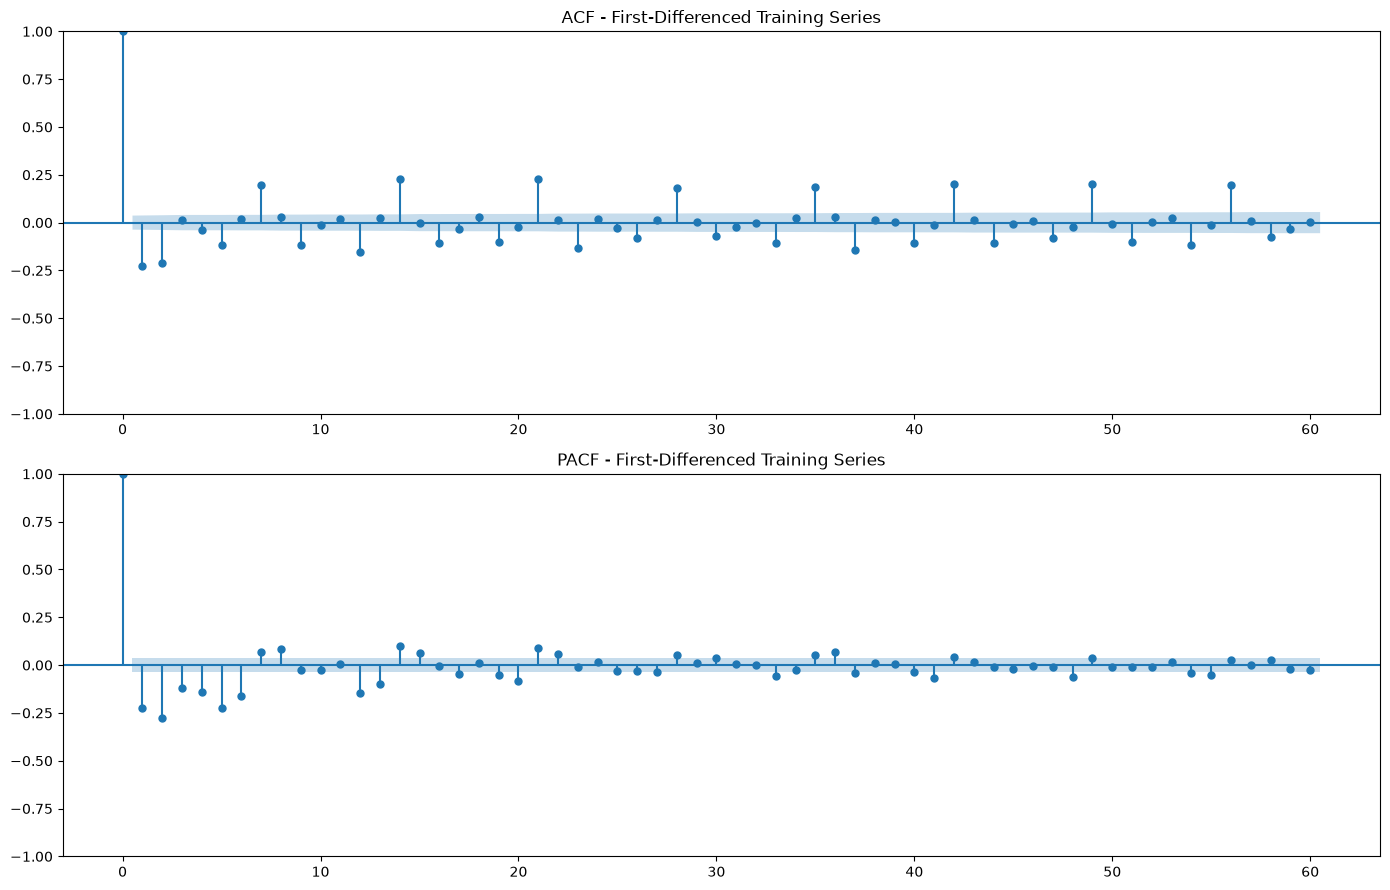

Chart 17 saved successfully!


In [41]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# First-order differencing of training data

train_diff1 = train.diff().dropna()

# Plot ACF and PACF

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    train_diff1,
    lags=60,
    ax=axes[0]
)

axes[0].set_title("ACF - First-Differenced Training Series")

plot_pacf(
    train_diff1,
    lags=60,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF - First-Differenced Training Series")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "17_acf_pacf_arima_training_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 17 saved successfully!")

#### Interpretation of ACF and PACF Analysis

The ACF and PACF plots of the first-differenced training series reveal a complex autocorrelation structure.

The ACF exhibits significant positive autocorrelations at multiples of seven, including lags 7, 14, 21, and 28. Significant negative autocorrelations are also observed at several intervening lags.

The PACF shows significant positive values around weekly intervals, particularly at lags 7–8, 14–15, and 21–22. Significant negative partial autocorrelations occur at several shorter and intermediate lags, including lags 1–6, 12–13, 17, and 19–20.

Together, these patterns indicate that first-order differencing removes the non-stationarity but does not eliminate the weekly temporal dependencies.

The repeated patterns around multiples of seven support investigating seasonal autoregressive and moving-average components.

However, the complex ACF and PACF structures do not provide an unambiguous identification of the AR and MA orders. Therefore, a limited set of candidate ARIMA models will be evaluated before proceeding to seasonal ARIMA modelling.

#### 6.5.1.4 Fitting Candidate ARIMA Models

Based on the ACF and PACF analysis, three candidate non-seasonal ARIMA models are selected for initial evaluation:

- ARIMA(1,1,0)
- ARIMA(0,1,1)
- ARIMA(1,1,1)

All three models use first-order differencing (d = 1), consistent with the stationarity analysis.

The models are fitted using the original training series. Differencing is performed internally by the ARIMA model.

Model fitting is restricted to the training dataset to prevent information leakage from the validation and test periods.

In [42]:
from statsmodels.tsa.arima.model import ARIMA
import time

# Define candidate ARIMA orders
arima_orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1)
]

# Store fitted models and results
arima_models = {}
arima_model_results = []

# Fit candidate models
for order in arima_orders:

    print(f"\nFitting ARIMA{order}...")

    start_time = time.time()

    model = ARIMA(
        train,
        order=order
    )

    fitted_model = model.fit()

    elapsed_time = time.time() - start_time

    arima_models[order] = fitted_model

    arima_model_results.append({
        "Model": f"ARIMA{order}",
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "Log Likelihood": fitted_model.llf,
        "Fitting Time (seconds)": elapsed_time
    })

    print(f"Completed in {elapsed_time:.2f} seconds")

# Display model comparison
arima_comparison = pd.DataFrame(arima_model_results)

display(
    arima_comparison.round(3)
)


Fitting ARIMA(1, 1, 0)...
Completed in 2.41 seconds

Fitting ARIMA(0, 1, 1)...
Completed in 0.67 seconds

Fitting ARIMA(1, 1, 1)...
Completed in 1.02 seconds


,Model,AIC,BIC,Log Likelihood,Fitting Time (seconds)
0,"ARIMA(1, 1, 0)",70767.585,70779.492,-35381.792,2.407
1,"ARIMA(0, 1, 1)",70573.936,70585.842,-35284.968,0.666
2,"ARIMA(1, 1, 1)",70380.316,70398.176,-35187.158,1.021


#### Interpretation of Candidate ARIMA Model Comparison

Three candidate ARIMA models were fitted using the training dataset.

Among the evaluated models, ARIMA(1,1,1) achieved the lowest AIC (70,380.316) and BIC (70,398.176), indicating the best information-criterion performance.

ARIMA(0,1,1) ranked second, while ARIMA(1,1,0) produced the highest AIC and BIC values.

All three models were fitted successfully, with computational times below three seconds.

Based on these preliminary results, ARIMA(1,1,1) is selected as the leading candidate. However, information criteria alone are insufficient to establish forecasting superiority. The candidate models will therefore be evaluated using out-of-sample forecasts on the validation dataset.

#### 6.5.1.5 ARIMA Validation Forecasting

The forecasting performance of the candidate ARIMA models is evaluated using the validation dataset.

Each fitted model generates forecasts for the complete validation period of 610 days.

The models remain fitted exclusively on the training observations. Validation observations are not used to update model parameters.

This fixed-origin forecasting approach ensures a consistent comparison with the baseline models evaluated previously.

In [43]:
# Generate validation forecasts for candidate ARIMA models

arima_validation_forecasts = {}
arima_validation_results = []

for order, fitted_model in arima_models.items():

    forecast = fitted_model.forecast(
        steps=len(validation)
    )

    arima_validation_forecasts[order] = forecast

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    arima_validation_results.append({
        "Model": f"ARIMA{order}",
        **metrics
    })

# Create validation comparison table
arima_validation_comparison = pd.DataFrame(
    arima_validation_results
)

display(
    arima_validation_comparison.round(3)
)

,Model,MAE,RMSE,MAPE (%)
0,"ARIMA(1, 1, 0)",202800.057,228003.753,16.996
1,"ARIMA(0, 1, 1)",162780.932,191437.761,13.536
2,"ARIMA(1, 1, 1)",149920.167,179174.323,12.443


#### Interpretation of ARIMA Validation Forecasts

The validation results indicate that ARIMA(1,1,1) achieved the best forecasting performance among the three candidate ARIMA models.

It obtained an MAE of 149,920.167, an RMSE of 179,174.323, and a MAPE of 12.443%.

ARIMA(1,1,1) outperformed both ARIMA(0,1,1) and ARIMA(1,1,0) across all three evaluation metrics.

However, comparison with the baseline models revealed that the seasonal naïve model achieved lower forecasting errors than ARIMA(1,1,1).

This finding suggests that weekly seasonal dependencies play an important role in Ethereum transaction activity and are not adequately captured by the non-seasonal ARIMA specification.

Consequently, ARIMA(1,1,1) is retained as the best non-seasonal ARIMA candidate, while seasonal ARIMA modelling will be investigated to determine whether explicitly modelling weekly dependencies improves forecasting accuracy.

#### 6.5.1.6 Residual Diagnostics of ARIMA(1,1,1)

Residual diagnostics are conducted to assess the adequacy of the selected non-seasonal ARIMA model.

The residuals represent the differences between the observed training values and the values fitted by the model.

A well-specified time-series model should produce residuals that behave approximately like white noise, with no substantial remaining autocorrelation.

The residuals of ARIMA(1,1,1) are examined using time-series plots, distribution analysis, autocorrelation plots, and the Ljung–Box test.

In [44]:
# Extract residuals from ARIMA(1,1,1)

best_arima_model = arima_models[(1, 1, 1)]

arima_residuals = best_arima_model.resid

print("Residual observations:", len(arima_residuals))
print("Missing residuals:", arima_residuals.isna().sum())

print("\nResidual descriptive statistics:")
display(arima_residuals.describe().round(3))

Residual observations: 2846
Missing residuals: 0

Residual descriptive statistics:


count      2846.000
mean       1160.806
std       56822.260
min     -430200.394
25%      -22943.994
50%         177.727
75%       24027.094
max      977043.515
dtype: float64

#### 6.5.1.6.1 Visual Inspection of ARIMA Residuals

The residual time series and residual distribution are examined to identify systematic patterns, changes in variability, and deviations from an approximately normal distribution.

A well-specified model should produce residuals fluctuating around zero without an obvious temporal pattern.

The residual histogram provides additional information about their distribution and potential asymmetry.

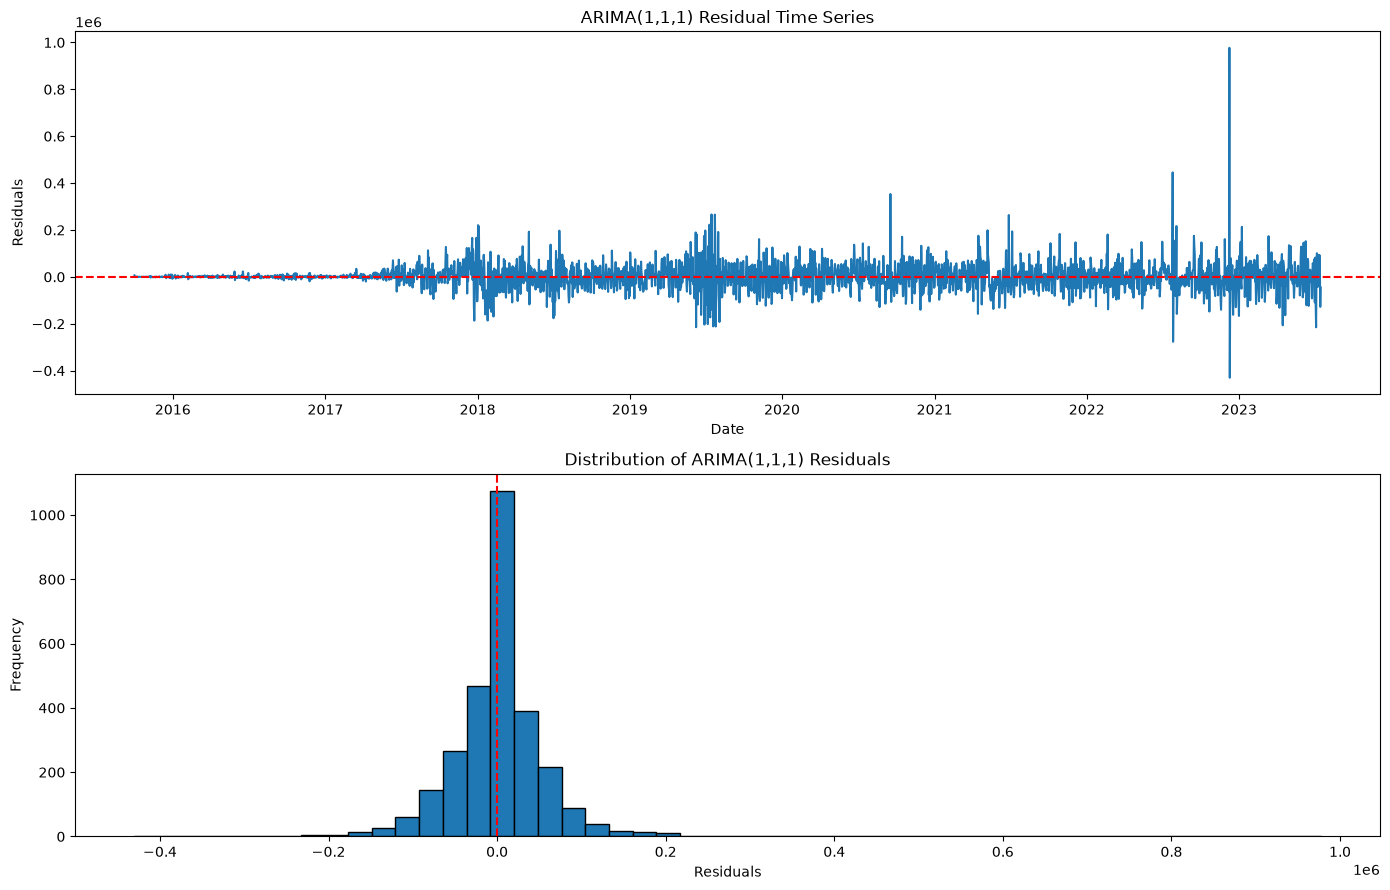

Chart 18 saved successfully!


In [45]:
# Plot ARIMA residual time series and distribution

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Residual time series
axes[0].plot(arima_residuals)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("ARIMA(1,1,1) Residual Time Series")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residuals")

# Residual distribution
axes[1].hist(
    arima_residuals,
    bins=50,
    edgecolor="black"
)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribution of ARIMA(1,1,1) Residuals")
axes[1].set_xlabel("Residuals")
axes[1].set_ylabel("Frequency")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "18_arima_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 18 saved successfully!")

#### Interpretation of ARIMA(1,1,1) Residual Plots

The residual time-series plot shows considerable fluctuations, particularly between mid-2017 and 2024. This suggests that the model does not fully capture changes in the magnitude and variability of Ethereum transaction activity throughout the training period.

The residual histogram appears approximately bell-shaped and centred around zero, suggesting that the residual distribution is reasonably symmetric.

However, visual normality alone does not establish that the residuals behave as white noise. Remaining autocorrelation and possible temporal dependence must also be investigated.

Therefore, additional diagnostic analysis using the residual ACF and the Ljung–Box test is required to assess the adequacy of the ARIMA(1,1,1) model.

#### 6.5.1.6.2 Residual Autocorrelation Analysis

The Autocorrelation Function (ACF) of the ARIMA(1,1,1) residuals is examined to identify remaining temporal dependencies.

For an adequate forecasting model, residual autocorrelations should generally remain within the 95% confidence intervals.

Particular attention is given to weekly seasonal lags, including 7, 14, 21, and 28, because the earlier analysis identified substantial weekly dependencies.

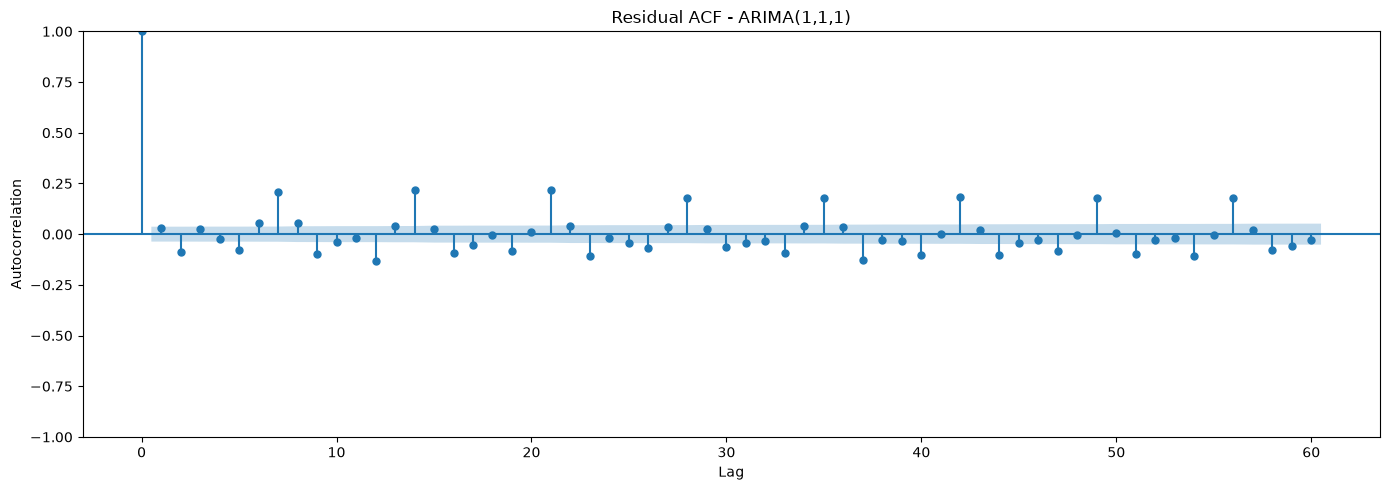

Chart 19 saved successfully!


In [46]:
from statsmodels.graphics.tsaplots import plot_acf

# Plot residual ACF
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    arima_residuals,
    lags=60,
    ax=ax
)

ax.set_title("Residual ACF - ARIMA(1,1,1)")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "19_arima_residual_acf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 19 saved successfully!")

#### 6.5.1.6.3 Interpretation of Residual Autocorrelation

The residual ACF of ARIMA(1,1,1) reveals several significant positive and negative autocorrelations.

Positive autocorrelation is particularly evident around weekly intervals, including lags 7, 14, 21, and 28. Smaller positive spikes are also observed at lags 6 and 8.

Significant negative autocorrelations occur at several intervening lags, including lags 2, 5, 9, 12, 16–17, 19, 23, and 25–26.

The persistence of significant autocorrelation, particularly at weekly intervals, indicates that the residuals do not behave entirely like white noise.

These findings suggest that the non-seasonal ARIMA(1,1,1) model does not fully capture the temporal dependencies in Ethereum daily transaction activity.

Consequently, seasonal ARIMA modelling is warranted to investigate whether explicitly incorporating weekly seasonal components improves the representation of the time series.

#### 6.5.1.6.4 Ljung–Box Test for Residual Autocorrelation

The Ljung–Box test is applied to the residuals of ARIMA(1,1,1) to determine whether significant autocorrelation remains across multiple lags.

The null and alternative hypotheses are:

- H0: Residuals are independently distributed, with no autocorrelation up to the specified lag.
- H1: Residuals exhibit significant autocorrelation at one or more lags.

The test is conducted at lags 7, 14, 21, and 28 to investigate remaining weekly temporal dependencies.

A significance level of 0.05 is used.

In [47]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box test on ARIMA residuals
ljung_box_results = acorr_ljungbox(
    arima_residuals,
    lags=[7, 14, 21, 28],
    model_df=2,
    return_df=True
)

display(ljung_box_results.round(6))

,lb_stat,lb_pvalue
7,180.465248,0.0
14,410.969518,0.0
21,605.690300,0.0
28,757.765569,0.0


#### 6.5.1.6.5 Interpretation of the Ljung–Box Test

The Ljung–Box test was conducted on the residuals of ARIMA(1,1,1) at lags 7, 14, 21, and 28.

All four tests produced highly significant results, with p-values below 0.05.

Consequently, the null hypothesis of no residual autocorrelation is rejected at every tested lag.

The results indicate that substantial temporal dependencies remain unexplained by the non-seasonal ARIMA(1,1,1) model.

Combined with the residual ACF analysis, these findings provide evidence that weekly seasonal dependencies have not been adequately captured.

Therefore, the non-seasonal ARIMA(1,1,1) model is retained as a benchmark, and seasonal ARIMA modelling is justified as the next stage of the analysis.

## 6.5.2 Seasonal Autoregressive Integrated Moving Average (SARIMA)

The residual diagnostics of the non-seasonal ARIMA(1,1,1) model revealed significant remaining autocorrelation, particularly at weekly intervals.

To investigate these dependencies, seasonal autoregressive integrated moving average (SARIMA) models are introduced.

SARIMA extends the ARIMA framework by incorporating seasonal autoregressive, differencing, and moving-average components.

The general model specification is:

SARIMA(p,d,q)(P,D,Q)s

where:

- p: Non-seasonal autoregressive order.
- d: Non-seasonal differencing order.
- q: Non-seasonal moving-average order.
- P: Seasonal autoregressive order.
- D: Seasonal differencing order.
- Q: Seasonal moving-average order.
- s: Seasonal period.

Based on the previous stationarity and autocorrelation analyses, the initial seasonal period is set to seven days to represent weekly patterns.

First-order non-seasonal differencing (d = 1) is retained, while seasonal differencing is initially omitted (D = 0).

Candidate seasonal autoregressive and moving-average components will be evaluated to determine whether explicitly modelling weekly dependencies improves forecasting performance.

### 6.5.2.1 Selection of Candidate SARIMA Models

The ACF and PACF analyses indicate persistent weekly dependencies in the first-differenced training series.

To investigate these dependencies, three candidate SARIMA models are selected:

- SARIMA(1,1,1)(1,0,0,7)
- SARIMA(1,1,1)(0,0,1,7)
- SARIMA(1,1,1)(1,0,1,7)

The non-seasonal component is retained as ARIMA(1,1,1), which achieved the best validation performance among the initial ARIMA candidates.

The seasonal period is set to seven days to represent weekly patterns. Seasonal differencing is initially excluded (D = 0), based on the previous differencing analysis.

All models will be fitted using the original training series. Their forecasting performance will subsequently be evaluated using the validation dataset.

#### 6.5.2.2 Fitting Candidate SARIMA Models

The selected SARIMA candidates are fitted using the training dataset.

The seasonal autoregressive and moving-average components are incorporated to capture weekly temporal dependencies.

A limited number of candidate models is evaluated to keep computational requirements manageable.

AIC and BIC are used for preliminary model comparison, while validation forecasting errors will determine their practical predictive performance.

In [50]:
# Fit candidate SARIMA models

sarima_orders = [
    ((1, 1, 1), (1, 0, 0, 7)),
    ((1, 1, 1), (0, 0, 1, 7)),
    ((1, 1, 1), (1, 0, 1, 7))
]

sarima_models = {}
sarima_model_results = []

for order, seasonal_order in sarima_orders:

    model_name = f"SARIMA{order}{seasonal_order}"

    print(f"\nFitting {model_name}...")

    start_time = time.time()

    model = ARIMA(
        train,
        order=order,
        seasonal_order=seasonal_order
    )

    fitted_model = model.fit()

    elapsed_time = time.time() - start_time

    sarima_models[(order, seasonal_order)] = fitted_model

    sarima_model_results.append({
        "Model": model_name,
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "Log Likelihood": fitted_model.llf,
        "Fitting Time (seconds)": elapsed_time
    })

    print(f"Completed in {elapsed_time:.2f} seconds")

# Display SARIMA model comparison
sarima_comparison = pd.DataFrame(sarima_model_results)

display(sarima_comparison.round(3))


Fitting SARIMA(1, 1, 1)(1, 0, 0, 7)...
Completed in 2.38 seconds

Fitting SARIMA(1, 1, 1)(0, 0, 1, 7)...
Completed in 2.31 seconds

Fitting SARIMA(1, 1, 1)(1, 0, 1, 7)...
Completed in 6.59 seconds


,Model,AIC,BIC,Log Likelihood,Fitting Time (seconds)
0,"SARIMA(1, 1, 1)(1, 0, 0, 7)",70263.231,70287.045,-35127.616,2.381
1,"SARIMA(1, 1, 1)(0, 0, 1, 7)",70294.520,70318.333,-35143.260,2.314
2,"SARIMA(1, 1, 1)(1, 0, 1, 7)",69905.017,69934.783,-34947.508,6.592


#### Interpretation of Candidate SARIMA Model Comparison

All three candidate SARIMA models were successfully fitted using the training dataset.

Among the evaluated models, SARIMA(1,1,1)(1,0,1,7) achieved the lowest AIC (69,905.017) and BIC (69,934.783).

Compared with the non-seasonal ARIMA(1,1,1) model, the selected SARIMA candidate reduced AIC by 475.299 points and BIC by 463.393 points.

These results indicate that incorporating weekly seasonal autoregressive and moving-average components improves the in-sample model fit.

The computational requirements were also manageable, with the most complex candidate completing in approximately eight seconds.

However, information criteria alone cannot establish forecasting superiority. The candidate SARIMA models will therefore be evaluated on the validation dataset using MAE, RMSE, and MAPE.

#### 6.5.2.3 SARIMA Validation Forecasting

The forecasting performance of the candidate SARIMA models is evaluated using the validation dataset.

Each fitted model generates forecasts for the complete 610-day validation period.

The models remain fitted exclusively on the training observations, without updating their parameters using validation data.

Forecasting accuracy is assessed using MAE, RMSE, and MAPE to ensure consistency with the previously evaluated baseline and ARIMA models.

In [51]:
# Generate validation forecasts for candidate SARIMA models

sarima_validation_forecasts = {}
sarima_validation_results = []

for (order, seasonal_order), fitted_model in sarima_models.items():

    model_name = f"SARIMA{order}{seasonal_order}"

    print(f"Forecasting with {model_name}...")

    forecast = fitted_model.forecast(
        steps=len(validation)
    )

    sarima_validation_forecasts[(order, seasonal_order)] = forecast

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    sarima_validation_results.append({
        "Model": model_name,
        **metrics
    })

# Create validation comparison table
sarima_validation_comparison = pd.DataFrame(
    sarima_validation_results
)

display(sarima_validation_comparison.round(3))

Forecasting with SARIMA(1, 1, 1)(1, 0, 0, 7)...
Forecasting with SARIMA(1, 1, 1)(0, 0, 1, 7)...
Forecasting with SARIMA(1, 1, 1)(1, 0, 1, 7)...


,Model,MAE,RMSE,MAPE (%)
0,"SARIMA(1, 1, 1)(1, 0, 0, 7)",142453.430,171900.787,11.814
1,"SARIMA(1, 1, 1)(0, 0, 1, 7)",144260.844,173690.918,11.965
2,"SARIMA(1, 1, 1)(1, 0, 1, 7)",197541.587,231279.149,16.476


#### Interpretation of SARIMA Validation Forecasts

The validation results indicate that SARIMA(1,1,1)(1,0,0,7) achieved the best forecasting performance among the three candidate SARIMA models.

It obtained an MAE of 142,453.430, an RMSE of 171,900.787, and a MAPE of 11.814%.

Although SARIMA(1,1,1)(1,0,1,7) achieved the lowest AIC and BIC during model fitting, it produced substantially higher validation errors. This demonstrates that better in-sample information criteria do not necessarily translate into better out-of-sample forecasting performance.

Compared with the non-seasonal ARIMA(1,1,1), the best SARIMA candidate improved MAE by approximately 5.0%, RMSE by 4.1%, and MAPE by 5.1%.

However, the seasonal naïve model continued to outperform all evaluated statistical models.

These findings suggest that explicitly modelling weekly seasonal dependencies provides some improvement over non-seasonal ARIMA, although the seasonal naïve benchmark remains particularly competitive.

SARIMA(1,1,1)(1,0,0,7) is therefore retained as the best seasonal statistical candidate for subsequent evaluation.

#### 6.5.2.4 Consolidated Comparison of Baseline, ARIMA, and SARIMA Models

The validation performance of all baseline and statistical forecasting models is consolidated to identify the strongest statistical approach.

The comparison includes naïve, seasonal naïve, ARIMA, and SARIMA models.

MAE, RMSE, and MAPE are used to evaluate forecasting accuracy. Lower values indicate better predictive performance.

The results provide a common benchmark for comparison with subsequent machine-learning and deep-learning models.

In [52]:
# Consolidate validation results from all forecasting models

baseline_comparison = pd.DataFrame([
    {
        "Model": "Naive",
        **naive_validation_results
    },
    {
        "Model": "Seasonal Naive",
        **seasonal_naive_validation_results
    }
])

arima_comparison_validation = arima_validation_comparison.copy()

sarima_comparison_validation = sarima_validation_comparison.copy()

# Combine all model results
all_statistical_results = pd.concat(
    [
        baseline_comparison,
        arima_comparison_validation,
        sarima_comparison_validation
    ],
    ignore_index=True
)

# Sort by MAE
all_statistical_results = all_statistical_results.sort_values(
    by="MAE"
).reset_index(drop=True)

display(all_statistical_results.round(3))

,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive,120320.341,151445.255,10.067
1,"SARIMA(1, 1, 1)(1, 0, 0, 7)",142453.430,171900.787,11.814
2,"SARIMA(1, 1, 1)(0, 0, 1, 7)",144260.844,173690.918,11.965
3,"ARIMA(1, 1, 1)",149920.167,179174.323,12.443
4,"ARIMA(0, 1, 1)",162780.932,191437.761,13.536
5,"SARIMA(1, 1, 1)(1, 0, 1, 7)",197541.587,231279.149,16.476
6,"ARIMA(1, 1, 0)",202800.057,228003.753,16.996
7,Naive,203493.249,228642.319,17.057


#### 6.5.2.5 Overall Interpretation of Statistical Forecasting Models

The consolidated validation results demonstrate substantial differences in forecasting performance among the baseline and statistical models.

The Seasonal Naïve model achieved the best overall performance, with an MAE of 120,320.341, an RMSE of 151,445.255, and a MAPE of 10.067%.

Among the statistical models, SARIMA(1,1,1)(1,0,0,7) achieved the lowest forecasting errors, outperforming the non-seasonal ARIMA(1,1,1) model across all three evaluation metrics.

These findings indicate that incorporating weekly seasonal components improves the forecasting performance of the non-seasonal ARIMA specification.

However, the Seasonal Naïve model remained superior to all evaluated statistical models. This suggests that weekly seasonal patterns provide substantial predictive information and represent a strong benchmark for more advanced forecasting approaches.

The results also demonstrate that improved in-sample information criteria do not necessarily translate into better out-of-sample forecasting accuracy.

The Seasonal Naïve model is retained as the strongest overall benchmark, while SARIMA(1,1,1)(1,0,0,7) is retained as the best-performing statistical model.

## 6.6 Machine Learning Forecasting Models

This section investigates machine-learning approaches for forecasting Ethereum daily transaction activity.

Unlike statistical time-series models, machine-learning algorithms do not inherently account for temporal ordering or autocorrelation. Therefore, historical observations and calendar information must be transformed into predictive features.

The following machine-learning models will be investigated:

- Random Forest Regression
- Extreme Gradient Boosting (XGBoost)

Feature engineering will incorporate historical transaction counts, lagged observations, rolling statistics, and calendar-based variables.

The models will be trained using the training dataset and evaluated using the validation dataset.

Forecasting performance will be assessed using MAE, RMSE, and MAPE, allowing direct comparison with the baseline and statistical models established in the previous sections.

### 6.6.1 Random Forest Regression

Random Forest is an ensemble machine-learning algorithm that combines multiple decision trees to generate predictions.

For regression tasks, individual tree predictions are aggregated to produce the final forecast.

Random Forest can capture nonlinear relationships and interactions between predictive variables without requiring an explicit mathematical specification of the time-series structure.

In this study, Random Forest is applied to Ethereum daily transaction-count forecasting using engineered temporal features.

These features include lagged transaction counts, rolling statistical measures, and calendar-based variables.

The model will be evaluated using a chronological forecasting framework to prevent information leakage from future observations.

#### 6.6.1.1 Feature Engineering for Random Forest

Feature engineering transforms the original time series into a supervised learning dataset.

Historical transaction counts are used to construct lagged predictors, while rolling statistics capture recent levels and variability in network activity.

Calendar-based features represent recurring temporal patterns, including weekly and monthly effects.

The selected predictors include:

- Lagged transaction counts at 1, 7, 14, and 28 days.
- Seven-day and thirty-day rolling means.
- Seven-day rolling standard deviation.
- Day of the week, day of the month, and calendar month.

Rolling statistics are calculated using observations available before the forecast date to prevent information leakage.

For fixed-origin multi-step forecasting, future predictions will be generated recursively. Previously predicted values will be used to construct the features required for subsequent forecast dates.

#### 6.6.1.2 Creating the Feature Engineering Dataset

A supervised learning dataset is constructed from the training time series using lagged observations, rolling statistical measures, and calendar-based predictors.

All lagged and rolling features are calculated using historical observations preceding each target date. The first 30 observations are excluded because a complete 30-day historical window is required.

The resulting dataset contains the predictors and target variable required to train the Random Forest regression model.

In [ ]:
# Create supervised learning features

def create_features(series):

    features = pd.DataFrame(index=series.index)

    # Lagged transaction counts
    features["lag_1"] = series.shift(1)
    features["lag_7"] = series.shift(7)
    features["lag_14"] = series.shift(14)
    features["lag_28"] = series.shift(28)

    # Rolling statistics based only on previous observations
    shifted_series = series.shift(1)

    features["rolling_mean_7"] = (
        shifted_series.rolling(window=7).mean()
    )

    features["rolling_mean_30"] = (
        shifted_series.rolling(window=30).mean()
    )

    features["rolling_std_7"] = (
        shifted_series.rolling(window=7).std()
    )

    # Calendar features
    features["day_of_week"] = series.index.day_of_week
    features["day_of_month"] = series.index.day
    features["month"] = series.index.month

    # Target variable
    features["target"] = series

    # Remove rows with missing feature values
    features = features.dropna()

    return features


# Create training feature dataset
train_features = create_features(train)

# Separate predictors and target
X_train = train_features.drop(columns=["target"])
y_train = train_features["target"]

# Display dataset information
print("Training feature dataset shape:", train_features.shape)
print("\nPredictor dataset shape:", X_train.shape)
print("Target dataset shape:", y_train.shape)

print("\nFirst five rows:")
display(train_features.head())

print("\nMissing values:")
display(train_features.isnull().sum())

#### 6.6.1.3 Random Forest Model Training

A Random Forest regression model is trained using the engineered historical and calendar-based features.

The model consists of 100 decision trees. To control computational requirements and reduce the risk of overfitting, the maximum tree depth is limited to 12, and the minimum number of observations required in each leaf is set to 2.

The model is fitted exclusively on the training dataset. The validation dataset remains separate and will be used to assess out-of-sample forecasting performance.

In [55]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed successfully!")
print("Number of training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])
print("Number of decision trees:", rf_model.n_estimators)

Random Forest model training completed successfully!
Number of training observations: 2816
Number of predictors: 10
Number of decision trees: 100


#### 6.6.1.4 Recursive Multi-Step Validation Forecasting

The Random Forest model is evaluated using a fixed-origin, multi-step forecasting strategy.

The forecasting process begins with the final observation in the training dataset. Predictions are generated recursively, with each predicted value incorporated into the historical sequence to construct the predictors for the next forecast date.

Actual validation observations are not used to update the forecasting history. This approach prevents information leakage and ensures consistency with the evaluation framework applied to the baseline and statistical models.

The resulting forecasts cover the entire 610-day validation period.

In [56]:
# Generate recursive Random Forest forecasts

rf_history = train.copy()

rf_validation_forecast = []

for forecast_date in validation.index:

    # Construct predictors using available historical values
    feature_row = pd.DataFrame(
        {
            "lag_1": [rf_history.iloc[-1]],
            "lag_7": [rf_history.iloc[-7]],
            "lag_14": [rf_history.iloc[-14]],
            "lag_28": [rf_history.iloc[-28]],
            "rolling_mean_7": [rf_history.iloc[-7:].mean()],
            "rolling_mean_30": [rf_history.iloc[-30:].mean()],
            "rolling_std_7": [rf_history.iloc[-7:].std()],
            "day_of_week": [forecast_date.day_of_week],
            "day_of_month": [forecast_date.day],
            "month": [forecast_date.month]
        }
    )

    # Predict the next observation
    prediction = rf_model.predict(feature_row)[0]

    # Store prediction
    rf_validation_forecast.append(prediction)

    # Append prediction to history for the next forecast
    rf_history.loc[forecast_date] = prediction


# Convert forecasts to a Series
rf_validation_forecast = pd.Series(
    rf_validation_forecast,
    index=validation.index,
    name="Random Forest Forecast"
)

print("Random Forest validation forecasting completed!")
print("Forecast observations:", len(rf_validation_forecast))

print("\nFirst five predictions:")
display(rf_validation_forecast.head())

print("\nLast five predictions:")
display(rf_validation_forecast.tail())

C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_6780\3783884394.py:32: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  rf_history.loc[forecast_date] = prediction


Random Forest validation forecasting completed!
Forecast observations: 610

First five predictions:


block_date
2023-07-17    1.055734e+06
2023-07-18    1.073431e+06
2023-07-19    1.075642e+06
2023-07-20    1.082440e+06
2023-07-21    1.079736e+06
Freq: D, Name: Random Forest Forecast, dtype: float64


Last five predictions:


block_date
2025-03-13    1.078749e+06
2025-03-14    1.079191e+06
2025-03-15    1.029430e+06
2025-03-16    9.748615e+05
2025-03-17    1.072987e+06
Freq: D, Name: Random Forest Forecast, dtype: float64

#### 6.6.1.5 Evaluation of Random Forest Forecasting Performance

The Random Forest model is evaluated using the 610 observations in the validation dataset.

Forecast accuracy is measured using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

These metrics quantify the magnitude of forecasting errors and provide a consistent basis for comparison with the baseline and statistical forecasting models.

In [57]:
# Evaluate Random Forest validation forecasts

rf_validation_results = evaluate_forecast(
    validation,
    rf_validation_forecast
)

print("Random Forest Validation Results")
print("---------------------------------")

for metric, value in rf_validation_results.items():
    print(f"{metric}: {value:,.4f}")

Random Forest Validation Results
---------------------------------
MAE: 112,560.9000
RMSE: 141,552.3607
MAPE (%): 9.3566


#### 6.6.1.6 Visual Comparison of Random Forest Forecasts

The actual daily transaction counts are compared with the recursively generated Random Forest forecasts over the validation period.

This visualization provides a graphical assessment of the model's ability to capture changes in network activity, including fluctuations and longer-term movements.

The comparison complements the numerical evaluation metrics presented in the previous subsection.

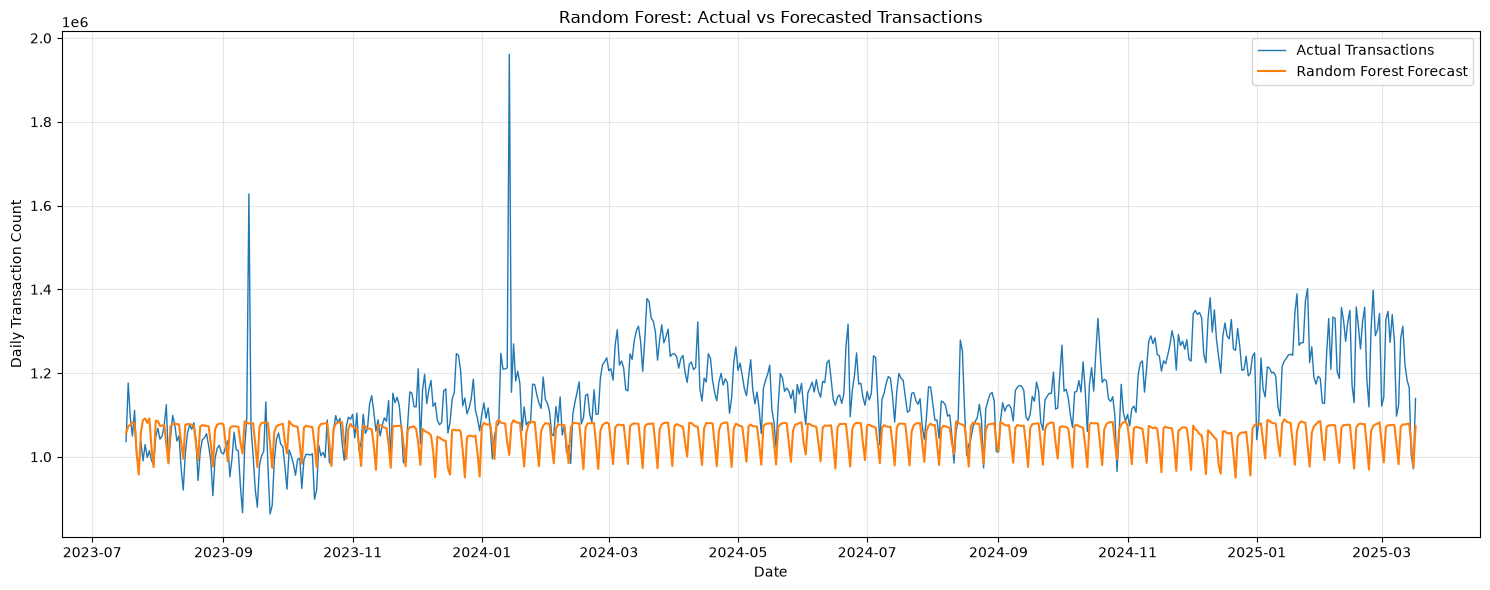

In [58]:
# Visual comparison of actual and Random Forest forecasts

plt.figure(figsize=(15, 6))

plt.plot(
    validation.index,
    validation,
    label="Actual Transactions",
    linewidth=1
)

plt.plot(
    rf_validation_forecast.index,
    rf_validation_forecast,
    label="Random Forest Forecast",
    linewidth=1.5
)

plt.title("Random Forest: Actual vs Forecasted Transactions")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save visualization
plt.savefig(
    visualizations_dir / "20_random_forest_validation_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.6.1.7 Analysis of Random Forest Forecast Behaviour

The visual comparison suggests that the Random Forest model may have difficulty capturing the magnitude and variability of actual Ethereum network activity.

To investigate this behaviour, the distributions and standard deviations of actual and forecast transaction counts are compared.

This analysis helps determine whether the model systematically underestimates fluctuations and produces excessively smooth forecasts.

In [59]:
# Compare actual and forecast distributions

rf_forecast_comparison = pd.DataFrame({
    "Actual": validation,
    "Random Forest Forecast": rf_validation_forecast
})

print("Actual validation statistics:")
display(rf_forecast_comparison["Actual"].describe())

print("\nRandom Forest forecast statistics:")
display(rf_forecast_comparison["Random Forest Forecast"].describe())

print("\nStandard deviation comparison:")

print(
    "Actual:",
    round(validation.std(), 2)
)

print(
    "Random Forest:",
    round(rf_validation_forecast.std(), 2)
)

print(
    "\nForecast-to-actual standard deviation ratio:",
    round(
        rf_validation_forecast.std() / validation.std(),
        4
    )
)

Actual validation statistics:


count    6.100000e+02
mean     1.148524e+06
std      1.076265e+05
min      8.635030e+05
25%      1.081223e+06
50%      1.146051e+06
75%      1.212721e+06
max      1.961144e+06
Name: Actual, dtype: float64


Random Forest forecast statistics:


count    6.100000e+02
mean     1.053973e+06
std      3.523701e+04
min      9.500221e+05
25%      1.032868e+06
50%      1.071825e+06
75%      1.078138e+06
max      1.091807e+06
Name: Random Forest Forecast, dtype: float64


Standard deviation comparison:
Actual: 107626.46
Random Forest: 35237.01

Forecast-to-actual standard deviation ratio: 0.3274


#### 6.6.1.8 Interpretation of Random Forest Forecast Behaviour

Although the Random Forest model achieved the lowest MAE, RMSE, and MAPE among the models evaluated so far, its forecasts exhibited substantially lower variability than the actual validation observations.

The standard deviation of the Random Forest forecasts was approximately 35,237, compared with 107,626 for the actual observations. Thus, the model reproduced only 32.74% of the observed variability.

The model also substantially underestimated the maximum transaction count, indicating limited ability to capture major increases in network activity.

This behaviour is consistent with the smoothing effect of recursive multi-step forecasting combined with the averaging characteristics of Random Forest regression.

Consequently, although Random Forest achieved relatively good overall error metrics, its ability to reproduce the full dynamics of Ethereum network activity remains limited.

### 6.6.2 XGBoost Regression

Extreme Gradient Boosting (XGBoost) is an ensemble learning algorithm based on gradient-boosted decision trees.

Unlike Random Forest, which builds independent trees and combines their predictions, XGBoost constructs trees sequentially. Each new tree attempts to correct errors made by the preceding trees.

This approach can capture nonlinear relationships and complex interactions among predictive features.

In this study, XGBoost will use the same lagged transaction counts, rolling statistics, and calendar-based predictors developed for Random Forest.

The model will be evaluated using the same fixed-origin, recursive multi-step forecasting framework to ensure a fair comparison.

In [60]:
# Check XGBoost availability

try:
    import xgboost as xgb

    print("XGBoost is installed successfully!")
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed in this Python environment.")

XGBoost is not installed in this Python environment.


In [61]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -----------------


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [62]:
# Verify installation
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost installation successful!")

XGBoost version: 3.4.1
XGBoost installation successful!


In [16]:
print("Dataset shape:", df_transactions.shape)

print("\nColumn names:")
print(df_transactions.columns.tolist())

print("\nData types:")
print(df_transactions.dtypes)

print("\nFirst five rows:")
display(df_transactions.head())

print("\nMissing values:")
display(df_transactions.isna().sum())

print("\nDescriptive statistics:")
display(df_transactions.describe(include="all"))

Dataset shape: (4066, 2)

Column names:
['block_date', 'daily_transaction_count']

Data types:
block_date                   str
daily_transaction_count    int64
dtype: object

First five rows:


,block_date,daily_transaction_count
0,2015-10-01,6421
1,2015-10-02,6063
2,2015-10-03,6112
3,2015-10-04,6624
4,2015-10-05,6279



Missing values:


block_date                 0
daily_transaction_count    0
dtype: int64


Descriptive statistics:


,block_date,daily_transaction_count
count,4066,4.066000e+03
unique,4066,NaN
top,2015-10-01,NaN
freq,1,NaN
mean,NaN,9.483504e+05
std,NaN,5.783087e+05
min,NaN,5.830000e+03
25%,NaN,5.796128e+05
50%,NaN,1.052374e+06
75%,NaN,1.219666e+06


#### Reconstructing the Daily Transaction Time Series

Following the kernel restart, the daily transaction time series is reconstructed from the cleaned dataset.

The date column is converted to datetime format, and the daily transaction count is indexed by date. The reconstructed series is then checked for missing observations and chronological continuity.

In [17]:
# Convert dates to datetime format
df_transactions["block_date"] = pd.to_datetime(
    df_transactions["block_date"]
)

# Reconstruct the daily time series
y = (
    df_transactions
    .set_index("block_date")["daily_transaction_count"]
    .sort_index()
    .asfreq("D")
)

# Verify the reconstructed series
print("Time series observations:", len(y))
print("Data type:", y.dtype)
print("Missing values:", y.isna().sum())
print("Start date:", y.index.min())
print("End date:", y.index.max())

print("\nFirst five observations:")
display(y.head())

print("\nDescriptive statistics:")
display(y.describe())

Time series observations: 4066
Data type: int64
Missing values: 0
Start date: 2015-10-01 00:00:00
End date: 2026-11-17 00:00:00

First five observations:


block_date
2015-10-01    6421
2015-10-02    6063
2015-10-03    6112
2015-10-04    6624
2015-10-05    6279
Freq: D, Name: daily_transaction_count, dtype: int64


Descriptive statistics:


count    4.066000e+03
mean     9.483504e+05
std      5.783087e+05
min      5.830000e+03
25%      5.796128e+05
50%      1.052374e+06
75%      1.219666e+06
max      3.627491e+06
Name: daily_transaction_count, dtype: float64

#### Reconstructing the Training, Validation, and Test Sets

The complete daily transaction time series is divided chronologically into three subsets:

- Training set: 70% of observations.
- Validation set: 15% of observations.
- Test set: 15% of observations.

The chronological order is preserved to prevent information leakage. The test set remains untouched during model development and validation.

In [18]:
# Define chronological split points
n = len(y)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Create the three datasets
train = y.iloc[:train_end]
validation = y.iloc[train_end:validation_end]
test = y.iloc[validation_end:]

# Verify the data splits
print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))

print("\nDate ranges:")
print("Training:", train.index.min(), "to", train.index.max())
print("Validation:", validation.index.min(), "to", validation.index.max())
print("Test:", test.index.min(), "to", test.index.max())

print("\nMissing values:")
print("Training:", train.isna().sum())
print("Validation:", validation.isna().sum())
print("Test:", test.isna().sum())

Training observations: 2846
Validation observations: 610
Test observations: 610

Date ranges:
Training: 2015-10-01 00:00:00 to 2023-07-16 00:00:00
Validation: 2023-07-17 00:00:00 to 2025-03-17 00:00:00
Test: 2025-03-18 00:00:00 to 2026-11-17 00:00:00

Missing values:
Training: 0
Validation: 0
Test: 0


#### Reconstructing Features for XGBoost

The XGBoost model uses the same engineered predictors as the Random Forest model to ensure a fair comparison.

These predictors include:

- Lagged transaction counts (1, 7, 14, and 28 days).
- Rolling means (7 and 30 days).
- Rolling standard deviation (7 days).
- Calendar features (day of week, day of month, and month).

Rolling statistics are calculated using only observations preceding the target date to prevent data leakage.

In [19]:
def create_features(series):

    features = pd.DataFrame(index=series.index)

    # Lagged transaction counts
    features["lag_1"] = series.shift(1)
    features["lag_7"] = series.shift(7)
    features["lag_14"] = series.shift(14)
    features["lag_28"] = series.shift(28)

    # Rolling statistics based only on previous observations
    shifted_series = series.shift(1)

    features["rolling_mean_7"] = (
        shifted_series.rolling(window=7).mean()
    )

    features["rolling_mean_30"] = (
        shifted_series.rolling(window=30).mean()
    )

    features["rolling_std_7"] = (
        shifted_series.rolling(window=7).std()
    )

    # Calendar features
    features["day_of_week"] = series.index.day_of_week
    features["day_of_month"] = series.index.day
    features["month"] = series.index.month

    # Target variable
    features["target"] = series

    # Remove rows with missing feature values
    features = features.dropna()

    return features


# Generate training features
train_features = create_features(train)

X_train = train_features.drop(columns=["target"])
y_train = train_features["target"]

# Verify the reconstructed features
print("Training feature dataset:", train_features.shape)
print("Predictor matrix:", X_train.shape)
print("Target vector:", y_train.shape)

print("\nMissing values in predictors:", X_train.isna().sum().sum())
print("Missing values in target:", y_train.isna().sum())

print("\nFirst five feature rows:")
display(train_features.head())

Training feature dataset: (2816, 11)
Predictor matrix: (2816, 10)
Target vector: (2816,)

Missing values in predictors: 0
Missing values in target: 0

First five feature rows:


,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_30,rolling_std_7,day_of_week,day_of_month,month,target
block_date,,,,,,,,,,,
2015-10-31,7941.0,6361.0,6567.0,6112.0,6862.285714,6582.933333,868.241271,5,31,10,7557
2015-11-01,7557.0,5830.0,6481.0,6624.0,7033.142857,6620.800000,870.828423,6,1,11,6915
2015-11-02,6915.0,5938.0,6604.0,6279.0,7188.142857,6649.200000,700.985361,0,2,11,6558
2015-11-03,6558.0,6784.0,5897.0,6458.0,7276.714286,6664.066667,536.592867,1,3,11,7399
2015-11-04,7399.0,7346.0,6182.0,7121.0,7364.571429,6689.900000,490.874341,2,4,11,7037


#### 6.6.2.1 Training the XGBoost Model

An XGBoost regression model is configured and trained using the engineered temporal features.

The model uses gradient-boosted decision trees to learn nonlinear relationships between historical transaction activity, rolling statistical measures, and calendar variables.

To maintain comparability with the Random Forest model, the same training observations and predictor variables are used.

The initial model configuration uses 100 boosting rounds, a moderate learning rate, and a restricted tree depth to help control model complexity.

To accommodate the available computational resources and reduce overfitting, the model is configured with a limited number of boosting rounds, shallow trees, and regularization.

The model is trained exclusively on the training dataset. The validation dataset is reserved for subsequent forecasting evaluation.

In [20]:
# Import XGBoost
import xgboost as xgb

# Initialize the XGBoost regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")
print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])
print("Boosting rounds:", xgb_model.n_estimators)

XGBoost model trained successfully!
Training observations: 2816
Number of predictors: 10
Boosting rounds: 100


#### 6.6.2.2 Recursive Multi-Step Validation Forecasting

The trained XGBoost model generates forecasts for the entire validation period (610 days).

A recursive fixed-origin forecasting strategy is used. The model starts with the training observations, and each predicted value is added to the historical series to construct the predictors for the next forecast date.

Actual validation observations are not used to update the forecasting history. This preserves the fixed-origin evaluation framework and prevents information leakage.

In [21]:
# Initialize forecasting history using training observations
xgb_history = train.astype("float64").copy()

xgb_validation_forecast = []

# Generate recursive forecasts
for forecast_date in validation.index:

    feature_row = pd.DataFrame({
        "lag_1": [xgb_history.iloc[-1]],
        "lag_7": [xgb_history.iloc[-7]],
        "lag_14": [xgb_history.iloc[-14]],
        "lag_28": [xgb_history.iloc[-28]],
        "rolling_mean_7": [xgb_history.iloc[-7:].mean()],
        "rolling_mean_30": [xgb_history.iloc[-30:].mean()],
        "rolling_std_7": [xgb_history.iloc[-7:].std()],
        "day_of_week": [forecast_date.day_of_week],
        "day_of_month": [forecast_date.day],
        "month": [forecast_date.month]
    })

    prediction = xgb_model.predict(feature_row)[0]

    xgb_validation_forecast.append(prediction)

    # Append prediction, not actual observation
    xgb_history.loc[forecast_date] = prediction

# Convert forecasts into a time series
xgb_validation_forecast = pd.Series(
    xgb_validation_forecast,
    index=validation.index,
    name="XGBoost Forecast"
)

# Verify forecasts
print("Forecast observations:", len(xgb_validation_forecast))
print("Missing forecasts:", xgb_validation_forecast.isna().sum())

print("\nFirst five forecasts:")
display(xgb_validation_forecast.head())

print("\nLast five forecasts:")
display(xgb_validation_forecast.tail())

Forecast observations: 610
Missing forecasts: 0

First five forecasts:


block_date
2023-07-17    1.029646e+06
2023-07-18    1.039056e+06
2023-07-19    1.021303e+06
2023-07-20    1.040466e+06
2023-07-21    1.071381e+06
Freq: D, Name: XGBoost Forecast, dtype: float32


Last five forecasts:


block_date
2025-03-13    1085862.625
2025-03-14    1084819.000
2025-03-15    1036592.875
2025-03-16    1011227.625
2025-03-17    1084217.625
Freq: D, Name: XGBoost Forecast, dtype: float32

#### 6.6.2.3 Evaluation of XGBoost Forecasting Performance

The XGBoost validation forecasts are evaluated against the actual transaction counts using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

These metrics provide a consistent basis for comparing XGBoost with Random Forest and the previously evaluated statistical and baseline forecasting models.

In [22]:
# Evaluate XGBoost validation forecasts
xgb_validation_results = evaluate_forecast(
    validation,
    xgb_validation_forecast
)

print("XGBoost Validation Results")

for metric, value in xgb_validation_results.items():
    print(f"{metric}: {value:,.4f}")

XGBoost Validation Results
MAE: 100,176.2109
RMSE: 127,874.1702
MAPE (%): 8.3419


#### 6.6.2.4 Visual Comparison of XGBoost Validation Forecasts

The actual daily transaction counts are plotted against the XGBoost validation forecasts.

This visualization helps assess how well the model captures changes in transaction activity, including short-term fluctuations, peaks, and declines.

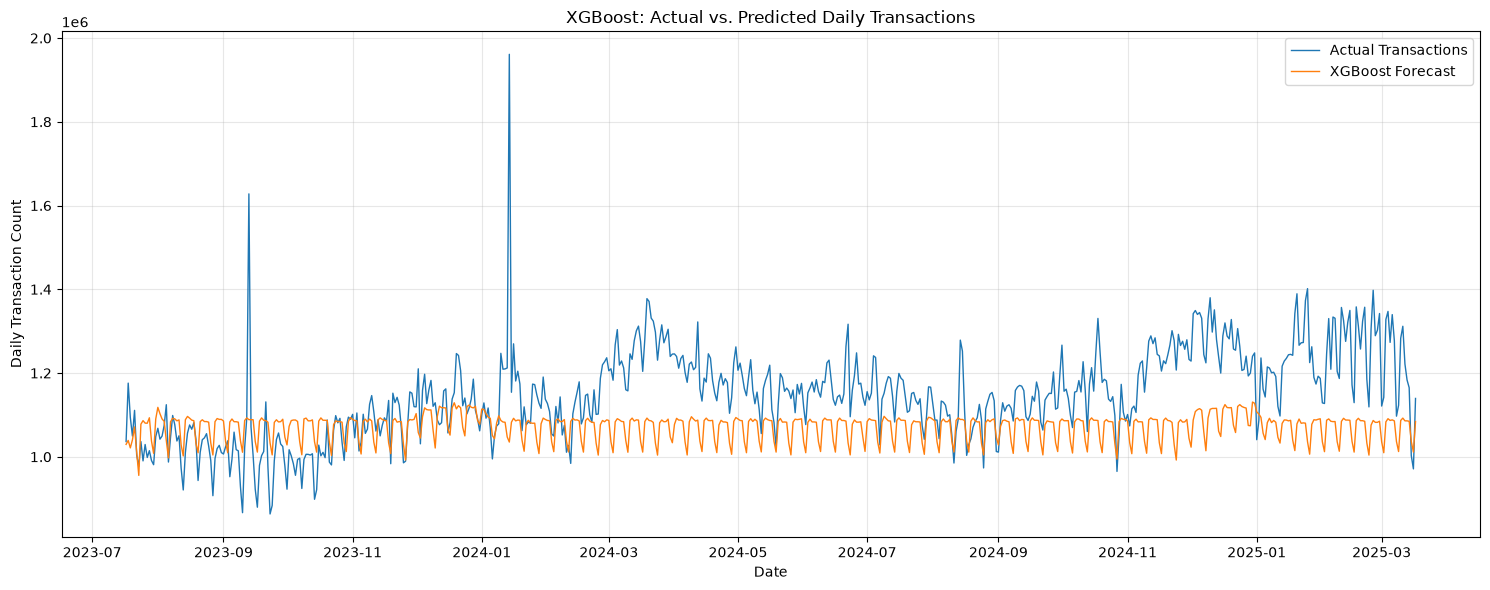

In [25]:
plt.figure(figsize=(15, 6))

plt.plot(
    validation.index,
    validation,
    label="Actual Transactions",
    linewidth=1
)

plt.plot(
    xgb_validation_forecast.index,
    xgb_validation_forecast,
    label="XGBoost Forecast",
    linewidth=1
)

plt.title("XGBoost: Actual vs. Predicted Daily Transactions")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "21_xgboost_validation_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.6.2.5 Statistical Assessment of XGBoost Forecast Behaviour

Although XGBoost achieved the lowest validation errors among the models evaluated so far, visual inspection suggests that its forecasts may not adequately reproduce the variability of actual Ethereum transaction activity.

The descriptive statistics of actual and predicted values are compared to examine differences in their central tendency, dispersion, and range.

In [26]:
# Compare actual and predicted distributions

xgb_comparison = pd.DataFrame({
    "Actual": validation,
    "XGBoost": xgb_validation_forecast
})

display(xgb_comparison.describe())

print("\nStandard deviation comparison:")
print("Actual:", validation.std())
print("XGBoost:", xgb_validation_forecast.std())

print("\nMinimum and maximum:")
print("Actual:", validation.min(), validation.max())
print("XGBoost:", xgb_validation_forecast.min(),
      xgb_validation_forecast.max())

print("\nForecast-to-actual variability ratio:")
print(
    xgb_validation_forecast.std() / validation.std()
)

,Actual,XGBoost
count,6.100000e+02,6.100000e+02
mean,1.148524e+06,1.071416e+06
std,1.076265e+05,3.147784e+04
min,8.635030e+05,9.556076e+05
25%,1.081223e+06,1.043423e+06
50%,1.146051e+06,1.084757e+06
75%,1.212721e+06,1.088604e+06
max,1.961144e+06,1.130784e+06



Standard deviation comparison:
Actual: 107626.46424336733
XGBoost: 31477.842

Minimum and maximum:
Actual: 863503 1961144
XGBoost: 955607.6 1.1307842e+06

Forecast-to-actual variability ratio:
0.29247306429854103


#### 6.6.2.6 Analysis of XGBoost Forecast Bias

Forecast accuracy metrics alone do not reveal whether a model systematically overestimates or underestimates the target variable.

Therefore, forecast errors are examined to assess systematic bias and determine whether XGBoost consistently underestimates daily Ethereum transaction activity.

The mean error is calculated as the average difference between predicted and actual values.

In [27]:
# Calculate forecast errors
xgb_errors = validation - xgb_validation_forecast

# Calculate bias statistics
xgb_mean_error = xgb_errors.mean()
xgb_median_error = xgb_errors.median()

print("XGBoost Forecast Bias Analysis")
print("--------------------------------")
print(f"Mean error: {xgb_mean_error:,.2f}")
print(f"Median error: {xgb_median_error:,.2f}")
print(f"Percentage of positive errors: {(xgb_errors > 0).mean() * 100:.2f}%")
print(f"Percentage of negative errors: {(xgb_errors < 0).mean() * 100:.2f}%")

print("\nForecast error distribution:")
display(xgb_errors.describe())

XGBoost Forecast Bias Analysis
--------------------------------
Mean error: 77,108.46
Median error: 72,865.25
Percentage of positive errors: 76.72%
Percentage of negative errors: 23.28%

Forecast error distribution:


count       610.000000
mean      77108.457172
std      102093.960297
min     -169546.312500
25%        8709.390625
50%       72865.250000
75%      136903.234375
max      925911.062500
dtype: float64

#### 6.6.2.7 Interpretation of XGBoost Forecast Bias

The forecast error analysis reveals a substantial systematic underestimation of daily Ethereum transaction activity.

The mean forecast error is 77,108 transactions, while the median error is 72,865 transactions. Approximately 76.72% of validation observations have positive forecast errors, indicating that actual transaction counts exceed the corresponding predictions on most days.

Furthermore, the forecast standard deviation is considerably lower than that of the actual observations, suggesting that XGBoost produces excessively smooth predictions and fails to reproduce important fluctuations in network activity.

Although XGBoost achieves the lowest MAE, RMSE, and MAPE among the models evaluated so far, its inability to capture substantial increases and extreme observations represents an important limitation.

These findings demonstrate why forecast evaluation should consider error magnitude, systematic bias, and the ability to reproduce temporal variability rather than relying exclusively on aggregate accuracy metrics.

#### 6.6.2.8 Comparison of Actual and Predicted Trends

To further investigate the forecasting limitations of XGBoost, the 30-day rolling averages of actual and predicted transaction counts are compared.

Rolling averages reduce short-term fluctuations and help identify differences in the underlying trends.

This analysis examines whether XGBoost captures the general direction and magnitude of changes in Ethereum network activity during the validation period.

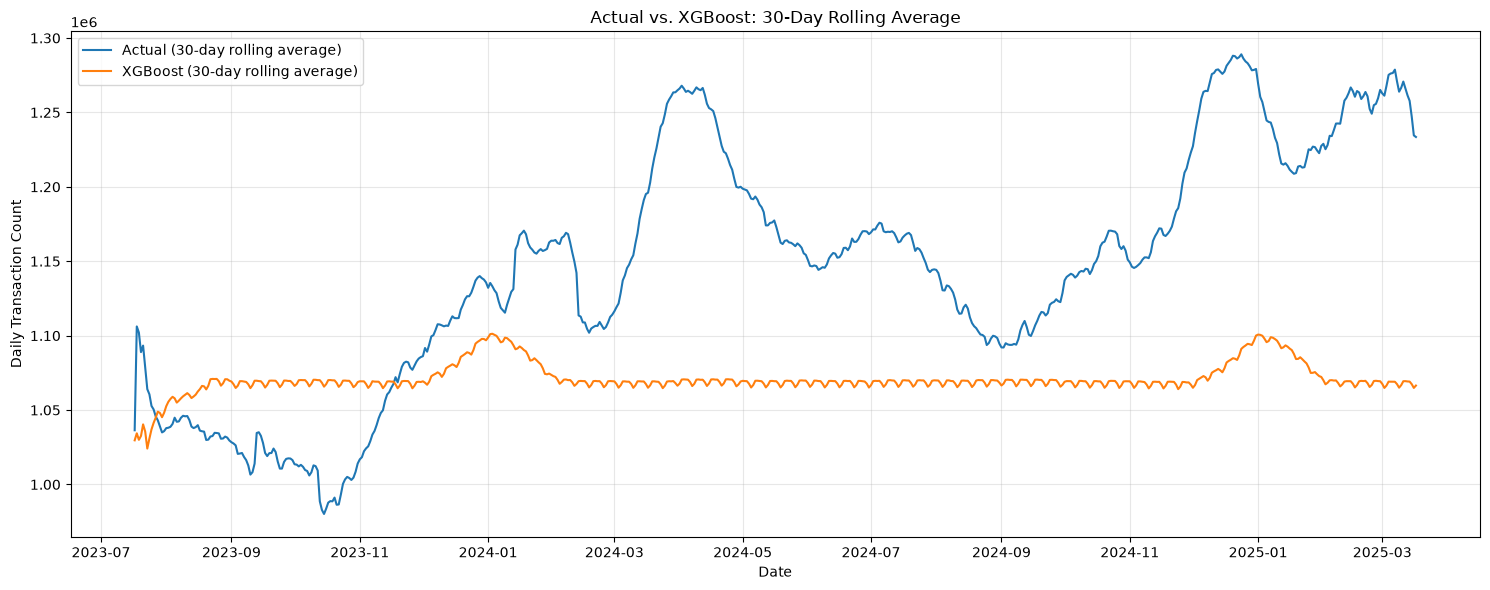

In [28]:
# Calculate 30-day rolling averages
actual_rolling_30 = validation.rolling(
    window=30,
    min_periods=1
).mean()

xgb_rolling_30 = xgb_validation_forecast.rolling(
    window=30,
    min_periods=1
).mean()

# Plot actual and predicted rolling averages
plt.figure(figsize=(15, 6))

plt.plot(
    actual_rolling_30.index,
    actual_rolling_30,
    label="Actual (30-day rolling average)",
    linewidth=1.5
)

plt.plot(
    xgb_rolling_30.index,
    xgb_rolling_30,
    label="XGBoost (30-day rolling average)",
    linewidth=1.5
)

plt.title("Actual vs. XGBoost: 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "22_xgboost_30d_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
# Quantify the trend difference
trend_comparison = pd.DataFrame({
    "Actual_30d_Average": actual_rolling_30,
    "XGBoost_30d_Average": xgb_rolling_30
})

trend_comparison["Difference"] = (
    trend_comparison["Actual_30d_Average"]
    - trend_comparison["XGBoost_30d_Average"]
)

display(trend_comparison.describe())

,Actual_30d_Average,XGBoost_30d_Average,Difference
count,6.100000e+02,6.100000e+02,610.000000
mean,1.145103e+06,1.070832e+06,74271.070342
std,7.942011e+04,1.008236e+04,76899.071173
min,9.801664e+05,1.024131e+06,-85566.814583
25%,1.098602e+06,1.067224e+06,27960.655208
50%,1.150414e+06,1.069355e+06,78784.357292
75%,1.201636e+06,1.070280e+06,127542.278125
max,1.289052e+06,1.101260e+06,209740.200000


### 6.6.3 Rolling-Origin XGBoost Forecasting

The previous XGBoost experiment used a fixed-origin recursive forecasting strategy, generating 610 consecutive predictions without incorporating actual validation observations.

To investigate the effect of forecasting strategy on predictive performance, a rolling-origin one-day-ahead forecasting experiment is conducted.

Under this approach, the model predicts one day ahead using all information available up to the previous day. Once the actual transaction count for that day becomes available, it is incorporated into the historical data used to generate the next forecast.

The experiment uses the original training period for initial model development and the validation period for sequential forecasting evaluation.

This approach evaluates the model's ability to predict daily Ethereum network activity when recent observations are available.

In [30]:
# Initialize historical observations
xgb_rolling_history = train.astype("float64").copy()

xgb_rolling_forecast = []

# One-day-ahead rolling-origin forecasting
for forecast_date in validation.index:

    feature_row = pd.DataFrame({
        "lag_1": [xgb_rolling_history.iloc[-1]],
        "lag_7": [xgb_rolling_history.iloc[-7]],
        "lag_14": [xgb_rolling_history.iloc[-14]],
        "lag_28": [xgb_rolling_history.iloc[-28]],
        "rolling_mean_7": [
            xgb_rolling_history.iloc[-7:].mean()
        ],
        "rolling_mean_30": [
            xgb_rolling_history.iloc[-30:].mean()
        ],
        "rolling_std_7": [
            xgb_rolling_history.iloc[-7:].std()
        ],
        "day_of_week": [forecast_date.day_of_week],
        "day_of_month": [forecast_date.day],
        "month": [forecast_date.month]
    })

    # Predict the next day
    prediction = xgb_model.predict(feature_row)[0]

    xgb_rolling_forecast.append(prediction)

    # Incorporate the actual observation after prediction
    xgb_rolling_history.loc[forecast_date] = validation.loc[forecast_date]

# Convert forecasts into a time series
xgb_rolling_forecast = pd.Series(
    xgb_rolling_forecast,
    index=validation.index,
    name="XGBoost Rolling-Origin Forecast"
)

# Verify the forecasts
print("Forecast observations:", len(xgb_rolling_forecast))
print("Missing forecasts:", xgb_rolling_forecast.isna().sum())

print("\nFirst five forecasts:")
display(xgb_rolling_forecast.head())

print("\nLast five forecasts:")
display(xgb_rolling_forecast.tail())

Forecast observations: 610
Missing forecasts: 0

First five forecasts:


block_date
2023-07-17    1.029646e+06
2023-07-18    1.043361e+06
2023-07-19    1.093729e+06
2023-07-20    1.081072e+06
2023-07-21    1.075360e+06
Freq: D, Name: XGBoost Rolling-Origin Forecast, dtype: float32


Last five forecasts:


block_date
2025-03-13    1.211239e+06
2025-03-14    1.188580e+06
2025-03-15    1.122724e+06
2025-03-16    1.012743e+06
2025-03-17    1.082992e+06
Freq: D, Name: XGBoost Rolling-Origin Forecast, dtype: float32

#### 6.6.3.1 Evaluation of Rolling-Origin XGBoost Forecasts

The rolling-origin XGBoost forecasts are evaluated against the actual validation observations using MAE, RMSE, and MAPE.

The results are compared with the original fixed-origin XGBoost experiment to assess the effect of incorporating newly observed transaction counts into the forecasting process.

In [31]:
# Evaluate rolling-origin forecasts
xgb_rolling_results = evaluate_forecast(
    validation,
    xgb_rolling_forecast
)

# Compare fixed-origin and rolling-origin results
xgb_strategy_comparison = pd.DataFrame(
    [
        xgb_validation_results,
        xgb_rolling_results
    ],
    index=[
        "Fixed-Origin XGBoost",
        "Rolling-Origin XGBoost"
    ]
)

display(xgb_strategy_comparison)

,MAE,RMSE,MAPE (%)
Fixed-Origin XGBoost,100176.210938,127874.170152,8.341895
Rolling-Origin XGBoost,40767.351562,64079.550560,3.528845


#### 6.6.3.2 Interpretation of Rolling-Origin XGBoost Performance

The rolling-origin XGBoost experiment substantially outperformed the original fixed-origin forecasting strategy.

MAE decreased from 100,176 to 40,767 transactions, representing an improvement of approximately 59.30%. RMSE decreased by 49.89%, while MAPE declined from 8.34% to 3.53%.

This improvement indicates that incorporating newly observed transaction counts into the historical input data enables the model to adapt more effectively to changes in network activity.

In contrast, the fixed-origin recursive approach experienced considerable forecast smoothing and systematic underestimation over the extended forecasting horizon.

These findings demonstrate the importance of forecasting strategy in evaluating machine learning models for time-series prediction.

However, the two strategies represent different operational forecasting scenarios. The rolling-origin experiment evaluates sequential one-day-ahead predictions with newly available actual observations, whereas the fixed-origin experiment evaluates a single 610-day forecasting horizon without actual updates.

Therefore, their performance metrics should be interpreted separately rather than as directly equivalent forecasting tasks.

In [32]:
print("Actual standard deviation:", validation.std())

print(
    "Rolling-origin forecast standard deviation:",
    xgb_rolling_forecast.std()
)

print(
    "Forecast-to-actual variability ratio:",
    xgb_rolling_forecast.std() / validation.std()
)

print(
    "\nForecast bias:",
    (validation - xgb_rolling_forecast).mean()
)

Actual standard deviation: 107626.46424336733
Rolling-origin forecast standard deviation: 83639.49
Forecast-to-actual variability ratio: 0.7771275659337145

Forecast bias: -15.973463114754098


#### 6.6.3.3 Analysis of Forecast Variability and Bias

In addition to conventional forecasting accuracy metrics, the variability and systematic bias of the rolling-origin XGBoost predictions were examined.

The standard deviation of actual validation observations was approximately 107,626 transactions, compared with 83,639 transactions for the rolling-origin forecasts.

The forecast-to-actual standard deviation ratio was 0.7771, indicating that the model reproduced approximately 77.71% of the observed variability in daily Ethereum transaction activity.

This represents a substantial improvement over the fixed-origin XGBoost experiment, which reproduced only approximately 29.25% of actual variability.

The mean forecast bias, calculated as the difference between actual and predicted transaction counts, was approximately -15.97 transactions. This value is negligible relative to the scale of daily network activity and indicates almost no systematic bias across the validation period.

Overall, the results suggest that rolling-origin forecasting enables XGBoost to capture changes in transaction activity more effectively than the fixed-origin recursive approach.

Nevertheless, the remaining difference in standard deviations indicates that some fluctuations are still not fully captured by the model.

#### 6.6.3.4 Visual Comparison of Rolling-Origin XGBoost Forecasts

The actual validation observations and rolling-origin XGBoost predictions are plotted together to examine the model's ability to track daily changes in Ethereum transaction activity.

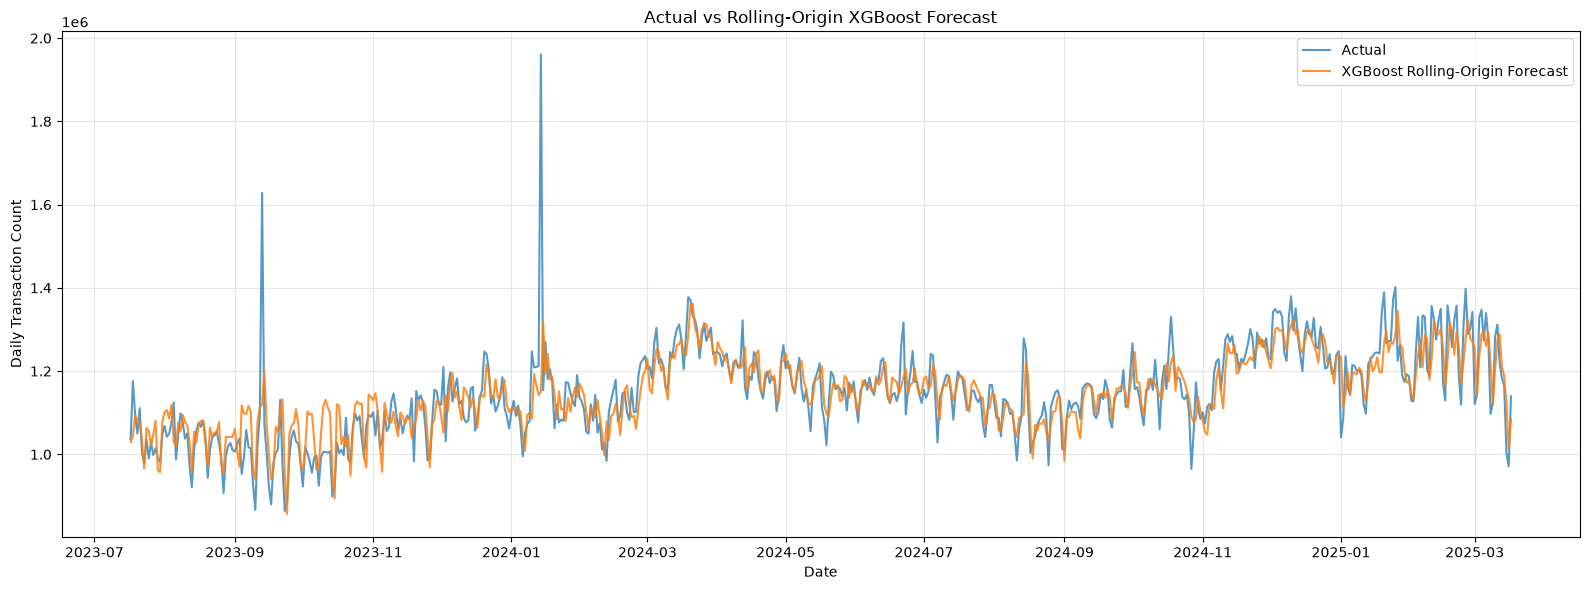

In [33]:
plt.figure(figsize=(16, 6))

plt.plot(
    validation.index,
    validation,
    label="Actual",
    alpha=0.75
)

plt.plot(
    xgb_rolling_forecast.index,
    xgb_rolling_forecast,
    label="XGBoost Rolling-Origin Forecast",
    alpha=0.85
)

plt.title("Actual vs Rolling-Origin XGBoost Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "23_xgboost_rolling_origin_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.6.3.5 Interpretation of Rolling-Origin Forecast Visualization

The visual comparison demonstrates that rolling-origin XGBoost provides a strong representation of actual daily Ethereum transaction activity throughout the validation period.

The predicted values closely follow the observed series, capturing much of its temporal variation, including increases and decreases in network activity.

However, the model does not fully capture two prominent peaks in the actual transaction counts, indicating that unusually large increases in network activity remain challenging to predict.

Overall, the visual evidence is consistent with the quantitative evaluation results (MAE = 40,767; RMSE = 64,080; MAPE = 3.53%) and the relatively high forecast-to-actual variability ratio (77.71%).

These findings indicate that rolling-origin XGBoost is a promising approach for short-term, one-day-ahead forecasting of Ethereum network activity.

#### 6.6.3.6 Investigation of Underestimated Peaks

An error analysis is conducted to identify the largest discrepancies between actual transaction counts and rolling-origin XGBoost predictions.

The analysis focuses on observations with the largest positive forecast errors, where actual transaction counts substantially exceeded predicted values.

The dates and magnitudes of these errors are examined to identify potential patterns associated with unusually high network activity.

In [34]:
# Create a forecast error analysis table
peak_error_analysis = pd.DataFrame({
    "Actual": validation,
    "Predicted": xgb_rolling_forecast
})

peak_error_analysis["Forecast_Error"] = (
    peak_error_analysis["Actual"] -
    peak_error_analysis["Predicted"]
)

peak_error_analysis["Absolute_Error"] = (
    peak_error_analysis["Forecast_Error"].abs()
)

# Identify the 10 largest underpredicted observations
largest_underpredictions = (
    peak_error_analysis
    .sort_values("Forecast_Error", ascending=False)
    .head(10)
)

display(largest_underpredictions.round(0))

,Actual,Predicted,Forecast_Error,Absolute_Error
block_date,,,,
2024-01-14,1961144,1150857.0,810287.0,810287.0
2023-09-13,1627860,1118991.0,508869.0,508869.0
2024-08-14,1278666,1095579.0,183087.0,183087.0
2024-01-10,1247106,1085461.0,161645.0,161645.0
2023-12-02,1210135,1052143.0,157992.0,157992.0
2025-01-19,1342035,1196381.0,145654.0,145654.0
2025-02-17,1358017,1223304.0,134713.0,134713.0
2023-07-18,1175963,1043361.0,132602.0,132602.0
2024-06-22,1316624,1186693.0,129931.0,129931.0


#### 6.6.3.7 Examination of Transaction Activity Around Major Peaks

The daily actual transaction counts and rolling-origin XGBoost predictions are examined over a 15-day window surrounding each of the two largest underpredicted observations.

This analysis investigates whether the unusually high transaction counts were preceded by detectable increases in network activity or represented abrupt changes that were difficult for the model to anticipate.

In [35]:
# Dates of the two largest underestimated peaks
peak_dates = [
    pd.Timestamp("2024-01-14"),
    pd.Timestamp("2023-09-13")
]

for peak_date in peak_dates:

    start_date = peak_date - pd.Timedelta(days=7)
    end_date = peak_date + pd.Timedelta(days=7)

    diagnostic_window = pd.DataFrame({
        "Actual": validation.loc[start_date:end_date],
        "Predicted": xgb_rolling_forecast.loc[start_date:end_date]
    })

    diagnostic_window["Forecast_Error"] = (
        diagnostic_window["Actual"] -
        diagnostic_window["Predicted"]
    )

    print(f"\nPeak date: {peak_date.date()}")
    display(diagnostic_window.round(0))


Peak date: 2024-01-14


,Actual,Predicted,Forecast_Error
block_date,,,
2024-01-07,1049831,1008273.0,41558.0
2024-01-08,1073535,1094277.0,-20742.0
2024-01-09,1078832,1099036.0,-20204.0
2024-01-10,1247106,1085461.0,161645.0
2024-01-11,1209246,1193554.0,15692.0
2024-01-12,1209875,1165603.0,44272.0
2024-01-13,1212202,1142129.0,70073.0
2024-01-14,1961144,1150857.0,810287.0
2024-01-15,1154132,1316422.0,-162290.0



Peak date: 2023-09-13


,Actual,Predicted,Forecast_Error
block_date,,,
2023-09-06,1058940,1097507.0,-38567.0
2023-09-07,1017089,1116697.0,-99608.0
2023-09-08,1014297,1101512.0,-87215.0
2023-09-09,929400,961857.0,-32457.0
2023-09-10,866548,939167.0,-72619.0
2023-09-11,1021616,1080312.0,-58696.0
2023-09-12,1092958,1113416.0,-20458.0
2023-09-13,1627860,1118991.0,508869.0
2023-09-14,1071590,1199862.0,-128272.0


#### 6.6.3.8 Interpretation of Major Underestimated Peaks

The examination of the two largest forecasting errors revealed that both occurred during abrupt and short-lived increases in daily Ethereum transaction activity.

On 14 January 2024, the actual transaction count reached 1,961,144, whereas the model predicted 1,150,857. The resulting underestimation was 810,287 transactions.

Similarly, on 13 September 2023, actual activity increased to 1,627,860 transactions, compared with a prediction of 1,118,991, resulting in an underestimation of 508,869 transactions.

In both cases, transaction activity returned towards its preceding range on the following day.

These observations suggest that the largest forecasting errors were associated with exceptional, short-lived activity spikes rather than persistent changes in the underlying activity level.

The lagged and rolling features used by XGBoost provided useful information about recent network behaviour but could not anticipate these sudden increases.

Further investigation is required to establish whether these observations correspond to identifiable network events or unusual transaction activity.

#### 6.6.3.9 Historical Context of Major Transaction Activity Spikes

Further investigation of the two largest forecasting errors identified historical Ethereum network events corresponding to both exceptional transaction-count observations.

**14 January 2024 – Inscription Activity**

The Ethereum network recorded 1,961,144 transactions on this date. Historical reporting by The Block identified a substantial increase in inscription activity as the main driver of this record. More than one million inscriptions were recorded, with over $2.5 million spent on inscription activity.

The unusually high transaction count was therefore associated with a temporary surge in inscription-related network activity.

**13 September 2023 – Binance Wallet Activity**

The Ethereum network recorded 1,627,860 transactions on this date. Historical analysis by Artemis identified an exceptional increase in active wallet activity, reaching approximately one million active wallets compared with a six-month daily average of approximately 395,000.

The increase was primarily associated with wallet-to-wallet transfers, much of which involved a Binance hot wallet. Separate reporting indicated that this wallet processed approximately 710,000 transactions within 24 hours.

**Implications for Forecasting**

Both observations corresponded to unusual network activity driven by identifiable blockchain events.

These events help explain why the rolling-origin XGBoost model substantially underestimated the two peaks despite achieving strong overall validation performance.

The findings also demonstrate an important limitation of forecasting models based exclusively on historical transaction counts, lagged observations, rolling statistics, and calendar features: they may not anticipate sudden changes caused by external events or exceptional on-chain activity.

The observations are retained in the dataset because they represent genuine network activity rather than established data errors.

**Sources**

1. The Block (22 January 2024), Data & Insights Recap:
   https://www.theblock.co/newsletters/data-and-insights/2024-01-22-data-insights-recap-january-22-2023-273806

2. Artemis (15 September 2023), Artemis Weekly Wrap-up:
   https://research.artemis.ai/p/artemis-weekly-wrap-up-9152023

3. The Crypto Times (15 September 2023), Binance's ETH Wallet Records Over 700k Daily Transactions:
   https://www.cryptotimes.io/2023/09/15/binances-eth-wallet-records-over-700k-daily-transactions/

### 6.6.4 Rolling-Origin Random Forest Forecasting

To compare Random Forest and XGBoost under the same forecasting conditions, a rolling-origin one-day-ahead forecasting experiment is conducted using the previously trained Random Forest model.

At each forecasting step, the model predicts the next day's transaction count using the most recently available historical observations.

After each prediction, the actual transaction count for that date is incorporated into the historical data used to generate the subsequent forecast.

The Random Forest model remains fixed throughout the validation period; its parameters are not retrained.

This experiment allows a direct comparison of the two machine learning algorithms under the same rolling-origin forecasting strategy.

#### 6.6.4.1 Training the Random Forest Model

The Random Forest model is reconstructed using the training features and target variable previously developed.

The model uses 100 decision trees, a maximum tree depth of 12, and a minimum of two observations per leaf.

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])

Random Forest model trained successfully.
Training observations: 2816
Number of predictors: 10


In [38]:
# Initialize historical data using the training observations
rf_rolling_history = train.astype("float64").copy()

rf_rolling_forecast = []

# Generate one-day-ahead forecasts
for forecast_date in validation.index:

    feature_row = pd.DataFrame({
        "lag_1": [rf_rolling_history.iloc[-1]],
        "lag_7": [rf_rolling_history.iloc[-7]],
        "lag_14": [rf_rolling_history.iloc[-14]],
        "lag_28": [rf_rolling_history.iloc[-28]],

        "rolling_mean_7": [
            rf_rolling_history.iloc[-7:].mean()
        ],

        "rolling_mean_30": [
            rf_rolling_history.iloc[-30:].mean()
        ],

        "rolling_std_7": [
            rf_rolling_history.iloc[-7:].std()
        ],

        "day_of_week": [forecast_date.day_of_week],
        "day_of_month": [forecast_date.day],
        "month": [forecast_date.month]
    })

    # Predict the next day's transaction count
    prediction = rf_model.predict(feature_row)[0]

    rf_rolling_forecast.append(prediction)

    # Incorporate the actual observation for the next forecast
    rf_rolling_history.loc[forecast_date] = validation.loc[forecast_date]


# Convert forecasts into a time-indexed Series
rf_rolling_forecast = pd.Series(
    rf_rolling_forecast,
    index=validation.index,
    name="Random Forest Rolling-Origin Forecast"
)

print("Number of forecasts:", len(rf_rolling_forecast))
print("Missing forecasts:", rf_rolling_forecast.isna().sum())

display(rf_rolling_forecast.head())
display(rf_rolling_forecast.tail())

Number of forecasts: 610
Missing forecasts: 0


block_date
2023-07-17    1.055734e+06
2023-07-18    1.066332e+06
2023-07-19    1.139300e+06
2023-07-20    1.090750e+06
2023-07-21    1.073200e+06
Freq: D, Name: Random Forest Rolling-Origin Forecast, dtype: float64

block_date
2025-03-13    1.223346e+06
2025-03-14    1.197247e+06
2025-03-15    1.135591e+06
2025-03-16    1.034672e+06
2025-03-17    1.089190e+06
Freq: D, Name: Random Forest Rolling-Origin Forecast, dtype: float64

#### 6.6.4.2 Evaluation of Rolling-Origin Random Forest Forecasts

The rolling-origin Random Forest predictions are evaluated against actual validation observations using MAE, RMSE, and MAPE.

The results are subsequently compared with rolling-origin XGBoost to assess the relative predictive performance of the two machine learning algorithms under identical forecasting conditions.

In [39]:
# Evaluate rolling-origin Random Forest forecasts
rf_rolling_results = evaluate_forecast(
    validation,
    rf_rolling_forecast
)

# Compare rolling-origin Random Forest and XGBoost
rolling_origin_comparison = pd.DataFrame(
    [
        rf_rolling_results,
        xgb_rolling_results
    ],
    index=[
        "Rolling-Origin Random Forest",
        "Rolling-Origin XGBoost"
    ]
)

display(rolling_origin_comparison.round(4))

,MAE,RMSE,MAPE (%)
Rolling-Origin Random Forest,41072.5895,65454.1490,3.5500
Rolling-Origin XGBoost,40767.3516,64079.5506,3.5288


#### 6.6.4.3 Comparative Evaluation of Rolling-Origin Random Forest and XGBoost

The rolling-origin evaluation results indicate that Random Forest and XGBoost achieve very similar forecasting accuracy.

Random Forest achieved an MAE of 41,072.59, an RMSE of 65,454.15, and a MAPE of 3.55%.

XGBoost achieved slightly lower errors, with an MAE of 40,767.35, an RMSE of 64,079.55, and a MAPE of 3.53%.

Relative to Random Forest, XGBoost reduced MAE by approximately 0.74%, RMSE by 2.10%, and MAPE by 0.60%.

Although XGBoost achieved the best results across all three metrics, the differences were relatively small.

These findings suggest that both tree-based ensemble algorithms are effective for rolling-origin one-day-ahead forecasting of Ethereum transaction activity.

The results also indicate that the forecasting strategy has a substantial influence on predictive performance, while the choice between these two algorithms has a comparatively smaller effect in this experiment.

#### 6.6.4.4 Visual Comparison of Rolling-Origin Machine Learning Forecasts

The actual validation observations are plotted alongside rolling-origin Random Forest and XGBoost predictions.

This comparison examines how closely the two algorithms follow daily changes in Ethereum transaction activity, including fluctuations, peaks, and declines.

The visualization provides a complementary assessment of forecasting performance beyond the numerical evaluation metrics.

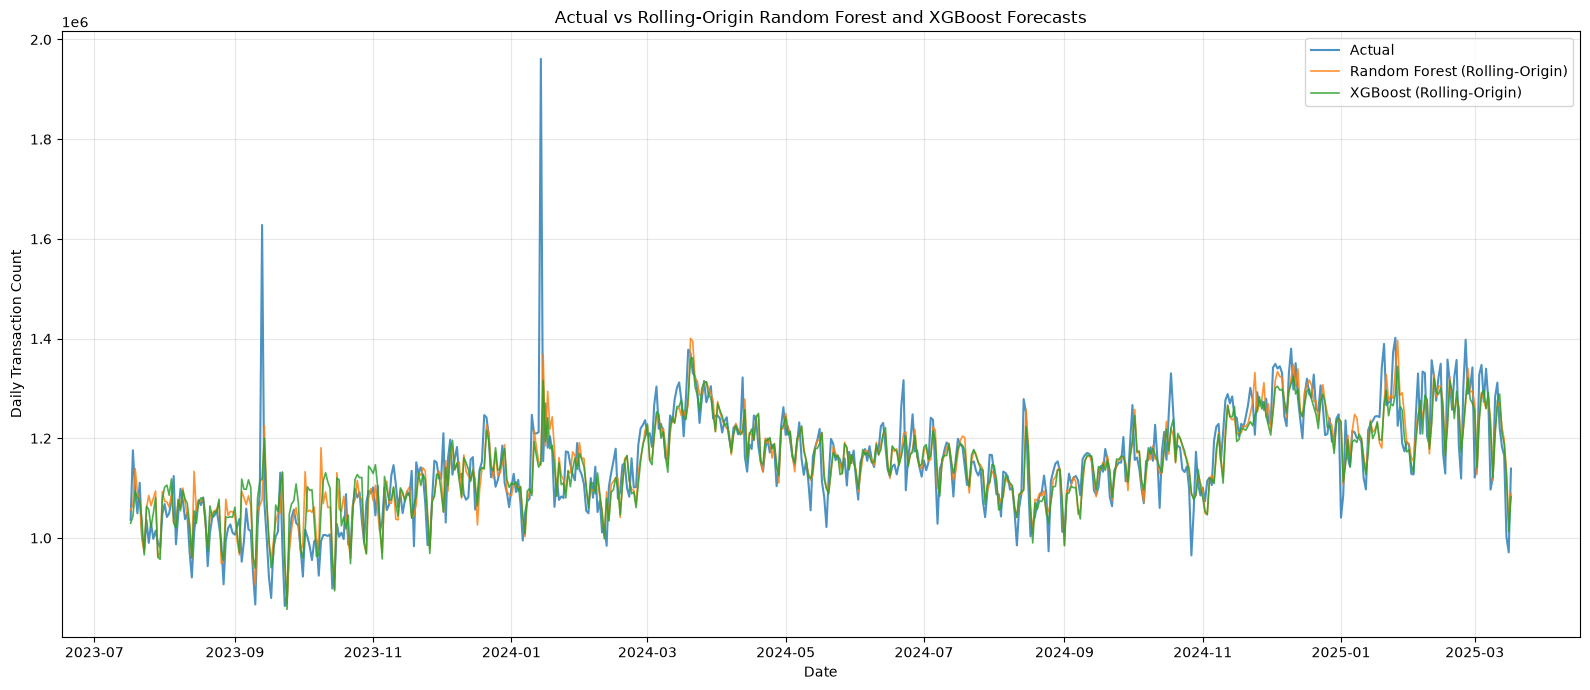

In [40]:
plt.figure(figsize=(16, 7))

plt.plot(
    validation.index,
    validation,
    label="Actual",
    linewidth=1.5,
    alpha=0.8
)

plt.plot(
    rf_rolling_forecast.index,
    rf_rolling_forecast,
    label="Random Forest (Rolling-Origin)",
    linewidth=1.2,
    alpha=0.85
)

plt.plot(
    xgb_rolling_forecast.index,
    xgb_rolling_forecast,
    label="XGBoost (Rolling-Origin)",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Actual vs Rolling-Origin Random Forest and XGBoost Forecasts")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "24_rolling_origin_rf_xgb_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.6.4.5 Interpretation of Rolling-Origin Forecast Comparison

The visual comparison shows that rolling-origin Random Forest and XGBoost predictions closely follow the actual daily Ethereum transaction activity throughout the validation period.

Both models capture much of the underlying variation and short-term fluctuations in network activity. Their predicted values are also highly similar, with the two forecast lines frequently overlapping.

However, both algorithms substantially underestimate the two exceptional transaction-count peaks observed on 13 September 2023 and 14 January 2024.

The visual findings are consistent with the evaluation metrics. XGBoost achieves slightly lower MAE, RMSE, and MAPE than Random Forest, although the differences are relatively small.

Overall, both algorithms demonstrate strong performance under the rolling-origin one-day-ahead forecasting strategy.

In [41]:
# Compare absolute daily forecast errors
daily_model_comparison = pd.DataFrame({
    "Actual": validation,
    "RF_Predicted": rf_rolling_forecast,
    "XGB_Predicted": xgb_rolling_forecast
})

daily_model_comparison["RF_Absolute_Error"] = (
    daily_model_comparison["Actual"] -
    daily_model_comparison["RF_Predicted"]
).abs()

daily_model_comparison["XGB_Absolute_Error"] = (
    daily_model_comparison["Actual"] -
    daily_model_comparison["XGB_Predicted"]
).abs()

# Count daily wins
rf_wins = (
    daily_model_comparison["RF_Absolute_Error"] <
    daily_model_comparison["XGB_Absolute_Error"]
).sum()

xgb_wins = (
    daily_model_comparison["XGB_Absolute_Error"] <
    daily_model_comparison["RF_Absolute_Error"]
).sum()

ties = (
    daily_model_comparison["RF_Absolute_Error"] ==
    daily_model_comparison["XGB_Absolute_Error"]
).sum()

print("Random Forest daily wins:", rf_wins)
print("XGBoost daily wins:", xgb_wins)
print("Ties:", ties)

print(
    "\nCorrelation between predictions:",
    rf_rolling_forecast.corr(xgb_rolling_forecast)
)

Random Forest daily wins: 306
XGBoost daily wins: 304
Ties: 0

Correlation between predictions: 0.9744326088123412


#### 6.6.4.6 Analysis of Daily Forecasting Performance

A day-by-day comparison of absolute forecasting errors revealed very similar performance between rolling-origin Random Forest and XGBoost.

Random Forest produced lower absolute errors on 306 validation days, whereas XGBoost performed better on 304 days. No ties occurred.

The correlation between the two sets of predictions was approximately 0.9744, indicating a strong similarity in their predicted transaction activity patterns.

Interestingly, despite Random Forest achieving slightly more daily wins, XGBoost obtained marginally better aggregate MAE, RMSE, and MAPE values.

This suggests that XGBoost's overall advantage is associated with the magnitude of its forecasting errors rather than consistently outperforming Random Forest across individual days.

Overall, the two algorithms demonstrate comparable predictive performance under the rolling-origin one-day-ahead forecasting strategy.

In [42]:
# Difference in daily absolute errors
daily_model_comparison["Error_Difference"] = (
    daily_model_comparison["RF_Absolute_Error"] -
    daily_model_comparison["XGB_Absolute_Error"]
)

print("Mean error difference:")
print(daily_model_comparison["Error_Difference"].mean())

print("\nMedian error difference:")
print(daily_model_comparison["Error_Difference"].median())

print("\nDescriptive statistics:")
display(
    daily_model_comparison["Error_Difference"].describe().round(2)
)

Mean error difference:
305.23894694077853

Median error difference:
-41.376189639559016

Descriptive statistics:


count       610.00
mean        305.24
std       18283.54
min      -58431.98
25%       -8608.90
50%         -41.38
75%        7950.95
max      127806.21
Name: Error_Difference, dtype: float64

#### 6.6.4.7 Analysis of Differences in Daily Absolute Errors

The differences between daily absolute forecasting errors were examined to further assess the relative performance of rolling-origin Random Forest and XGBoost.

The mean error difference (Random Forest absolute error minus XGBoost absolute error) was approximately 305.24 transactions, indicating a marginal overall advantage for XGBoost.

However, the median difference was -41.38 transactions, suggesting a very small advantage for Random Forest on the typical validation day.

The standard deviation of the daily error differences was approximately 18,283.54 transactions, indicating substantial variation in the relative performance of the two algorithms across individual days.

These findings demonstrate that the small aggregate advantage achieved by XGBoost does not reflect consistent superiority across the validation period.

Overall, rolling-origin Random Forest and XGBoost exhibit highly comparable predictive performance, with XGBoost achieving a marginal advantage in aggregate evaluation metrics.

### 6.7 Neural Network Forecasting Models

Neural networks are computational models capable of learning complex nonlinear relationships from data.

Unlike traditional statistical models and tree-based ensemble algorithms, neural networks use interconnected processing units arranged in layers to learn representations of input features.

This study investigates whether neural network architectures can improve the forecasting of daily Ethereum transaction activity.

The neural network experiments begin with a Multilayer Perceptron (MLP), followed by an investigation of more advanced architectures where computational resources permit.

The models will initially use the same lagged transaction counts, rolling statistics, and calendar-based predictors developed for the machine learning experiments.

Forecasting performance will be evaluated using the established rolling-origin one-day-ahead strategy.

### 6.7.1 Multilayer Perceptron (MLP)

A Multilayer Perceptron (MLP) is a feedforward artificial neural network consisting of an input layer, one or more hidden layers, and an output layer.

The network learns nonlinear relationships between input features and the target variable through a process known as backpropagation.

In this study, the MLP uses the same 10 predictive features developed for Random Forest and XGBoost.

Feature scaling is applied because neural networks are sensitive to differences in the numerical scales of their input variables. The target variable is also standardized during model training and transformed back to its original scale when predictions are generated.

A relatively small network architecture is selected to accommodate the computational limitations of the available hardware.

In [43]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

# Define the MLP architecture
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("mlp", MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=64,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=False,
        random_state=42
    ))
])

# Standardize the target variable during training
mlp_model = TransformedTargetRegressor(
    regressor=mlp_pipeline,
    transformer=StandardScaler()
)

# Train the MLP
mlp_model.fit(X_train, y_train)

print("MLP model trained successfully.")
print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])
print("Hidden layer architecture: 32 → 16")
print(
    "Training iterations:",
    mlp_model.regressor_.named_steps["mlp"].n_iter_
)

MLP model trained successfully.
Training observations: 2816
Number of predictors: 10
Hidden layer architecture: 32 → 16
Training iterations: 45


#### 6.7.1.1 Rolling-Origin MLP Forecasting

The trained MLP model is evaluated using a rolling-origin one-day-ahead forecasting strategy.

At each forecasting step, the model predicts the next day's transaction count using the most recently available historical observations.

After each prediction, the actual transaction count for that date is incorporated into the historical data used to generate the next forecast.

The trained MLP model remains fixed throughout the validation period, without daily retraining.

Predictions are transformed back to the original transaction-count scale before evaluation.

In [44]:
# Initialize historical data
mlp_rolling_history = train.astype("float64").copy()

mlp_rolling_forecast = []

# Generate rolling-origin forecasts
for forecast_date in validation.index:

    feature_row = pd.DataFrame({
        "lag_1": [mlp_rolling_history.iloc[-1]],
        "lag_7": [mlp_rolling_history.iloc[-7]],
        "lag_14": [mlp_rolling_history.iloc[-14]],
        "lag_28": [mlp_rolling_history.iloc[-28]],

        "rolling_mean_7": [
            mlp_rolling_history.iloc[-7:].mean()
        ],

        "rolling_mean_30": [
            mlp_rolling_history.iloc[-30:].mean()
        ],

        "rolling_std_7": [
            mlp_rolling_history.iloc[-7:].std()
        ],

        "day_of_week": [forecast_date.day_of_week],
        "day_of_month": [forecast_date.day],
        "month": [forecast_date.month]
    })

    # Generate prediction
    prediction = mlp_model.predict(feature_row)[0]

    mlp_rolling_forecast.append(prediction)

    # Incorporate actual observation
    mlp_rolling_history.loc[forecast_date] = (
        validation.loc[forecast_date]
    )

# Convert predictions to a Series
mlp_rolling_forecast = pd.Series(
    mlp_rolling_forecast,
    index=validation.index,
    name="MLP Rolling-Origin Forecast"
)

print("Number of forecasts:", len(mlp_rolling_forecast))
print("Missing forecasts:", mlp_rolling_forecast.isna().sum())

print("\nFirst five predictions:")
display(mlp_rolling_forecast.head())

print("\nLast five predictions:")
display(mlp_rolling_forecast.tail())

Number of forecasts: 610
Missing forecasts: 0

First five predictions:


block_date
2023-07-17    1.026806e+06
2023-07-18    1.048917e+06
2023-07-19    1.109252e+06
2023-07-20    1.102307e+06
2023-07-21    1.052177e+06
Freq: D, Name: MLP Rolling-Origin Forecast, dtype: float64


Last five predictions:


block_date
2025-03-13    1.201402e+06
2025-03-14    1.159361e+06
2025-03-15    1.128816e+06
2025-03-16    1.002299e+06
2025-03-17    1.007442e+06
Freq: D, Name: MLP Rolling-Origin Forecast, dtype: float64

#### 6.7.1.2 Evaluation of Rolling-Origin MLP Forecasts

The rolling-origin MLP predictions are evaluated against actual validation observations using MAE, RMSE, and MAPE.

The results are compared with rolling-origin Random Forest and XGBoost to assess whether the neural network provides an improvement in one-day-ahead forecasting accuracy.

In [45]:
# Evaluate rolling-origin MLP forecasts
mlp_rolling_results = evaluate_forecast(
    validation,
    mlp_rolling_forecast
)

# Compare all three machine learning models
ml_models_comparison = pd.DataFrame(
    [
        rf_rolling_results,
        xgb_rolling_results,
        mlp_rolling_results
    ],
    index=[
        "Random Forest (Rolling-Origin)",
        "XGBoost (Rolling-Origin)",
        "MLP (Rolling-Origin)"
    ]
)

display(ml_models_comparison.round(4))

,MAE,RMSE,MAPE (%)
Random Forest (Rolling-Origin),41072.5895,65454.1490,3.5500
XGBoost (Rolling-Origin),40767.3516,64079.5506,3.5288
MLP (Rolling-Origin),40993.4397,67193.7844,3.5123


### 6.7.1.3 Visual Comparison of Rolling-Origin Forecasts

This figure compares the daily transaction counts predicted by Random Forest, XGBoost, and the Multilayer Perceptron (MLP) using the rolling-origin one-day-ahead forecasting strategy.

All three models were trained on the same training period and evaluated over the same validation period. Actual observations were incorporated into the input history after each forecast, while model parameters remained fixed.

The comparison helps assess differences in forecast tracking, responsiveness to sudden changes, and the ability to reproduce variations in Ethereum network activity.

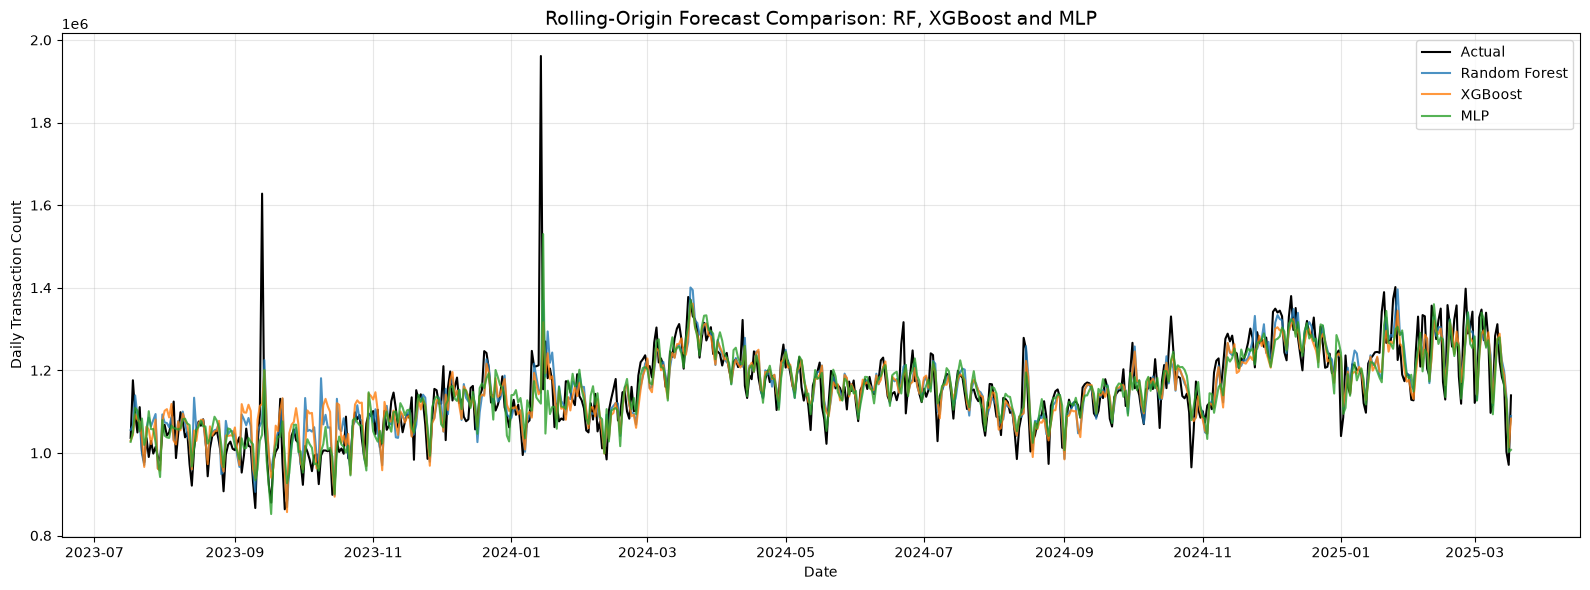

In [46]:
plt.figure(figsize=(16, 6))

plt.plot(
    validation.index,
    validation.values,
    label="Actual",
    color="black",
    linewidth=1.5
)

plt.plot(
    rf_rolling_forecast.index,
    rf_rolling_forecast.values,
    label="Random Forest",
    alpha=0.8
)

plt.plot(
    xgb_rolling_forecast.index,
    xgb_rolling_forecast.values,
    label="XGBoost",
    alpha=0.8
)

plt.plot(
    mlp_rolling_forecast.index,
    mlp_rolling_forecast.values,
    label="MLP",
    alpha=0.8
)

plt.title(
    "Rolling-Origin Forecast Comparison: RF, XGBoost and MLP",
    fontsize=14
)
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "25_rolling_origin_rf_xgb_mlp_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.7.1.4 Interpretation of the Forecast Comparison

The visual comparison shows that Random Forest, XGBoost, and MLP produce very similar rolling-origin forecasts.

All three models capture the general pattern and short-term fluctuations of Ethereum daily transaction activity. Their predictions overlap considerably throughout most of the validation period, indicating comparable forecasting behaviour.

However, all three models struggle to capture exceptional one-day activity spikes, particularly those observed in September 2023 and January 2024. This suggests that sudden and unusually large changes in network activity remain difficult to predict using the current feature set and fixed model parameters.

Although MLP achieves the lowest MAPE, XGBoost performs best in terms of MAE and RMSE. The visual comparison also reveals no substantial advantage for the neural network.

Overall, the results indicate that the MLP provides competitive forecasting performance but does not demonstrate a meaningful improvement over the tree-based models.

### 6.7.2 Long Short-Term Memory (LSTM)

Long Short-Term Memory (LSTM) is a type of recurrent neural network (RNN) designed to learn temporal dependencies in sequential data. Unlike conventional feedforward neural networks, LSTM networks maintain internal memory through cell states and gating mechanisms, allowing them to capture information over extended time intervals.

In this study, an LSTM model is investigated to forecast daily Ethereum transaction activity. The model uses historical transaction counts to learn temporal patterns and generate one-day-ahead forecasts.

The LSTM model is evaluated using a rolling-origin forecasting strategy. At each forecasting step, the model predicts the next day's transaction count using information available up to that day. The actual observation is then incorporated into the input history for the subsequent forecast.

To ensure a fair comparison, the LSTM model will use the same chronological training and validation periods established in Section 6.1. Model performance will be assessed using MAE, RMSE, and MAPE and compared with the Random Forest, XGBoost, and MLP models.

Given the computational limitations of the local hardware, a relatively small LSTM architecture and single-thread CPU execution are adopted.

#### 6.7.2.1 Loading and Inspecting the Dataset

The cleaned daily Ethereum transaction-count dataset is loaded into the Python 3.12 environment. The dataset is checked to confirm that its structure, date range, and observations are consistent with the data used in the earlier forecasting experiments.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch

# Path to the cleaned dataset
data_path = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\data\processed\ethereum_daily_transaction_counts_clean.csv"
)

# Load dataset
df_transactions = pd.read_csv(
    data_path,
    parse_dates=["block_date"]
)

# Inspect dataset
print("Dataset shape:", df_transactions.shape)
print("\nFirst five observations:")
display(df_transactions.head())

print("\nData types:")
print(df_transactions.dtypes)

print("\nDate range:")
print(df_transactions["block_date"].min())
print("to")
print(df_transactions["block_date"].max())

Dataset shape: (4066, 2)

First five observations:


,block_date,daily_transaction_count
0,2015-10-01,6421
1,2015-10-02,6063
2,2015-10-03,6112
3,2015-10-04,6624
4,2015-10-05,6279



Data types:
block_date                 datetime64[ns]
daily_transaction_count             int64
dtype: object

Date range:
2015-10-01 00:00:00
to
2026-11-17 00:00:00


In [2]:
# Configure PyTorch for the available CPU
torch.set_num_threads(1)
torch.set_num_interop_threads(1)

print("CPU threads:", torch.get_num_threads())
print("CPU interop threads:", torch.get_num_interop_threads())

CPU threads: 1
CPU interop threads: 1


#### 6.7.2.2 Preparing the Time Series and Training Data

The daily transaction count series is prepared using the date column as its index. The original chronological training and validation periods established in Section 6.1 are reconstructed to ensure consistency across forecasting models.

In [3]:
# Create daily time series
y = (
    df_transactions
    .set_index("block_date")["daily_transaction_count"]
    .asfreq("D")
)

# Recreate the chronological split
n = len(y)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = y.iloc[:train_end]
validation = y.iloc[train_end:validation_end]
test = y.iloc[validation_end:]

# Display split information
print("Total observations:", n)
print("\nTraining observations:", len(train))
print("Training period:", train.index.min().date(), "to", train.index.max().date())

print("\nValidation observations:", len(validation))
print("Validation period:", validation.index.min().date(), "to", validation.index.max().date())

print("\nTest observations:", len(test))
print("Test period:", test.index.min().date(), "to", test.index.max().date())

Total observations: 4066

Training observations: 2846
Training period: 2015-10-01 to 2023-07-16

Validation observations: 610
Validation period: 2023-07-17 to 2025-03-17

Test observations: 610
Test period: 2025-03-18 to 2026-11-17


#### 6.7.2.3 Creating Sequential Input Data

LSTM networks require sequential input data. A lookback window of 30 days is used to predict the next day's transaction count. Each input sequence contains the 30 preceding daily observations.

In [4]:
# Define the lookback window
lookback = 30

# Convert training series to NumPy array
train_values = train.to_numpy(dtype=np.float32)

# Create input sequences and corresponding targets
X_train_lstm = []
y_train_lstm = []

for i in range(lookback, len(train_values)):
    X_train_lstm.append(train_values[i-lookback:i])
    y_train_lstm.append(train_values[i])

# Convert to NumPy arrays
X_train_lstm = np.array(X_train_lstm, dtype=np.float32)
y_train_lstm = np.array(y_train_lstm, dtype=np.float32)

# Reshape inputs for LSTM: samples, time steps, features
X_train_lstm = X_train_lstm.reshape(
    X_train_lstm.shape[0], lookback, 1
)

print("Input shape:", X_train_lstm.shape)
print("Target shape:", y_train_lstm.shape)
print("Lookback window:", lookback, "days")

Input shape: (2816, 30, 1)
Target shape: (2816,)
Lookback window: 30 days


#### 6.7.2.4 Scaling Data and Creating PyTorch Tensors

The transaction counts are scaled using Min-Max normalization. The scaler is fitted exclusively on the training data to prevent information leakage. The resulting sequences and targets are then converted into PyTorch tensors.

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Fit scaler using training data only
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
).astype(np.float32)

# Create scaled training sequences
X_train_scaled = []
y_train_scaled = []

for i in range(lookback, len(train_scaled)):
    X_train_scaled.append(train_scaled[i-lookback:i])
    y_train_scaled.append(train_scaled[i])

X_train_scaled = np.array(X_train_scaled, dtype=np.float32)
y_train_scaled = np.array(y_train_scaled, dtype=np.float32)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

print("Scaled input shape:", X_train_tensor.shape)
print("Scaled target shape:", y_train_tensor.shape)
print("Scaled training minimum:", train_scaled.min())
print("Scaled training maximum:", train_scaled.max())

Scaled input shape: torch.Size([2816, 30, 1])
Scaled target shape: torch.Size([2816, 1])
Scaled training minimum: 0.0
Scaled training maximum: 1.0


#### 6.7.2.5 Defining the LSTM Architecture

A compact LSTM network is designed to forecast daily Ethereum transaction counts. The model uses a single LSTM layer with 16 hidden units, followed by a fully connected output layer that produces one numerical prediction.

A small architecture is selected to accommodate the available CPU hardware and memory.

In [6]:
import torch.nn as nn

class EthereumLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        last_output = lstm_output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction


# Initialize the model
lstm_model = EthereumLSTM()

print(lstm_model)

EthereumLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)


#### 6.7.2.6 Configuring the Training Process

The LSTM model is trained using the Adam optimizer and Mean Squared Error (MSE) loss. A learning rate of 0.001 and a small batch size are selected to support training on the available CPU hardware.

In [7]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create data loader
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)

# Define loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

# Training configuration
epochs = 20

print("Training samples:", len(train_dataset))
print("Batch size:", 32)
print("Number of epochs:", epochs)
print("Optimizer: Adam")
print("Loss function: MSE")

Training samples: 2816
Batch size: 32
Number of epochs: 20
Optimizer: Adam
Loss function: MSE


#### 6.7.2.7 Training the LSTM Model

The LSTM network is trained for 20 epochs using the training sequences. Training loss is recorded at each epoch to monitor convergence and learning progress.

In [8]:
# Train the LSTM model
lstm_model.train()

training_losses = []

for epoch in range(epochs):
    epoch_loss = 0.0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        predictions = lstm_model(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch_X.size(0)

    average_loss = epoch_loss / len(train_dataset)
    training_losses.append(average_loss)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.6f}"
    )

Epoch [1/20], Loss: 0.023990
Epoch [2/20], Loss: 0.035782
Epoch [3/20], Loss: 0.032588
Epoch [4/20], Loss: 0.021384
Epoch [5/20], Loss: 0.010638
Epoch [6/20], Loss: 0.004660
Epoch [7/20], Loss: 0.001763
Epoch [8/20], Loss: 0.001516
Epoch [9/20], Loss: 0.001533
Epoch [10/20], Loss: 0.001548
Epoch [11/20], Loss: 0.001563
Epoch [12/20], Loss: 0.001577
Epoch [13/20], Loss: 0.001589
Epoch [14/20], Loss: 0.001599
Epoch [15/20], Loss: 0.001605
Epoch [16/20], Loss: 0.001608
Epoch [17/20], Loss: 0.001606
Epoch [18/20], Loss: 0.001601
Epoch [19/20], Loss: 0.001594
Epoch [20/20], Loss: 0.001595


#### 6.7.2.8 LSTM Training Loss Analysis

The training loss across epochs is visualized to examine the learning process, convergence behavior, and potential signs of continued optimization after the initial improvement.

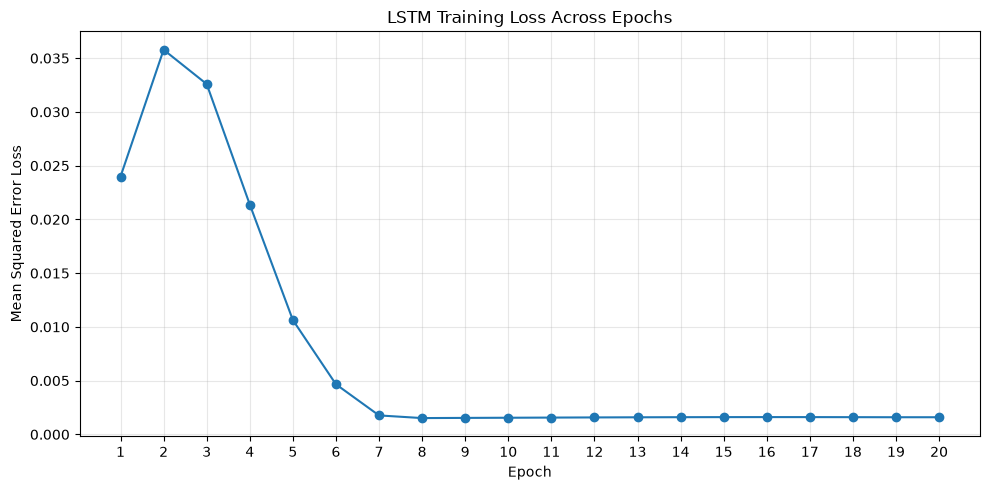

Chart saved: 26_lstm_training_loss.png


In [9]:
import matplotlib.pyplot as plt
from pathlib import Path

# Ensure visualization directory exists
visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)
visualizations_dir.mkdir(parents=True, exist_ok=True)

# Plot training loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    training_losses,
    marker="o"
)

plt.title("LSTM Training Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "26_lstm_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: 26_lstm_training_loss.png")

#### 6.7.2.9 Rolling-Origin Validation Forecast

The trained LSTM model is evaluated using a rolling-origin one-day-ahead forecasting strategy.

For each validation day, the model uses the most recent 30 observed daily transaction counts to predict the next day's activity. After each prediction, the actual observation is added to the historical sequence before forecasting the following day.

The model weights remain fixed throughout validation. The scaler is also kept unchanged and was fitted exclusively on the training data.

This approach evaluates the model under the same forecasting strategy used for the Random Forest, XGBoost, and MLP models.

In [10]:
# Generate rolling-origin validation forecasts
lstm_model.eval()

history = train.tolist()
lstm_validation_predictions = []

with torch.no_grad():
    for actual_value in validation:

        # Select the most recent 30 observations
        input_window = np.array(
            history[-lookback:],
            dtype=np.float32
        ).reshape(-1, 1)

        # Scale using the training-fitted scaler
        input_scaled = scaler.transform(input_window)

        # Convert to PyTorch tensor
        input_tensor = torch.tensor(
            input_scaled.reshape(1, lookback, 1),
            dtype=torch.float32
        )

        # Predict the next day
        prediction_scaled = lstm_model(input_tensor).numpy()

        # Convert prediction back to transaction counts
        prediction = scaler.inverse_transform(
            prediction_scaled
        )[0, 0]

        lstm_validation_predictions.append(prediction)

        # Append the actual observation to history
        history.append(actual_value)

# Convert predictions to a NumPy array
lstm_validation_predictions = np.array(
    lstm_validation_predictions
)

print("Validation forecasts:", len(lstm_validation_predictions))
print("Expected forecasts:", len(validation))
print("Missing predictions:", np.isnan(lstm_validation_predictions).sum())
print("\nFirst five predictions:")
print(lstm_validation_predictions[:5])

Validation forecasts: 610
Expected forecasts: 610
Missing predictions: 0

First five predictions:
[ 979457.06  985977.1  1015141.9  1017915.9  1013458.7 ]


#### 6.7.2.10 LSTM Validation Performance Metrics

The forecasting performance of the LSTM model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

These metrics quantify the magnitude of prediction errors and allow comparison with the previously evaluated forecasting models.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual validation observations
y_validation = validation.to_numpy()

# Calculate evaluation metrics
lstm_mae = mean_absolute_error(
    y_validation,
    lstm_validation_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        lstm_validation_predictions
    )
)

lstm_mape = np.mean(
    np.abs(
        (y_validation - lstm_validation_predictions)
        / y_validation
    )
) * 100

print("LSTM Rolling-Origin Validation Performance")
print("------------------------------------------")
print(f"MAE:  {lstm_mae:,.2f}")
print(f"RMSE: {lstm_rmse:,.2f}")
print(f"MAPE: {lstm_mape:.4f}%")

LSTM Rolling-Origin Validation Performance
------------------------------------------
MAE:  95,153.68
RMSE: 117,271.46
MAPE: 7.9396%


#### 6.7.2.11 Interpretation of LSTM Validation Performance

The LSTM achieved a validation MAE of 95,153.68, RMSE of 117,271.46, and MAPE of 7.9396%.

Although the LSTM outperformed the seasonal naive baseline, its forecasting accuracy was substantially lower than that of Random Forest, XGBoost, and MLP under the same rolling-origin evaluation strategy.

XGBoost achieved the lowest MAE and RMSE, while MLP achieved the lowest MAPE. The current LSTM configuration therefore did not provide a forecasting advantage over the previously evaluated machine learning models.

These results suggest that the LSTM architecture, with a 30-day lookback window and 16 hidden units, may not be sufficiently effective for capturing the patterns in this dataset.

#### 6.7.2.12 Visual Comparison of Actual and LSTM Forecasts

This section compares the actual daily Ethereum transaction counts with the LSTM rolling-origin one-day-ahead predictions over the validation period.

The visualization helps assess how closely the LSTM follows the observed activity patterns, including fluctuations and sudden changes in network activity.

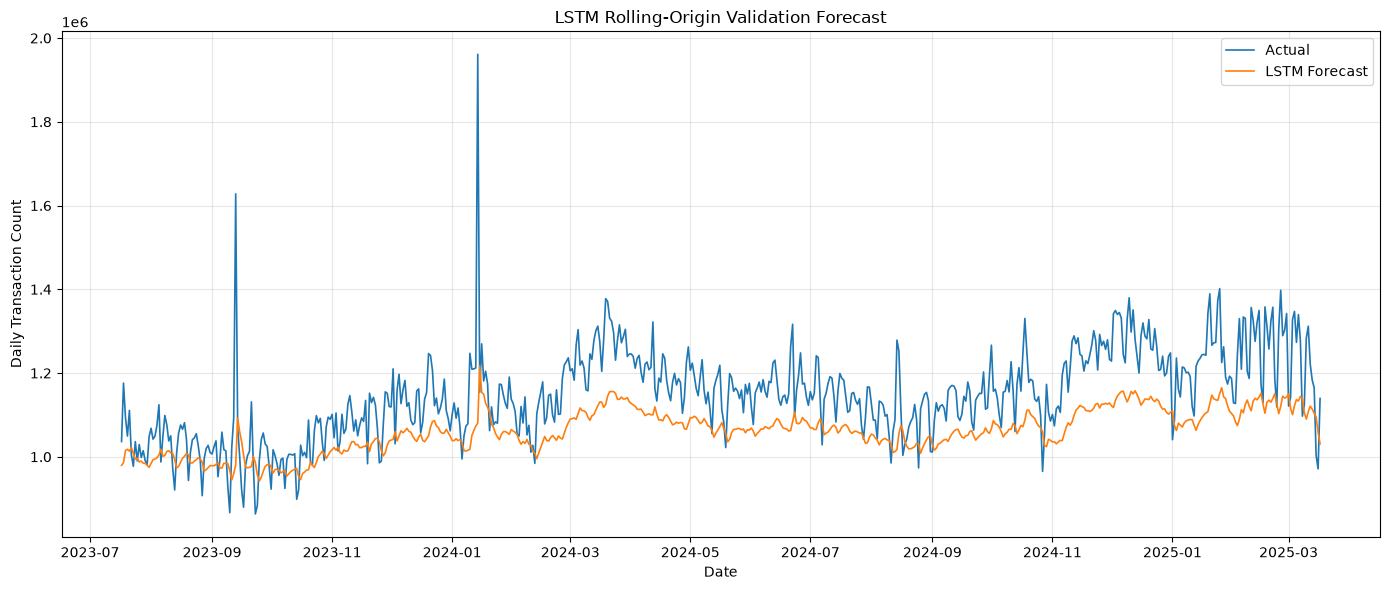

Chart saved: 27_lstm_rolling_origin_forecast.png


In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

# Ensure visualization directory exists
visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)
visualizations_dir.mkdir(parents=True, exist_ok=True)

# Plot actual and predicted values
plt.figure(figsize=(14, 6))

plt.plot(
    validation.index,
    y_validation,
    label="Actual",
    linewidth=1.2
)

plt.plot(
    validation.index,
    lstm_validation_predictions,
    label="LSTM Forecast",
    linewidth=1.2
)

plt.title("LSTM Rolling-Origin Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Transaction Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "27_lstm_rolling_origin_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: 27_lstm_rolling_origin_forecast.png")

#### 6.7.2.13 Comparative Performance of LSTM and Machine Learning Models

The LSTM validation results are compared with the Random Forest, XGBoost, and MLP models using MAE, RMSE, and MAPE.

All four models were evaluated using the same rolling-origin one-day-ahead forecasting strategy. This comparison identifies whether the LSTM provides an improvement over the previously evaluated approaches.

In [13]:
# Compare rolling-origin validation performance

comparison_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "MLP",
        "LSTM"
    ],
    "MAE": [
        41072.5895,
        40767.3516,
        40993.4397,
        lstm_mae
    ],
    "RMSE": [
        65454.1490,
        64079.5506,
        67193.7844,
        lstm_rmse
    ],
    "MAPE (%)": [
        3.5500,
        3.5288,
        3.5123,
        lstm_mape
    ]
})

display(
    comparison_results.sort_values("MAE").round(4)
)

,Model,MAE,RMSE,MAPE (%)
1,XGBoost,40767.3516,64079.5506,3.5288
2,MLP,40993.4397,67193.7844,3.5123
0,Random Forest,41072.5895,65454.1490,3.5500
3,LSTM,95153.6797,117271.4605,7.9396


#### 6.7.2.14 Interpretation of Comparative Model Performance

The comparison indicates that XGBoost achieved the best overall forecasting performance, with the lowest MAE (40,767.35) and RMSE (64,079.55). MLP achieved the lowest MAPE (3.5123%), while Random Forest produced similarly competitive results.

In contrast, the LSTM recorded a substantially higher MAE of 95,153.68, RMSE of 117,271.46, and MAPE of 7.9396%.

The LSTM's MAE was approximately 2.33 times that of XGBoost, indicating that the recurrent neural network did not provide an improvement over the machine learning approaches under the current experimental configuration.

These findings demonstrate that more complex neural network architectures do not necessarily produce better forecasts for this dataset. The tree-based models and MLP were more effective at capturing the patterns relevant to one-day-ahead Ethereum transaction forecasting.

#### 6.7.2.15 Visual Comparison of Model Performance

The forecasting performance of Random Forest, XGBoost, MLP, and LSTM is compared using three evaluation metrics: MAE, RMSE, and MAPE.

Separate panels are used because the metrics have different numerical scales. Lower values indicate better forecasting accuracy for all three metrics.

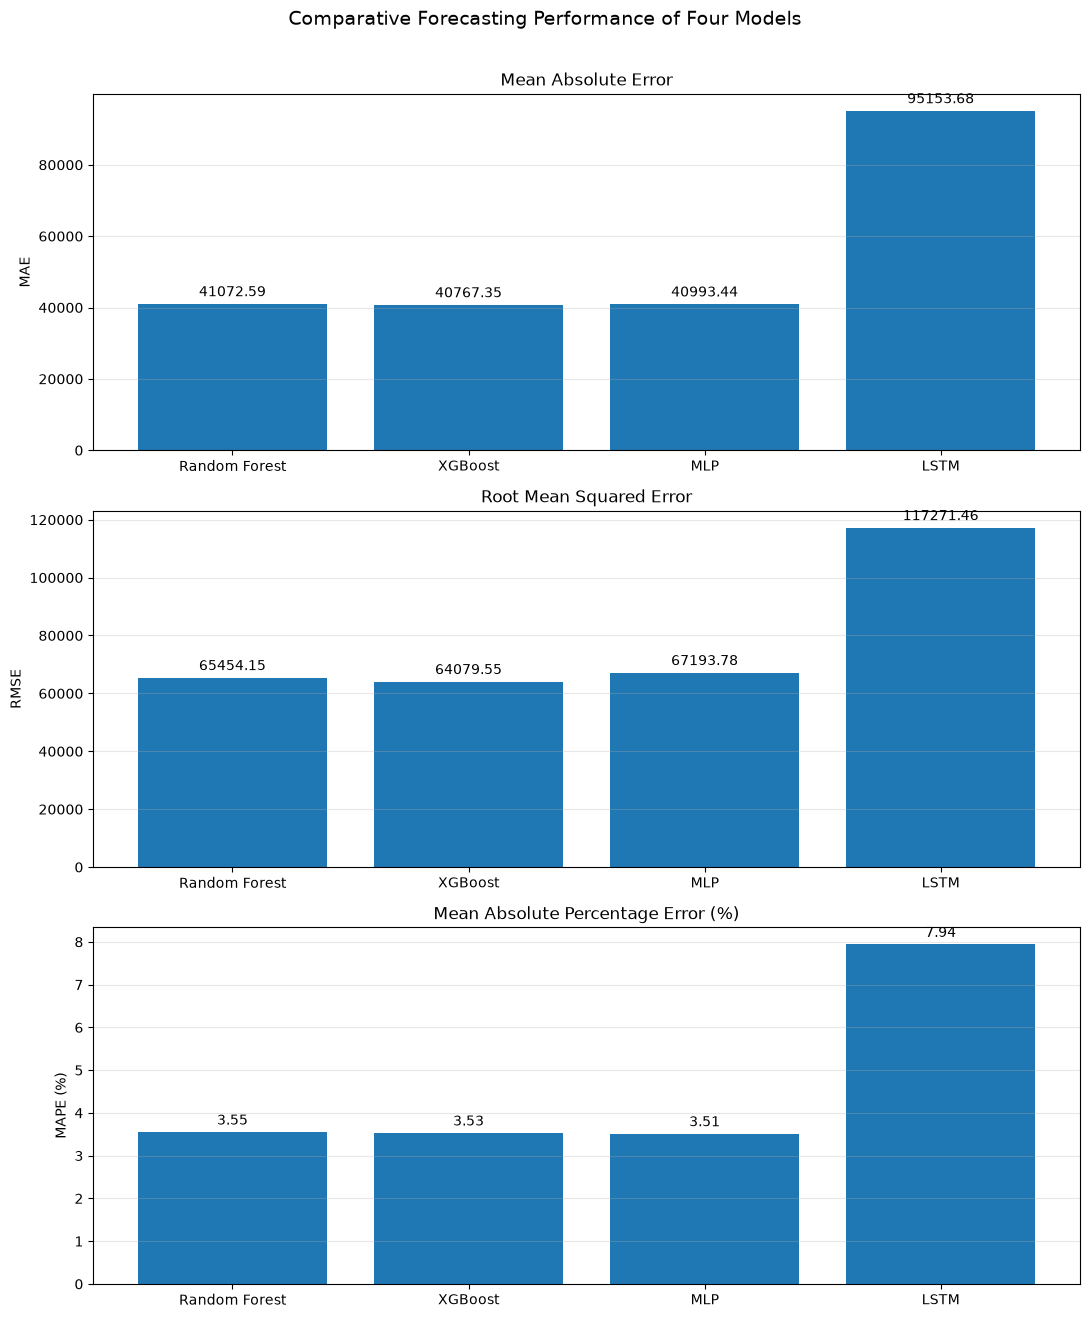

Chart saved: 28_four_model_performance_comparison.png


In [14]:
import matplotlib.pyplot as plt
from pathlib import Path

# Ensure visualization directory exists
visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)
visualizations_dir.mkdir(parents=True, exist_ok=True)

# Prepare comparison data
models = comparison_results["Model"]

fig, axes = plt.subplots(3, 1, figsize=(11, 13))

metrics = [
    ("MAE", "Mean Absolute Error"),
    ("RMSE", "Root Mean Squared Error"),
    ("MAPE (%)", "Mean Absolute Percentage Error (%)")
]

for ax, (metric, title) in zip(axes, metrics):

    values = comparison_results[metric]

    bars = ax.bar(models, values)

    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

    # Display values above bars
    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3
    )

plt.suptitle(
    "Comparative Forecasting Performance of Four Models",
    fontsize=14,
    y=1.01
)

plt.tight_layout()

# Save chart
plt.savefig(
    visualizations_dir / "28_four_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: 28_four_model_performance_comparison.png")

## 6.8 Overall Model Comparison

This section consolidates the forecasting results obtained from the baseline, statistical, machine learning, and neural network models.

The comparison considers three performance metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

Two evaluation strategies were used in this study:

1. Fixed-origin forecasting, applied to the baseline and statistical models.
2. Rolling-origin one-day-ahead forecasting, applied to Random Forest, XGBoost, MLP, and LSTM.

Because these strategies differ in how actual validation observations become available during forecasting, their performance metrics are presented in separate groups to avoid misleading direct comparisons.

The objective is to identify the strongest models within each evaluation strategy and assess the relative effectiveness of statistical, machine learning, and neural network approaches.

### 6.8.1 Fixed-Origin Forecasting Results

This subsection summarizes the validation performance of the baseline and statistical forecasting models.

All models in this group were evaluated using fixed-origin forecasting over the same 610-day validation period. The forecasting origin remained unchanged throughout the validation horizon.

In [15]:
# Consolidate fixed-origin validation results

fixed_origin_results = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive (7)",
        "ARIMA(1,1,0)",
        "ARIMA(0,1,1)",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)(1,0,0,7)",
        "SARIMA(1,1,1)(0,0,1,7)",
        "SARIMA(1,1,1)(1,0,1,7)"
    ],
    "MAE": [
        203493.2492,
        120320.3410,
        202800.057,
        162780.932,
        149920.167,
        142453.430,
        144260.844,
        197541.587
    ],
    "RMSE": [
        228642.3193,
        151445.2549,
        228003.753,
        191437.761,
        179174.323,
        171900.787,
        173690.918,
        231279.149
    ],
    "MAPE (%)": [
        17.0565,
        10.0668,
        16.996,
        13.536,
        12.443,
        11.814,
        11.965,
        16.476
    ]
})

fixed_origin_results = fixed_origin_results.sort_values(
    "MAE"
).reset_index(drop=True)

display(fixed_origin_results.round(4))

,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive (7),120320.3410,151445.2549,10.0668
1,"SARIMA(1,1,1)(1,0,0,7)",142453.4300,171900.7870,11.8140
2,"SARIMA(1,1,1)(0,0,1,7)",144260.8440,173690.9180,11.9650
3,"ARIMA(1,1,1)",149920.1670,179174.3230,12.4430
4,"ARIMA(0,1,1)",162780.9320,191437.7610,13.5360
5,"SARIMA(1,1,1)(1,0,1,7)",197541.5870,231279.1490,16.4760
6,"ARIMA(1,1,0)",202800.0570,228003.7530,16.9960
7,Naive,203493.2492,228642.3193,17.0565


#### 6.8.1.1 Interpretation of Fixed-Origin Results

The Seasonal Naive (7) model achieved the best performance among all fixed-origin forecasting models, with an MAE of 120,320.34, RMSE of 151,445.25, and MAPE of 10.0668%.

Among the statistical models, SARIMA(1,1,1)(1,0,0,7) achieved the lowest errors, followed by SARIMA(1,1,1)(0,0,1,7) and ARIMA(1,1,1).

However, none of the statistical models outperformed the Seasonal Naive baseline. This indicates that the weekly seasonal pattern provides a strong forecasting reference and that the additional complexity of the ARIMA and SARIMA models did not translate into better validation accuracy.

The results also demonstrate that selecting a statistical model based solely on information criteria such as AIC does not necessarily identify the model with the best out-of-sample forecasting performance.

### 6.8.2 Rolling-Origin Forecasting Results

This subsection summarizes the validation performance of the machine learning and neural network models.

Random Forest, XGBoost, MLP, and LSTM were evaluated using rolling-origin one-day-ahead forecasting over the same 610-day validation period.

At each forecasting step, the actual observation was incorporated into the historical input before predicting the following day. Model parameters remained fixed throughout validation.

Performance is compared using MAE, RMSE, and MAPE.

In [16]:
# Consolidate rolling-origin validation results

rolling_origin_results = comparison_results.copy()

rolling_origin_results = rolling_origin_results.sort_values(
    "MAE"
).reset_index(drop=True)

display(rolling_origin_results.round(4))

,Model,MAE,RMSE,MAPE (%)
0,XGBoost,40767.3516,64079.5506,3.5288
1,MLP,40993.4397,67193.7844,3.5123
2,Random Forest,41072.5895,65454.1490,3.5500
3,LSTM,95153.6797,117271.4605,7.9396


#### 6.8.2.1 Interpretation of Rolling-Origin Results

XGBoost achieved the lowest MAE (40,767.35) and RMSE (64,079.55), indicating the strongest overall performance in terms of absolute and squared prediction errors.

MLP achieved the lowest MAPE (3.5123%), although its advantage over XGBoost and Random Forest was marginal.

Random Forest produced similarly competitive results, with an MAE of 41,072.59 and RMSE of 65,454.15. The close performance of these three models suggests that their forecasting capabilities were broadly comparable under the rolling-origin evaluation strategy.

In contrast, LSTM recorded substantially higher errors, with an MAE of 95,153.68, RMSE of 117,271.46, and MAPE of 7.9396%. The current LSTM configuration therefore did not provide an advantage over the other machine learning and neural network approaches.

Overall, XGBoost demonstrated the strongest performance based on MAE and RMSE, while MLP achieved the lowest percentage error.

### 6.8.3 Comparative Discussion of Forecasting Approaches

The experimental results reveal differences in forecasting performance among statistical, machine learning, and neural network approaches.

The Seasonal Naive model achieved the best performance among the fixed-origin models, demonstrating the importance of weekly patterns in Ethereum transaction activity.

Among the rolling-origin models, XGBoost achieved the lowest MAE and RMSE, while MLP achieved the lowest MAPE. Random Forest also produced highly competitive results. These three models showed relatively similar forecasting performance.

The LSTM model did not outperform the other rolling-origin approaches under the current experimental configuration. Despite its ability to learn temporal dependencies through recurrent connections, its prediction errors were considerably higher than those of Random Forest, XGBoost, and MLP.

An important methodological distinction is that the baseline and statistical models were evaluated using fixed-origin forecasting, whereas the machine learning and neural network models used rolling-origin one-day-ahead forecasting. Consequently, their evaluation metrics should not be interpreted as a direct ranking across all models.

Overall, the findings suggest that relatively simple machine learning approaches can provide highly competitive forecasts of daily Ethereum transaction activity. Model complexity alone does not guarantee improved predictive performance.

### 6.8.4 Consolidated Forecasting Performance Summary

The following table summarizes the validation performance of all forecasting models investigated in this study.

The models are grouped according to their evaluation strategy: fixed-origin and rolling-origin forecasting. Performance metrics are presented separately within these groups because the forecasting procedures differ.

**Fixed-origin forecasting**

| Model | MAE | RMSE | MAPE (%) |
|---|---:|---:|---:|
| Seasonal Naive (7) | 120,320.34 | 151,445.25 | 10.0668 |
| SARIMA(1,1,1)(1,0,0,7) | 142,453.43 | 171,900.79 | 11.8140 |
| SARIMA(1,1,1)(0,0,1,7) | 144,260.84 | 173,690.92 | 11.9650 |
| ARIMA(1,1,1) | 149,920.17 | 179,174.32 | 12.4430 |
| ARIMA(0,1,1) | 162,780.93 | 191,437.76 | 13.5360 |
| SARIMA(1,1,1)(1,0,1,7) | 197,541.59 | 231,279.15 | 16.4760 |
| ARIMA(1,1,0) | 202,800.06 | 228,003.75 | 16.9960 |
| Naive | 203,493.25 | 228,642.32 | 17.0565 |

**Rolling-origin forecasting**

| Model | MAE | RMSE | MAPE (%) |
|---|---:|---:|---:|
| XGBoost | 40,767.35 | 64,079.55 | 3.5288 |
| MLP | 40,993.44 | 67,193.78 | 3.5123 |
| Random Forest | 41,072.59 | 65,454.15 | 3.5500 |
| LSTM | 95,153.68 | 117,271.46 | 7.9396 |

The Seasonal Naive model was the strongest fixed-origin model, while XGBoost achieved the lowest MAE and RMSE among the rolling-origin models. MLP recorded the lowest MAPE in the rolling-origin group.

These results provide a consolidated overview of model performance while preserving the distinction between the two evaluation strategies.

## 6.9 Summary and Main Findings

This study investigated the forecasting of daily Ethereum transaction activity using statistical, machine learning, and neural network approaches. Daily transaction data covering the period from 1 October 2015 to 17 November 2026 were analyzed.

The exploratory analysis revealed substantial long-term changes in network activity, considerable variability, and evidence of weekly temporal patterns. Stationarity tests indicated that the original time series was non-stationary, while first-order differencing produced a stationary series.

Eight forecasting approaches were investigated, including baseline, ARIMA, SARIMA, Random Forest, XGBoost, MLP, and LSTM models.

The main findings are summarized below:

1. **Weekly seasonality:** The Seasonal Naive model achieved the best performance among the fixed-origin models, highlighting the predictive importance of weekly patterns.

2. **Statistical forecasting:** SARIMA models generally outperformed non-seasonal ARIMA candidates, although none surpassed the Seasonal Naive baseline.

3. **Machine learning performance:** XGBoost achieved the lowest MAE and RMSE among the rolling-origin models. Random Forest and MLP produced similarly competitive results.

4. **Neural network performance:** MLP performed comparably to the tree-based models, whereas the LSTM did not provide an improvement under the current architecture and training configuration.

5. **Model complexity:** More complex models did not necessarily produce more accurate forecasts. The results demonstrate the importance of empirical validation rather than relying on model complexity alone.

6. **Abrupt activity spikes:** The rolling-origin tree-based models captured general fluctuations in network activity but underestimated some exceptional one-day transaction spikes, indicating a limitation in forecasting sudden changes.

An important methodological consideration is that fixed-origin and rolling-origin forecasts were evaluated using different information-update strategies. Therefore, their performance metrics should be interpreted within their respective evaluation groups rather than used to establish a direct ranking across all models.

Overall, the experiments demonstrate that machine learning approaches, particularly XGBoost, provide promising results for one-day-ahead forecasting of Ethereum transaction activity. However, further evaluation on the untouched test set is necessary to assess the generalization performance of the selected models.

## 6.10 Final Model Evaluation on the Test Dataset

The final stage of the forecasting experiment evaluates model generalization using the previously untouched test dataset, covering the period from 18 March 2025 to 17 November 2026.

The validation results from Section 6.8 are used to guide model selection. The test dataset is reserved exclusively for final performance assessment and is not used for model tuning or selection.

The evaluation considers MAE, RMSE, and MAPE, together with visual comparisons between actual and predicted daily Ethereum transaction counts.

The distinction between fixed-origin and rolling-origin forecasting strategies is maintained throughout the final evaluation.

In [17]:
# Check the current Python environment
import sys
import importlib.util

print("Python executable:", sys.executable)

print("\nRequired package availability:")
for package in ["xgboost", "sklearn", "torch", "numpy", "pandas"]:
    print(f"{package}:",
          "Available" if importlib.util.find_spec(package) else "Not installed")

print("\nExisting forecasting objects:")
for name in ["xgb_model", "rf_model", "mlp_model", "lstm_model", "create_features"]:
    print(f"{name}:",
          "Available" if name in globals() else "Not available")

Python executable: E:\DataScience\Ethereum_TimeSeries_Forecasting\pytorch312_env\Scripts\python.exe

Required package availability:
xgboost: Not installed
sklearn: Available
torch: Available
numpy: Available
pandas: Available

Existing forecasting objects:
xgb_model: Not available
rf_model: Not available
mlp_model: Not available
lstm_model: Available
create_features: Not available


In [1]:
# Configure the CPU and verify the packages
import torch
import xgboost
import numpy as np
import pandas as pd
import sklearn

# Limit CPU threading for your laptop
torch.set_num_threads(1)
torch.set_num_interop_threads(1)

print("PyTorch:", torch.__version__)
print("XGBoost:", xgboost.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nCPU threads:", torch.get_num_threads())
print("CPU interop threads:", torch.get_num_interop_threads())

PyTorch: 2.15.0+cpu
XGBoost: 3.4.1
NumPy: 1.26.4
Pandas: 2.2.3
Scikit-learn: 1.6.1

CPU threads: 1
CPU interop threads: 1


### 6.10.1 Reloading the Dataset and Reconstructing the Chronological Split

The cleaned daily Ethereum transaction dataset is reloaded after the kernel restart. The original chronological training, validation, and test periods are reconstructed to preserve the evaluation design.

In [2]:
import pandas as pd
from pathlib import Path

data_path = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\data\processed\ethereum_daily_transaction_counts_clean.csv"
)

df = pd.read_csv(data_path, parse_dates=["block_date"])
df = df.set_index("block_date").sort_index()

y = df["daily_transaction_count"]

train = y.iloc[:2846]
validation = y.iloc[2846:3456]
test = y.iloc[3456:]

print("Total observations:", len(y))
print("Training:", len(train), train.index.min().date(), "to", train.index.max().date())
print("Validation:", len(validation), validation.index.min().date(), "to", validation.index.max().date())
print("Test:", len(test), test.index.min().date(), "to", test.index.max().date())

Total observations: 4066
Training: 2846 2015-10-01 to 2023-07-16
Validation: 610 2023-07-17 to 2025-03-17
Test: 610 2025-03-18 to 2026-11-17


### 6.10.2 Reconstructing the Machine Learning Features

The same lag-based and calendar-based predictors used during validation are reconstructed. All rolling statistics are calculated using past observations only, preventing future information from entering the predictors.

In [3]:
def create_features(series):
    features = pd.DataFrame(index=series.index)

    features["lag_1"] = series.shift(1)
    features["lag_7"] = series.shift(7)
    features["lag_14"] = series.shift(14)
    features["lag_28"] = series.shift(28)

    features["rolling_mean_7"] = (
        series.shift(1).rolling(window=7).mean()
    )
    features["rolling_mean_30"] = (
        series.shift(1).rolling(window=30).mean()
    )
    features["rolling_std_7"] = (
        series.shift(1).rolling(window=7).std()
    )

    features["day_of_week"] = series.index.dayofweek
    features["day_of_month"] = series.index.day
    features["month"] = series.index.month

    features["target"] = series

    return features.dropna()


train_val = pd.concat([train, validation])

train_val_features = create_features(train_val)

X_train_val = train_val_features.drop(columns=["target"])
y_train_val = train_val_features["target"]

print("Training + validation observations:", len(train_val))
print("Supervised training rows:", len(X_train_val))
print("Number of predictors:", X_train_val.shape[1])
print("\nPredictors:")
print(X_train_val.columns.tolist())

Training + validation observations: 3456
Supervised training rows: 3426
Number of predictors: 10

Predictors:
['lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_30', 'rolling_std_7', 'day_of_week', 'day_of_month', 'month']


### 6.10.3 Final XGBoost Model Training

The XGBoost model is retrained using the combined training and validation datasets. The hyperparameters remain unchanged from the validation experiment. The fitted model is then reserved for rolling-origin evaluation on the untouched test dataset.

In [4]:
from xgboost import XGBRegressor

xgb_final_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

xgb_final_model.fit(X_train_val, y_train_val)

print("Final XGBoost model trained successfully.")
print("Training observations:", len(X_train_val))
print("Number of predictors:", X_train_val.shape[1])

Final XGBoost model trained successfully.
Training observations: 3426
Number of predictors: 10


### 6.10.4 XGBoost Rolling-Origin Test Forecast

The final XGBoost model generates one-day-ahead predictions throughout the test period. After each prediction, the corresponding actual observation is incorporated into the historical series. Model parameters remain fixed, and no test observations are used for model fitting.

In [5]:
history = train_val.copy()
xgb_test_predictions = []

for date in test.index:

    current_features = create_features(history)

    X_next = current_features.drop(columns=["target"]).iloc[[-1]]

    prediction = xgb_final_model.predict(X_next)[0]

    xgb_test_predictions.append(prediction)

    # Add the actual observation only after making the prediction
    history.loc[date] = test.loc[date]

xgb_test_predictions = pd.Series(
    xgb_test_predictions,
    index=test.index,
    name="XGBoost_Prediction"
)

print("Test observations:", len(test))
print("Predictions generated:", len(xgb_test_predictions))
print("Missing predictions:", xgb_test_predictions.isna().sum())
print("\nFirst five predictions:")
print(xgb_test_predictions.head())

Test observations: 610
Predictions generated: 610
Missing predictions: 0

First five predictions:
block_date
2025-03-18    1127313.625
2025-03-19    1173926.625
2025-03-20    1164861.000
2025-03-21    1200080.250
2025-03-22    1197591.750
Name: XGBoost_Prediction, dtype: float32


#### 6.10.5 XGBoost Test-Set Performance Metrics

The predictive accuracy of the final XGBoost model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_test_mae = mean_absolute_error(
    test, xgb_test_predictions
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(test, xgb_test_predictions)
)

xgb_test_mape = np.mean(
    np.abs((test - xgb_test_predictions) / test)
) * 100

print("XGBoost — Final Test Performance")
print("--------------------------------")
print(f"MAE:  {xgb_test_mae:,.4f}")
print(f"RMSE: {xgb_test_rmse:,.4f}")
print(f"MAPE: {xgb_test_mape:.4f}%")

XGBoost — Final Test Performance
--------------------------------
MAE:  391,641.6562
RMSE: 546,286.9651
MAPE: 18.2307%


#### 6.10.6 Visual Assessment of XGBoost Test Forecasts

The actual daily transaction counts are compared with the rolling-origin XGBoost predictions across the complete test period. This visualization helps identify periods of systematic underestimation, unusual activity, and changes in forecasting accuracy.

In [8]:
from pathlib import Path

visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)

visualizations_dir.mkdir(parents=True, exist_ok=True)

print("Visualization directory ready:", visualizations_dir)

Visualization directory ready: E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations


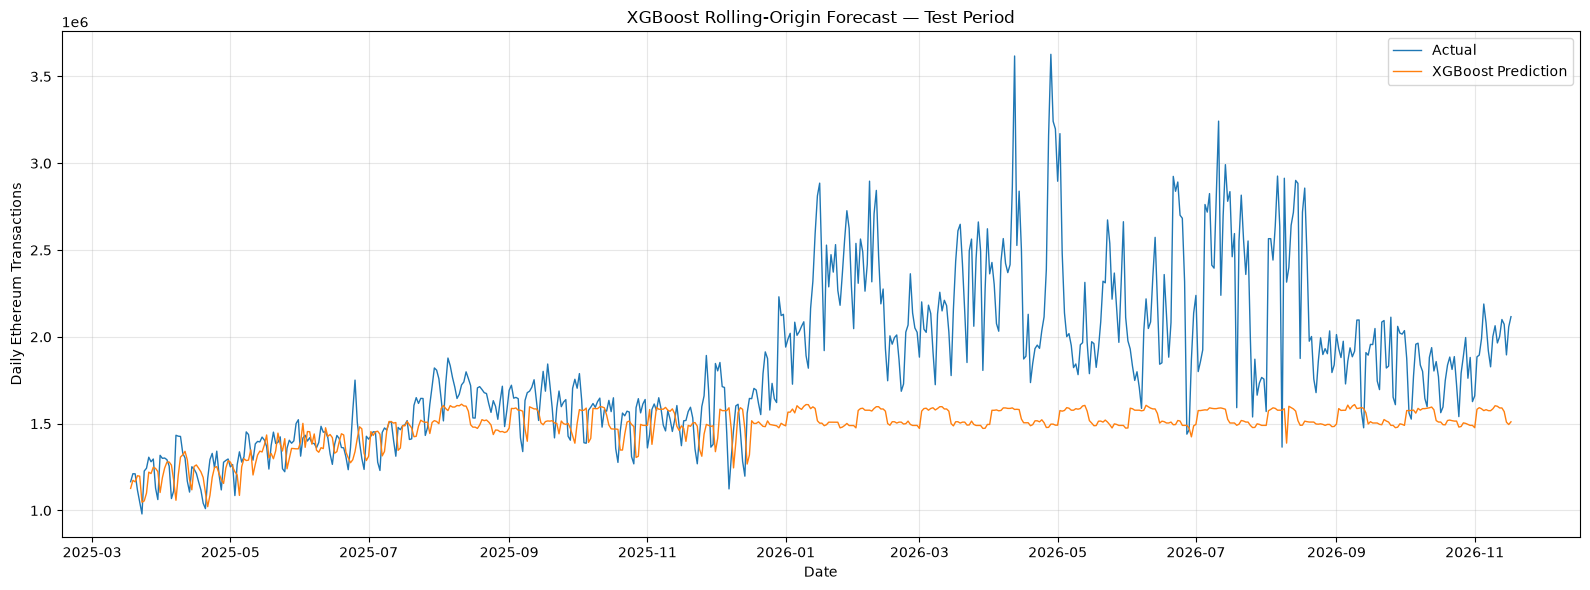

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual",
    linewidth=1
)

plt.plot(
    xgb_test_predictions.index,
    xgb_test_predictions.values,
    label="XGBoost Prediction",
    linewidth=1
)

plt.title("XGBoost Rolling-Origin Forecast — Test Period")
plt.xlabel("Date")
plt.ylabel("Daily Ethereum Transactions")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "29_xgboost_test_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.10.7 Year-Based Test Performance Analysis

To investigate the deterioration in forecasting accuracy during 2026, test-set performance is evaluated separately for 2025 and 2026. This comparison helps identify whether the forecasting errors are associated with changes in Ethereum network activity over time.

In [10]:
for year in [2025, 2026]:

    actual_year = test[test.index.year == year]
    predicted_year = xgb_test_predictions[
        xgb_test_predictions.index.year == year
    ]

    mae = mean_absolute_error(actual_year, predicted_year)
    rmse = np.sqrt(mean_squared_error(actual_year, predicted_year))
    mape = np.mean(
        np.abs((actual_year - predicted_year) / actual_year)
    ) * 100

    print(f"\nXGBoost Test Performance — {year}")
    print("-" * 40)
    print(f"Observations: {len(actual_year)}")
    print(f"MAE:  {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAPE: {mape:.4f}%")


XGBoost Test Performance — 2025
----------------------------------------
Observations: 289
MAE:  132,847.77
RMSE: 171,075.41
MAPE: 8.6931%

XGBoost Test Performance — 2026
----------------------------------------
Observations: 321
MAE:  624,636.69
RMSE: 735,363.64
MAPE: 26.8175%


In [11]:
# Compare annual transaction activity
annual_comparison = pd.DataFrame({
    "Actual_Mean": test.groupby(test.index.year).mean(),
    "Actual_Std": test.groupby(test.index.year).std(),
    "Predicted_Mean": xgb_test_predictions.groupby(
        xgb_test_predictions.index.year
    ).mean(),
    "Predicted_Std": xgb_test_predictions.groupby(
        xgb_test_predictions.index.year
    ).std()
})

annual_comparison["Mean_Underestimation"] = (
    annual_comparison["Actual_Mean"]
    - annual_comparison["Predicted_Mean"]
)

print(annual_comparison.round(2))

            Actual_Mean  Actual_Std  Predicted_Mean  Predicted_Std  \
block_date                                                           
2025         1488481.97   202692.25      1420417.25      135286.94   
2026         2157953.51   393565.82      1536243.50       45118.64   

            Mean_Underestimation  
block_date                        
2025                    68064.72  
2026                   621710.01  


#### 6.10.8 Analysis of XGBoost Forecast Errors Over Time

The daily forecast error is calculated as the difference between actual and predicted transaction counts. Positive values indicate underestimation, while negative values indicate overestimation. A 30-day rolling average is used to examine changes in forecast bias throughout the test period.

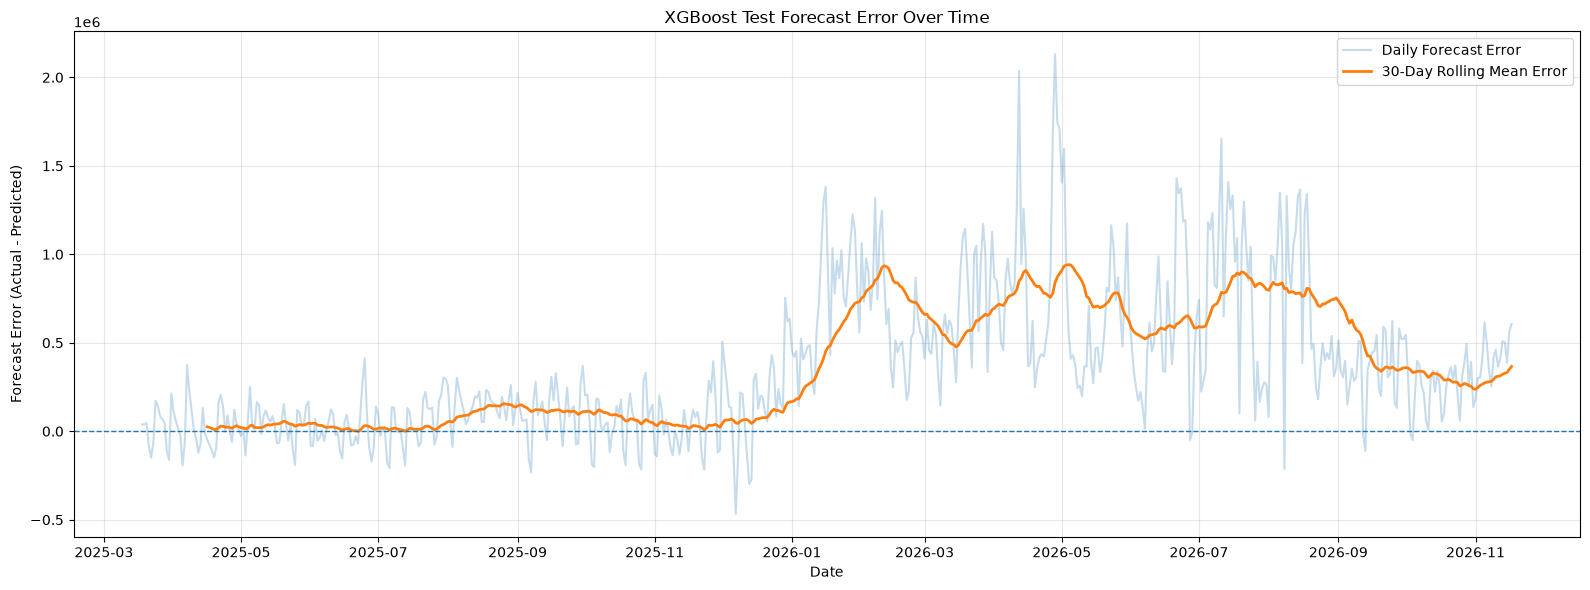

In [12]:
xgb_test_errors = test - xgb_test_predictions

xgb_test_rolling_error = xgb_test_errors.rolling(
    window=30
).mean()

plt.figure(figsize=(16, 6))

plt.plot(
    xgb_test_errors.index,
    xgb_test_errors.values,
    alpha=0.25,
    label="Daily Forecast Error"
)

plt.plot(
    xgb_test_rolling_error.index,
    xgb_test_rolling_error.values,
    linewidth=2,
    label="30-Day Rolling Mean Error"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("XGBoost Test Forecast Error Over Time")
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Predicted)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "30_xgboost_test_forecast_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.10.8.1 Interpretation of Forecast Errors

The forecast error analysis reveals a deterioration in XGBoost performance over the test period.

During 2025, forecast errors were comparatively moderate. However, the model increasingly underestimated daily transaction counts during 2026, particularly as the overall level of network activity increased.

The 30-day rolling mean error helps illustrate this changing forecast bias. Positive error values indicate underestimation, while negative values indicate overestimation.

These findings are consistent with potential concept drift or structural changes in Ethereum network activity. The model also substantially underestimated the variability of daily transaction counts in 2026, producing comparatively smooth predictions.

Overall, although XGBoost demonstrated strong validation performance, its test results reveal limited adaptability to the changing activity patterns observed during 2026.

### 6.10.9 Random Forest Final Test Evaluation

The Random Forest model is retrained using the combined training and validation datasets, retaining the hyperparameters established during validation. Its test performance is evaluated using the same rolling-origin procedure as XGBoost.

In [13]:
from sklearn.ensemble import RandomForestRegressor

rf_final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1
)

rf_final_model.fit(X_train_val, y_train_val)

print("Final Random Forest model trained successfully.")
print("Training observations:", len(X_train_val))
print("Number of predictors:", X_train_val.shape[1])

Final Random Forest model trained successfully.
Training observations: 3426
Number of predictors: 10


#### 6.10.9.1 Random Forest Rolling-Origin Test Forecast

The final Random Forest model generates one-day-ahead predictions throughout the test period. After each prediction, the actual observation is incorporated into the historical series, while the fitted model remains unchanged.

In [14]:
history = train_val.copy()
rf_test_predictions = []

for date in test.index:

    current_features = create_features(history)

    X_next = current_features.drop(columns=["target"]).iloc[[-1]]

    prediction = rf_final_model.predict(X_next)[0]

    rf_test_predictions.append(prediction)

    # Add the actual observation after prediction
    history.loc[date] = test.loc[date]

rf_test_predictions = pd.Series(
    rf_test_predictions,
    index=test.index,
    name="RandomForest_Prediction"
)

print("Test observations:", len(test))
print("Predictions generated:", len(rf_test_predictions))
print("Missing predictions:", rf_test_predictions.isna().sum())
print("\nFirst five predictions:")
print(rf_test_predictions.head())

Test observations: 610
Predictions generated: 610
Missing predictions: 0

First five predictions:
block_date
2025-03-18    1.109821e+06
2025-03-19    1.180282e+06
2025-03-20    1.177209e+06
2025-03-21    1.231387e+06
2025-03-22    1.223526e+06
Name: RandomForest_Prediction, dtype: float64


#### 6.10.9.2 Random Forest Test-Set Performance Metrics

The final Random Forest model is evaluated using MAE, RMSE, and MAPE to quantify its predictive accuracy on the untouched test period.

In [15]:
rf_test_mae = mean_absolute_error(
    test, rf_test_predictions
)

rf_test_rmse = np.sqrt(
    mean_squared_error(test, rf_test_predictions)
)

rf_test_mape = np.mean(
    np.abs((test - rf_test_predictions) / test)
) * 100

print("Random Forest — Final Test Performance")
print("---------------------------------------")
print(f"MAE:  {rf_test_mae:,.4f}")
print(f"RMSE: {rf_test_rmse:,.4f}")
print(f"MAPE: {rf_test_mape:.4f}%")

Random Forest — Final Test Performance
---------------------------------------
MAE:  341,539.0746
RMSE: 491,271.8505
MAPE: 15.8602%


In [16]:
# Compare annual Random Forest performance
for year in [2025, 2026]:

    actual_year = test[test.index.year == year]
    predicted_year = rf_test_predictions[
        rf_test_predictions.index.year == year
    ]

    mae = mean_absolute_error(actual_year, predicted_year)
    rmse = np.sqrt(mean_squared_error(actual_year, predicted_year))
    mape = np.mean(
        np.abs((actual_year - predicted_year) / actual_year)
    ) * 100

    print(f"\nRandom Forest Test Performance — {year}")
    print("-" * 45)
    print(f"Observations: {len(actual_year)}")
    print(f"MAE:  {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAPE: {mape:.4f}%")


Random Forest Test Performance — 2025
---------------------------------------------
Observations: 289
MAE:  119,362.86
RMSE: 157,308.91
MAPE: 7.9755%

Random Forest Test Performance — 2026
---------------------------------------------
Observations: 321
MAE:  541,566.88
RMSE: 660,573.43
MAPE: 22.9589%


#### 6.10.9.3 Visual Comparison of Random Forest and XGBoost Test Forecasts

The rolling-origin test predictions of Random Forest and XGBoost are compared with actual daily Ethereum transaction counts. This visualization provides a direct assessment of their forecasting behaviour throughout the test period.

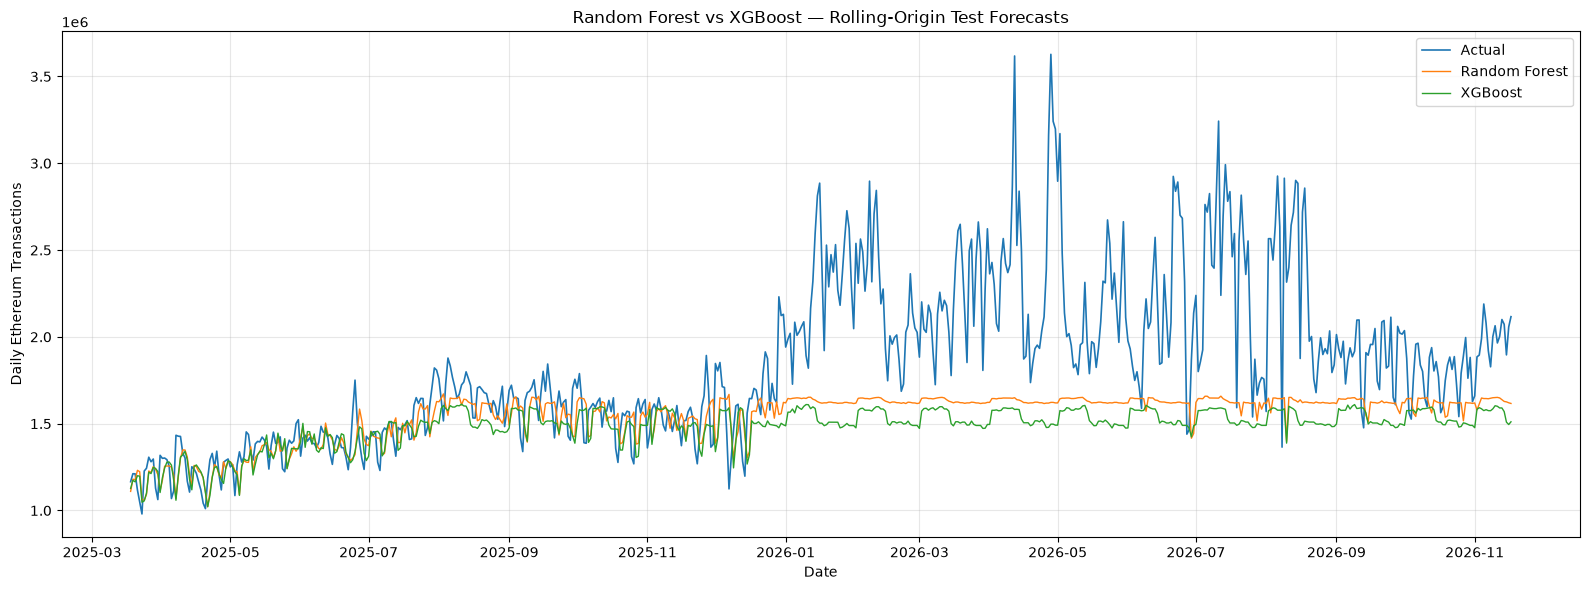

In [17]:
plt.figure(figsize=(16, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual",
    linewidth=1.2
)

plt.plot(
    rf_test_predictions.index,
    rf_test_predictions.values,
    label="Random Forest",
    linewidth=1
)

plt.plot(
    xgb_test_predictions.index,
    xgb_test_predictions.values,
    label="XGBoost",
    linewidth=1
)

plt.title("Random Forest vs XGBoost — Rolling-Origin Test Forecasts")
plt.xlabel("Date")
plt.ylabel("Daily Ethereum Transactions")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "31_rf_xgboost_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.10.10 MLP Final Test Evaluation

The Multilayer Perceptron (MLP) model is retrained using the combined training and validation datasets. The original architecture, feature scaling, target scaling, and hyperparameters are retained to ensure consistency with the validation experiment.

In [18]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

mlp_final_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            alpha=0.001,
            batch_size=64,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=False,
            random_state=42
        ))
    ]),
    transformer=StandardScaler()
)

mlp_final_model.fit(X_train_val, y_train_val)

print("Final MLP model trained successfully.")
print("Training observations:", len(X_train_val))
print("Number of predictors:", X_train_val.shape[1])

Final MLP model trained successfully.
Training observations: 3426
Number of predictors: 10


#### 6.10.10.1 MLP Rolling-Origin Test Forecast

The final MLP model generates one-day-ahead predictions throughout the test period. After each prediction, the actual observation is incorporated into the historical series, while the fitted model weights remain unchanged.

In [19]:
history = train_val.copy()
mlp_test_predictions = []

for date in test.index:

    current_features = create_features(history)

    X_next = current_features.drop(columns=["target"]).iloc[[-1]]

    prediction = mlp_final_model.predict(X_next)[0]

    mlp_test_predictions.append(prediction)

    # Add the actual observation after prediction
    history.loc[date] = test.loc[date]

mlp_test_predictions = pd.Series(
    mlp_test_predictions,
    index=test.index,
    name="MLP_Prediction"
)

print("Test observations:", len(test))
print("Predictions generated:", len(mlp_test_predictions))
print("Missing predictions:", mlp_test_predictions.isna().sum())
print("\nFirst five predictions:")
print(mlp_test_predictions.head())

Test observations: 610
Predictions generated: 610
Missing predictions: 0

First five predictions:
block_date
2025-03-18    1.022037e+06
2025-03-19    1.140677e+06
2025-03-20    1.138057e+06
2025-03-21    1.152864e+06
2025-03-22    1.133432e+06
Name: MLP_Prediction, dtype: float64


#### 6.10.10.2 MLP Test-Set Performance Metrics

The final MLP model is evaluated using MAE, RMSE, and MAPE to assess its predictive accuracy on the untouched test dataset.

In [20]:
mlp_test_mae = mean_absolute_error(
    test, mlp_test_predictions
)

mlp_test_rmse = np.sqrt(
    mean_squared_error(test, mlp_test_predictions)
)

mlp_test_mape = np.mean(
    np.abs((test - mlp_test_predictions) / test)
) * 100

print("MLP — Final Test Performance")
print("-----------------------------")
print(f"MAE:  {mlp_test_mae:,.4f}")
print(f"RMSE: {mlp_test_rmse:,.4f}")
print(f"MAPE: {mlp_test_mape:.4f}%")

MLP — Final Test Performance
-----------------------------
MAE:  240,435.8823
RMSE: 357,392.4133
MAPE: 11.5118%


In [21]:
# Annual MLP performance
for year in [2025, 2026]:

    actual_year = test[test.index.year == year]
    predicted_year = mlp_test_predictions[
        mlp_test_predictions.index.year == year
    ]

    mae = mean_absolute_error(actual_year, predicted_year)
    rmse = np.sqrt(mean_squared_error(actual_year, predicted_year))
    mape = np.mean(
        np.abs((actual_year - predicted_year) / actual_year)
    ) * 100

    print(f"\nMLP Test Performance — {year}")
    print("-" * 40)
    print(f"Observations: {len(actual_year)}")
    print(f"MAE:  {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAPE: {mape:.4f}%")


MLP Test Performance — 2025
----------------------------------------
Observations: 289
MAE:  118,188.67
RMSE: 155,735.40
MAPE: 7.7766%

MLP Test Performance — 2026
----------------------------------------
Observations: 321
MAE:  350,496.45
RMSE: 469,989.16
MAPE: 14.8746%


### 6.10.11 LSTM Final Test Evaluation

The Long Short-Term Memory (LSTM) model is retrained using the combined training and validation datasets. The original network architecture and training configuration are retained to ensure consistency with the validation experiment.

A 30-day lookback window is used to capture temporal dependencies in daily Ethereum transaction activity.

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CPU configuration
torch.set_num_threads(1)

# Scale combined training and validation data
lookback = 30

lstm_scaler = MinMaxScaler(feature_range=(0, 1))

train_val_scaled = lstm_scaler.fit_transform(
    train_val.values.reshape(-1, 1)
)

# Create training sequences
X_lstm_train = []
y_lstm_train = []

for i in range(lookback, len(train_val_scaled)):
    X_lstm_train.append(
        train_val_scaled[i-lookback:i]
    )
    y_lstm_train.append(
        train_val_scaled[i]
    )

X_lstm_train = torch.tensor(
    np.array(X_lstm_train),
    dtype=torch.float32
)

y_lstm_train = torch.tensor(
    np.array(y_lstm_train),
    dtype=torch.float32
)

# DataLoader
train_dataset = TensorDataset(
    X_lstm_train,
    y_lstm_train
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# LSTM architecture
class LSTMModel(nn.Module):

    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])


# Initialize model
lstm_final_model = LSTMModel(
    input_size=1,
    hidden_size=16
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_final_model.parameters(),
    lr=0.001
)

# Training
epochs = 20
lstm_training_losses = []

for epoch in range(epochs):

    lstm_final_model.train()
    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = lstm_final_model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(X_batch)

    average_loss = epoch_loss / len(train_dataset)
    lstm_training_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} "
        f"- Loss: {average_loss:.6f}"
    )

print("\nFinal LSTM model trained successfully.")
print("Training sequences:", len(X_lstm_train))
print("Lookback window:", lookback)

Epoch 01/20 - Loss: 0.040042
Epoch 02/20 - Loss: 0.002497
Epoch 03/20 - Loss: 0.001292
Epoch 04/20 - Loss: 0.001247
Epoch 05/20 - Loss: 0.001223
Epoch 06/20 - Loss: 0.001175
Epoch 07/20 - Loss: 0.001198
Epoch 08/20 - Loss: 0.001146
Epoch 09/20 - Loss: 0.001152
Epoch 10/20 - Loss: 0.001155
Epoch 11/20 - Loss: 0.001135
Epoch 12/20 - Loss: 0.001146
Epoch 13/20 - Loss: 0.001148
Epoch 14/20 - Loss: 0.001138
Epoch 15/20 - Loss: 0.001115
Epoch 16/20 - Loss: 0.001118
Epoch 17/20 - Loss: 0.001098
Epoch 18/20 - Loss: 0.001184
Epoch 19/20 - Loss: 0.001098
Epoch 20/20 - Loss: 0.001080

Final LSTM model trained successfully.
Training sequences: 3426
Lookback window: 30


#### 6.10.11.1 LSTM Rolling-Origin Test Forecast

The final LSTM model generates one-day-ahead predictions throughout the test period using a 30-day historical window. After each prediction, the actual observation is incorporated into the history. The model weights and scaling parameters remain fixed throughout the evaluation.

In [24]:
history = train_val.copy()
lstm_test_predictions = []

lstm_final_model.eval()

for date in test.index:

    # Extract the previous 30 actual observations
    recent_values = history.iloc[-lookback:].values.reshape(-1, 1)

    # Apply the training scaler
    recent_scaled = lstm_scaler.transform(recent_values)

    # Convert to PyTorch tensor
    X_next = torch.tensor(
        recent_scaled.reshape(1, lookback, 1),
        dtype=torch.float32
    )

    # Generate prediction
    with torch.no_grad():
        prediction_scaled = lstm_final_model(X_next).numpy()

    # Convert prediction back to original scale
    prediction = lstm_scaler.inverse_transform(
        prediction_scaled
    )[0, 0]

    lstm_test_predictions.append(prediction)

    # Add actual observation after prediction
    history.loc[date] = test.loc[date]

lstm_test_predictions = pd.Series(
    lstm_test_predictions,
    index=test.index,
    name="LSTM_Prediction"
)

print("Test observations:", len(test))
print("Predictions generated:", len(lstm_test_predictions))
print("Missing predictions:", lstm_test_predictions.isna().sum())

print("\nFirst five predictions:")
print(lstm_test_predictions.head())

Test observations: 610
Predictions generated: 610
Missing predictions: 0

First five predictions:
block_date
2025-03-18    1137403.875
2025-03-19    1145684.250
2025-03-20    1162522.000
2025-03-21    1175524.375
2025-03-22    1164993.250
Name: LSTM_Prediction, dtype: float32


#### 6.10.11.2 LSTM Test-Set Performance Metrics

The final LSTM model is evaluated using MAE, RMSE, and MAPE to assess its forecasting accuracy on the untouched test dataset.

In [25]:
lstm_test_mae = mean_absolute_error(
    test, lstm_test_predictions
)

lstm_test_rmse = np.sqrt(
    mean_squared_error(test, lstm_test_predictions)
)

lstm_test_mape = np.mean(
    np.abs((test - lstm_test_predictions) / test)
) * 100

print("LSTM — Final Test Performance")
print("-----------------------------")
print(f"MAE:  {lstm_test_mae:,.4f}")
print(f"RMSE: {lstm_test_rmse:,.4f}")
print(f"MAPE: {lstm_test_mape:.4f}%")

LSTM — Final Test Performance
-----------------------------
MAE:  188,525.8281
RMSE: 274,566.2209
MAPE: 9.3768%


In [26]:
# Evaluate LSTM separately for 2025 and 2026
for year in [2025, 2026]:

    actual_year = test[test.index.year == year]
    predicted_year = lstm_test_predictions[
        lstm_test_predictions.index.year == year
    ]

    mae = mean_absolute_error(actual_year, predicted_year)
    rmse = np.sqrt(mean_squared_error(actual_year, predicted_year))
    mape = np.mean(
        np.abs((actual_year - predicted_year) / actual_year)
    ) * 100

    print(f"\nLSTM Test Performance — {year}")
    print("-" * 40)
    print(f"Observations: {len(actual_year)}")
    print(f"MAE:  {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAPE: {mape:.4f}%")


LSTM Test Performance — 2025
----------------------------------------
Observations: 289
MAE:  99,156.34
RMSE: 129,349.27
MAPE: 6.7301%

LSTM Test Performance — 2026
----------------------------------------
Observations: 321
MAE:  268,986.19
RMSE: 358,042.92
MAPE: 11.7596%


#### 6.10.11.3 Interpretation of Annual LSTM Test Performance

The annual evaluation demonstrates that LSTM achieves the strongest predictive performance among the four evaluated machine learning and neural network models.

In 2025, LSTM obtains an MAE of 99,156 transactions and a MAPE of 6.73%. Its performance remains comparatively strong in 2026, with an MAE of 268,986 transactions and a MAPE of 11.76%.

Although forecasting errors increase during 2026, LSTM substantially outperforms Random Forest, XGBoost, and MLP during this period.

These findings suggest that the LSTM architecture captures temporal dependencies more effectively than the other evaluated models in this experiment. Nevertheless, the deterioration in 2026 indicates that changing network activity remains a forecasting challenge.

Overall, LSTM emerges as the strongest candidate based on the final rolling-origin test evaluation.

### 6.10.12 Consolidated Test-Set Performance Comparison

The final performance of Random Forest, XGBoost, MLP, and LSTM is compared using MAE, RMSE, and MAPE over the complete test period (18 March 2025 to 17 November 2026).

All four models use the same rolling-origin one-day-ahead evaluation strategy, with actual observations incorporated into the historical input after each prediction. Model parameters remain fixed throughout the test period.

In [4]:
test_results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Random Forest",
        "MLP",
        "LSTM"
    ],
    "MAE": [
        391641.6562,
        341539.0746,
        240435.8823,
        188525.8281
    ],
    "RMSE": [
        546286.9651,
        491271.8505,
        357392.4133,
        274566.2209
    ],
    "MAPE (%)": [
        18.2307,
        15.8602,
        11.5118,
        9.3768
    ]
})

test_results = test_results.sort_values(
    by="MAE"
).reset_index(drop=True)

print("Consolidated Test-Set Performance")
print("=================================")
display(test_results.round(4))

Consolidated Test-Set Performance


,Model,MAE,RMSE,MAPE (%)
0,LSTM,188525.8281,274566.2209,9.3768
1,MLP,240435.8823,357392.4133,11.5118
2,Random Forest,341539.0746,491271.8505,15.8602
3,XGBoost,391641.6562,546286.9651,18.2307


**Interpretation**

The LSTM model achieved the best overall test-set performance, recording the lowest MAE (188,525.83), RMSE (274,566.22), and MAPE (9.38%). The MLP ranked second, while Random Forest and XGBoost produced larger prediction errors.

These results indicate that the LSTM captured the temporal patterns in Ethereum daily transaction activity more effectively than the other evaluated machine-learning models during the test period. However, its prediction errors also increased during 2026, indicating that forecasting performance remained affected by changes in the underlying activity patterns.

Overall, the LSTM is the strongest model among the four evaluated approaches based on the final rolling-origin test results.

### 6.10.13 Visual Comparison of Test-Set Performance

The test-set performance of the four forecasting models is visualized using three evaluation metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

Lower values indicate better forecasting accuracy. The comparison provides a visual assessment of the relative performance of the models across all three metrics.

In [5]:
# check that visualizations_dir exists in memory
from pathlib import Path

visualizations_dir = Path(
    r"E:\DataScience\Ethereum_TimeSeries_Forecasting\visualizations"
)

visualizations_dir.mkdir(parents=True, exist_ok=True)

print("Visualization directory is ready.")

Visualization directory is ready.


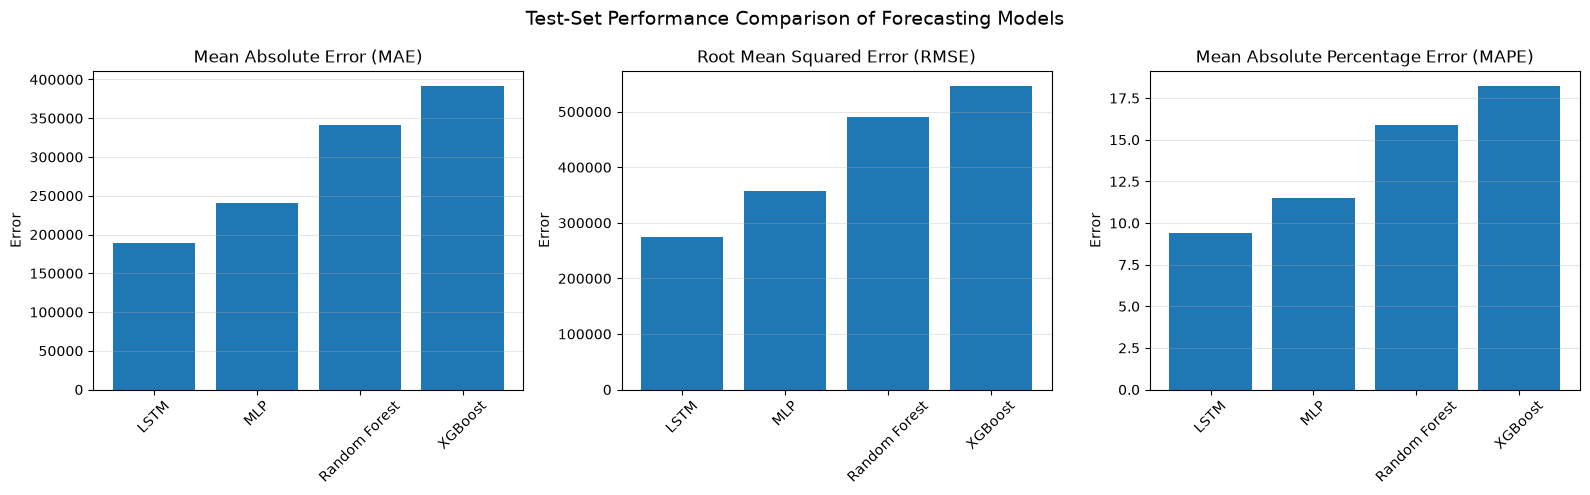

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["MAE", "RMSE", "MAPE (%)"]

titles = [
    "Mean Absolute Error (MAE)",
    "Root Mean Squared Error (RMSE)",
    "Mean Absolute Percentage Error (MAPE)"
]

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(test_results["Model"], test_results[metric])
    ax.set_title(title)
    ax.set_ylabel("Error")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Test-Set Performance Comparison of Forecasting Models",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "32_consolidated_test_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretation**

The visual comparison confirms the numerical results presented in Section 6.10.12. The LSTM achieved the lowest error across all three evaluation metrics, followed by MLP, Random Forest, and XGBoost.

The consistent ranking across MAE, RMSE, and MAPE indicates that the LSTM provided the most accurate forecasts among the four evaluated models during the test period.

Overall, the results support selecting LSTM as the best-performing model in this comparative evaluation. Nevertheless, its increased prediction errors during 2026 highlight the remaining challenges associated with forecasting changes in Ethereum network activity.

### 6.10.14 Annual Test-Set Performance Analysis

To examine changes in forecasting accuracy over time, the test-set results are further evaluated separately for 2025 and 2026.

This analysis helps identify whether the forecasting models maintained consistent performance across the two annual periods and assesses their sensitivity to changes in Ethereum daily transaction activity.

MAE, RMSE, and MAPE are used to compare the annual forecasting errors of the four models.

In [8]:
# Create the annual performance table
annual_test_results = pd.DataFrame({
    "Model": [
        "LSTM", "LSTM",
        "MLP", "MLP",
        "Random Forest", "Random Forest",
        "XGBoost", "XGBoost"
    ],
    "Year": [
        2025, 2026,
        2025, 2026,
        2025, 2026,
        2025, 2026
    ],
    "MAE": [
        99156.34, 268986.19,
        118188.67, 350496.45,
        119362.86, 541566.88,
        132847.77, 624636.69
    ],
    "RMSE": [
        129349.27, 358042.92,
        155735.40, 469989.16,
        157308.91, 660573.43,
        171075.41, 735363.64
    ],
    "MAPE (%)": [
        6.7301, 11.7596,
        7.7766, 14.8746,
        7.9755, 22.9589,
        8.6931, 26.8175
    ]
})

print("Annual Test-Set Performance")
print("===========================")
display(annual_test_results.round(4))

Annual Test-Set Performance


,Model,Year,MAE,RMSE,MAPE (%)
0,LSTM,2025,99156.34,129349.27,6.7301
1,LSTM,2026,268986.19,358042.92,11.7596
2,MLP,2025,118188.67,155735.40,7.7766
3,MLP,2026,350496.45,469989.16,14.8746
4,Random Forest,2025,119362.86,157308.91,7.9755
5,Random Forest,2026,541566.88,660573.43,22.9589
6,XGBoost,2025,132847.77,171075.41,8.6931
7,XGBoost,2026,624636.69,735363.64,26.8175


**Interpretation**

All four forecasting models experienced a deterioration in predictive accuracy during 2026 compared with 2025. However, the magnitude of this deterioration varied considerably among the models.

The LSTM maintained the best performance in both years. Its MAE increased from 99,156.34 transactions in 2025 to 268,986.19 in 2026, while its MAPE increased from 6.73% to 11.76%.

The MLP also showed relatively better stability than Random Forest and XGBoost. In contrast, Random Forest and XGBoost experienced substantially larger increases in prediction errors during 2026.

These findings suggest that the LSTM was more robust to changes in Ethereum network activity during the test period. The deterioration observed across all four models is consistent with possible changes in the underlying data distribution or structural changes in network activity, although their specific causes have not yet been established.

Overall, LSTM demonstrated the strongest and most consistent forecasting performance across both annual periods.

#### 6.10.15 Visualization of Annual Test-Set Performance

The annual forecasting performance of the four models is compared using MAE, RMSE, and MAPE for 2025 and 2026.

Grouped bar charts are used to illustrate changes in prediction errors between the two years and highlight differences in model robustness over time.

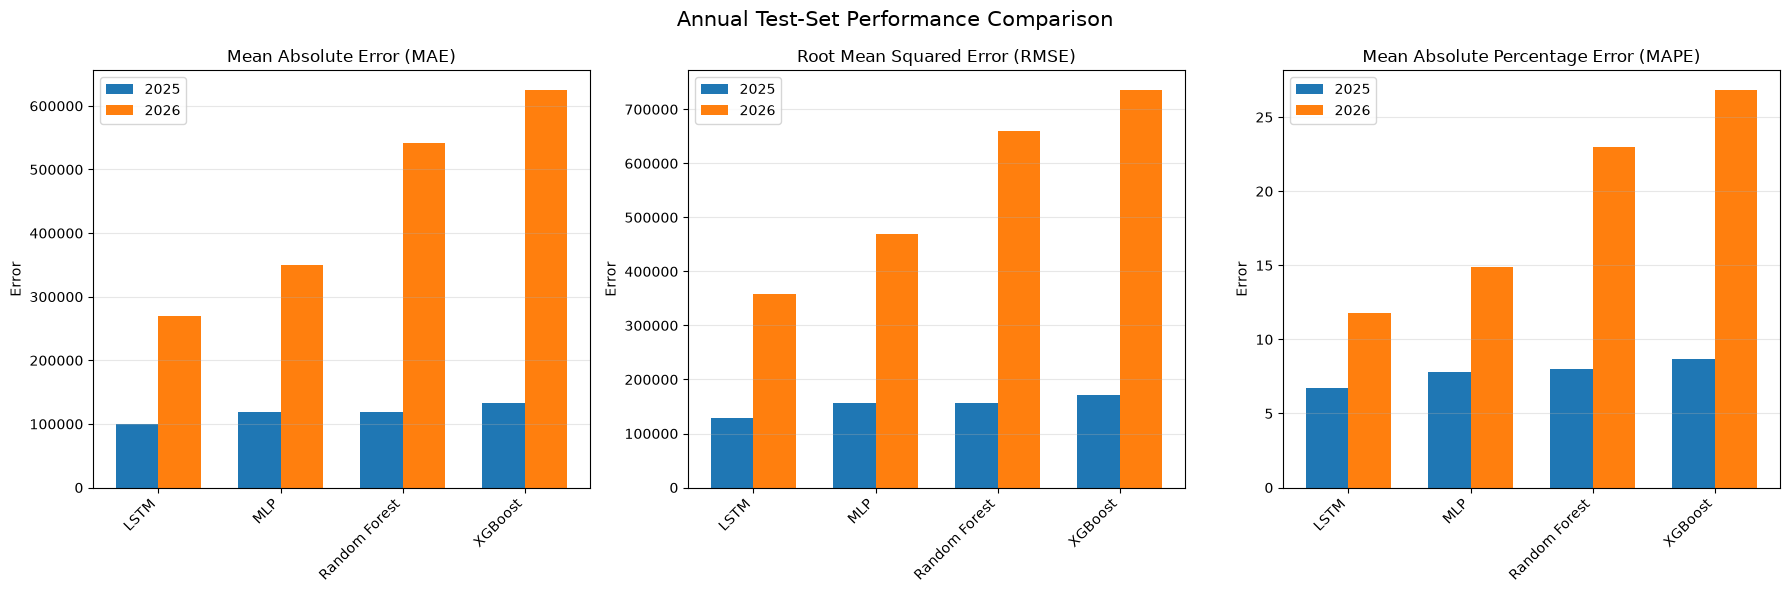

In [9]:
import matplotlib.pyplot as plt
import numpy as np

models = ["LSTM", "MLP", "Random Forest", "XGBoost"]

metrics = ["MAE", "RMSE", "MAPE (%)"]

titles = [
    "Mean Absolute Error (MAE)",
    "Root Mean Squared Error (RMSE)",
    "Mean Absolute Percentage Error (MAPE)"
]

x = np.arange(len(models))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric, title in zip(axes, metrics, titles):

    results_2025 = (
        annual_test_results[
            annual_test_results["Year"] == 2025
        ].set_index("Model").loc[models, metric]
    )

    results_2026 = (
        annual_test_results[
            annual_test_results["Year"] == 2026
        ].set_index("Model").loc[models, metric]
    )

    ax.bar(x - width/2, results_2025, width, label="2025")
    ax.bar(x + width/2, results_2026, width, label="2026")

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha="right")
    ax.set_ylabel("Error")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Annual Test-Set Performance Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    visualizations_dir / "33_annual_test_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretation**

The annual comparison highlights a clear deterioration in forecasting accuracy across all four models during 2026.

The LSTM consistently achieved the lowest MAE, RMSE, and MAPE in both years, demonstrating the strongest predictive performance. Although its errors increased in 2026, the deterioration was considerably smaller than that observed for Random Forest and XGBoost.

The MLP ranked second in both annual periods. Random Forest and XGBoost showed the largest increases in prediction errors, suggesting greater sensitivity to changes in network activity patterns.

Overall, the annual results reinforce the conclusion that LSTM was the most robust forecasting model in this study. Nevertheless, the deterioration in 2026 indicates that even the best-performing model faced challenges in adapting to changes in Ethereum transaction activity.

### 6.10.16 Summary of Test-Set Evaluation

The final test-set evaluation compared four forecasting models—Random Forest, XGBoost, MLP, and LSTM—using a rolling-origin one-day-ahead forecasting strategy over the period from 18 March 2025 to 17 November 2026.

Among the evaluated models, LSTM achieved the best overall performance, with an MAE of 188,525.83, RMSE of 274,566.22, and MAPE of 9.38%. MLP ranked second, followed by Random Forest and XGBoost.

The annual analysis revealed a substantial deterioration in forecasting accuracy during 2026 across all four models. Nevertheless, LSTM maintained the lowest prediction errors in both 2025 and 2026, indicating greater resilience to changes in network activity during the evaluation period.

The results also highlight an important distinction between validation and test performance. Although XGBoost performed strongly during validation, LSTM achieved the best results on the final test set. This reinforces the importance of evaluating forecasting models on previously unseen observations.

Overall, LSTM was selected as the best-performing model among the four approaches evaluated. However, the deterioration in 2026 suggests that further investigation of changing network activity patterns and potential structural changes would be valuable.


## 6.11 Discussion of Results

### 6.11.1 Overall Forecasting Performance

The forecasting experiments demonstrated differences in predictive performance among statistical, machine-learning, and deep-learning approaches.

The seasonal naive model provided a strong benchmark, outperforming the non-seasonal ARIMA and the evaluated SARIMA candidates during validation. This highlights the importance of weekly patterns in Ethereum daily transaction activity.

Among the machine-learning models, XGBoost achieved the best fixed-origin validation performance. The machine-learning and deep-learning models were subsequently evaluated using a rolling-origin strategy, in which actual observations were incorporated into the forecasting history after each prediction. Because the fixed-origin and rolling-origin strategies represent different evaluation conditions, their performance metrics should not be compared directly.

The LSTM model achieved the best overall performance among the four machine-learning and neural-network models on the final test set. It recorded an MAE of 188,525.83, RMSE of 274,566.22, and MAPE of 9.38%.

### 6.11.2 Importance of Weekly Patterns

The exploratory and stationarity analyses revealed important temporal dependencies in daily Ethereum transaction activity.

Weekly differencing produced a stationary series, while the autocorrelation analysis indicated persistent weekly relationships. However, combined first-order and seasonal differencing suggested possible over-differencing.

The results supported the use of weekly seasonal components in statistical modelling and lag-based temporal features in machine-learning approaches.

The performance of the seasonal naive benchmark further demonstrated the predictive value of recurring weekly patterns.

### 6.11.3 Comparison of Machine Learning and Deep Learning Models

The comparison of Random Forest, XGBoost, MLP, and LSTM revealed that model performance depended on both the forecasting strategy and the evaluation period.

Although XGBoost performed strongly during validation, its test-set performance deteriorated considerably, particularly during 2026.

Random Forest showed a similar pattern, while MLP demonstrated comparatively better test performance.

LSTM achieved the lowest test errors across all three evaluation metrics. This suggests that its recurrent architecture was better able to capture temporal dependencies in the evaluated dataset.

However, these findings apply to the selected model configurations and experimental conditions and should not be interpreted as evidence that LSTM universally outperforms other forecasting approaches.

### 6.11.4 Changes in Network Activity and Forecasting Challenges

A major finding was the deterioration in forecasting accuracy during 2026.

All four evaluated models experienced increased prediction errors compared with 2025. The magnitude of this deterioration was particularly pronounced for Random Forest and XGBoost.

The annual differences in transaction activity and prediction errors are consistent with possible changes in the underlying data distribution or structural changes in network activity.

The observed deterioration also highlights the limitations of forecasting models trained on historical patterns when network behaviour evolves over time.

Further investigation would be required to identify the specific factors responsible for these changes.

### 6.11.5 Limitations and Implications

Several limitations should be considered when interpreting the findings.

First, the analysis focused on daily transaction counts as the primary forecasting variable. Other potentially informative indicators, including active addresses, gas usage, transaction fees, and network events, were not incorporated into the forecasting models.

Second, the neural-network and machine-learning models were evaluated using selected configurations rather than an exhaustive hyperparameter optimization procedure.

Third, the study covered a single blockchain network. Consequently, the findings cannot automatically be generalized to other blockchain ecosystems.

Finally, the deterioration in forecasting accuracy during 2026 indicates that periodic model reassessment and retraining may be necessary to maintain predictive performance as network activity changes.

Despite these limitations, the comparative analysis provides useful evidence about the forecasting capabilities of statistical, machine-learning, and deep-learning approaches for Ethereum daily transaction activity.



## 6.12 Conclusions

### 6.12.1 Main Findings

This study investigated the temporal characteristics and forecasting of daily transaction activity on the Ethereum network using statistical, machine-learning, and deep-learning approaches.

The analysis covered 4,066 daily observations from 1 October 2015 to 17 November 2026. Exploratory data analysis revealed substantial changes in transaction activity over time, together with temporal dependencies and recurring weekly patterns.

Stationarity tests indicated that the original transaction-count series was non-stationary. First-order differencing produced a stationary series, while the autocorrelation analysis highlighted the importance of weekly dependencies.

Several forecasting approaches were evaluated, including naive and seasonal naive benchmarks, ARIMA, SARIMA, Random Forest, XGBoost, MLP, and LSTM.

Among the statistical models, the seasonal naive benchmark achieved the best validation performance. Among the four machine-learning and deep-learning models evaluated on the final test set using rolling-origin forecasting, LSTM achieved the best overall results.

### 6.12.2 Best-Performing Forecasting Model

The LSTM model achieved the lowest test-set errors across all three evaluation metrics:

- MAE: 188,525.83 transactions
- RMSE: 274,566.22 transactions
- MAPE: 9.38%

The annual evaluation also identified LSTM as the best-performing model in both 2025 and 2026.

These results suggest that the LSTM architecture captured temporal dependencies in Ethereum transaction activity more effectively than the other evaluated machine-learning and neural-network models under the experimental conditions of this study.

### 6.12.3 Research Contributions

The main contributions of this study include:

1. The development of a reproducible time-series forecasting workflow for Ethereum daily transaction activity.
2. A comprehensive exploratory and statistical analysis of long-term transaction-count patterns.
3. A comparative evaluation of statistical, machine-learning, and deep-learning forecasting approaches.
4. The application of chronological data splitting and rolling-origin one-day-ahead evaluation to assess out-of-sample forecasting performance.
5. An examination of changes in model accuracy between 2025 and 2026, highlighting the challenges associated with evolving blockchain network activity.

### 6.12.4 Future Research Directions

Future research could extend this work in several directions:

- Incorporating additional blockchain indicators, such as active addresses, gas usage, transaction fees, and smart-contract activity.
- Investigating the effects of major Ethereum network upgrades and ecosystem developments on transaction activity.
- Exploring hybrid forecasting approaches that combine statistical and deep-learning models.
- Evaluating adaptive learning and periodic retraining strategies to address changes in network behaviour.
- Applying explainable machine-learning techniques to identify the most influential temporal and network-related predictors.
- Extending the comparative framework to other blockchain networks.

### 6.12.5 Final Conclusion

Overall, this study demonstrates the potential of data-driven forecasting techniques for analysing Ethereum network activity. Although all evaluated models experienced increased prediction errors during 2026, LSTM maintained the strongest predictive performance across the test period.

The findings provide a foundation for further research into blockchain time-series analysis and the development of forecasting systems capable of adapting to evolving network conditions.


In [1]:
import sys
print(sys.version)
print(sys.executable)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
E:\DataScience\Ethereum_TimeSeries_Forecasting\pytorch312_env\Scripts\python.exe
